<div style="background:linear-gradient(145deg,#08080D 0%,#121024 55%,#1D0E2A 100%);border:2px solid #FF2D95;border-radius:20px;padding:24px 26px;color:#F5F5FA;font-family:'Inter',system-ui,Segoe UI,Roboto,sans-serif;box-shadow:0 12px 40px rgba(255,45,149,0.25)">
<div style="font-size:11px;font-weight:800;color:#00F0FF;letter-spacing:2px;text-transform:uppercase;margin-bottom:6px">⚡ MUZA PROJECT · CYBER-EDITORIAL ACADEMIC &amp; JOURNAL ENGINE</div>
<div style="font-size:32px;font-weight:900;line-height:1.15;color:#FF2D95;margin-bottom:8px">🚀 MuZA_Search v1.1 — MuZA Project Journal &amp; Academic Search</div>
<div style="font-size:14.5px;color:#E2E2F0;line-height:1.6;margin-bottom:14px">
Mesin pencari <b>artikel jurnal, karya ilmiah, buku, dan skripsi</b> generasi baru dengan antarmuka <b>Cyber-Editorial Dark Neon</b>. Mencari referensi 🇮🇩 <b>Nasional</b> &amp; 🌍 <b>Internasional</b> dengan kuota <b>PAS</b> → memvalidasi isi PDF dengan <code>pypdf</code> → mengekstrak <b>Tabel Sintesis Penelitian Terdahulu (Bab 2 Skripsi)</b> otomatis → mengemas PDF &amp; sitasi lengkap (Volume, Issue, Halaman, ISSN) ke dalam <b>ZIP siap impor Zotero / Mendeley</b> &amp; siap diinjeksi langsung ke template Word di <a href="https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS" target="_blank" style="color:#00F0FF;font-weight:700">MuZA_Skripsi_Builder v1.1</a>.
</div>
<div style="display:flex;flex-wrap:wrap;gap:8px;margin-top:10px">
<span style="background:#181828;color:#00F0FF;border:1px solid #00F0FF;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">🌐 5-API Resmi: OpenAlex · DOAJ · Crossref · Semantic Scholar · Dorks</span>
<span style="background:#181828;color:#FF2D95;border:1px solid #FF2D95;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">📑 Generator Tabel Sintesis Bab 2 (.xlsx &amp; .csv)</span>
<span style="background:#181828;color:#8B5CF6;border:1px solid #8B5CF6;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">📚 Metadata Zotero Lengkap (Vol, Issue, Hal, ISSN)</span>
<span style="background:#181828;color:#10B981;border:1px solid #10B981;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">🛡️ Anti-Piracy &amp; Validasi Isi PDF (pypdf)</span>
<span style="background:#181828;color:#F59E0B;border:1px solid #F59E0B;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">🏆 Filter DOAJ / Core Journal &amp; Anti-Aksara Asing</span>
</div>
</div>

---

### ⚡ Cara Pakai (2 Langkah Mudah):
1. Tekan tombol **▶** pada **⚙️ LANGKAH 1** di bawah (cukup sekali setiap membuka Google Colab).
2. Di **🔎 LANGKAH 2**, isi **judul topik**, **jumlah referensi Nasional & Internasional**, serta pengaturan opsional, lalu tekan **▶**.
3. File **ZIP** akan otomatis terunduh (berisi folder `PDF/`, `01_IMPOR_KE_ZOTERO.ris`, `02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx`, dan `Laporan_Analisis_MuZA_Search.html`).


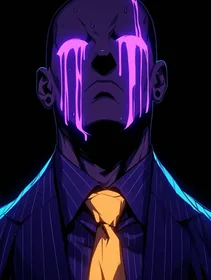
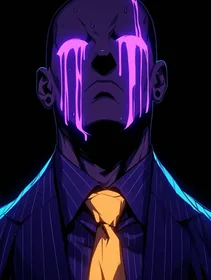
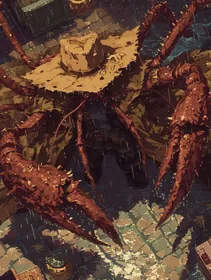
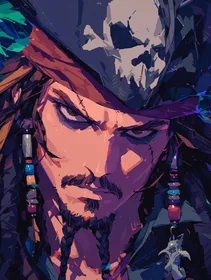
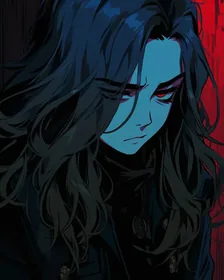
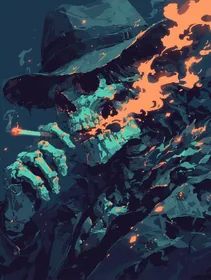
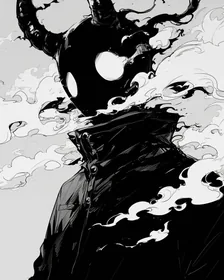
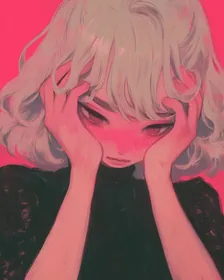
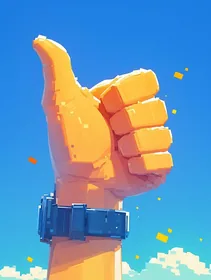
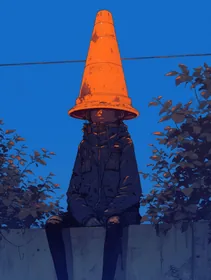

In [1]:
#@title ⚙️ LANGKAH 1 — Siapkan Mesin MuZA_Search v1.1 (tekan ▶ sekali saja) { display-mode: "form" }
# =====================================================================
#  MuZA_Search v1.1 — MuZA Project Journal & Academic Search Engine
#  Cyber-Editorial Edition · by MuZA Project (Muhammad Zidan Aisar)
#  Fitur utama :
#  1. Kuota NASIONAL & INTERNASIONAL yang PAS (tidak kurang, tidak lebih)
#  2. Filter anti-kebocoran aksara non-Latin & opsi jurnal_intl_indo_sebagai
#  3. Metadata Zotero (.ris & .bib) lengkap: Volume, Issue, Halaman, ISSN
#  4. Validasi integritas & kecocokan isi PDF (pypdf) + efisiensi batch
#  5. Multi-API Resmi: OpenAlex + Crossref + DOAJ + Semantic Scholar + Dorks
#  6. NLP Morfologi Bahasa Indonesia (peluluhan KPTS) & Academic Stopwords
#  7. Auditor Kualitas Jurnal (Core Journal / DOAJ bonus & badge)
#  8. Generator Otomatis Tabel Sintesis Bab 2 (.xlsx, .csv, .html)
# =====================================================================
import os, io, re, json, math, time, html, base64, zipfile, shutil, datetime, unicodedata, warnings
import urllib.parse as up
from concurrent.futures import ThreadPoolExecutor

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
for _pkg, _mod in [("pypdf", "pypdf"), ("PySastrawi", "Sastrawi"), ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

try:
    from pypdf import PdfReader
except ImportError:
    PdfReader = None

try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    _SASTRAWI = StemmerFactory().create_stemmer()
except Exception:
    _SASTRAWI = None

try:
    import openpyxl
    from openpyxl.styles import Font as _XLFont, PatternFill as _XLFill, Alignment as _XLAlign, Border as _XLBorder, Side as _XLSide
except ImportError:
    openpyxl = None

try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

WARNA = {
    "bg": "#08080D",
    "panel": "#12121A",
    "panel2": "#181826",
    "pink": "#FF2D95",
    "violet": "#8B5CF6",
    "cyan": "#00F0FF",
    "hijau": "#10B981",
    "emas": "#F59E0B",
    "teks": "#F5F5FA",
    "abu": "#9696A7",
}
WARNA_KAT = {"Nasional": "#FF2D95", "Internasional": "#8B5CF6"}
IKON_KAT = {"Nasional": "🇮🇩", "Internasional": "🌍"}
WIB = datetime.timezone(datetime.timedelta(hours=7))
MAKS_BYTE_PDF = 80 * 1024 * 1024

IKON_GAMBAR = {
    "hero": "data:image/webp;base64,UklGRrIcAABXRUJQVlA4IKYcAADwfACdASrTABgBPmEskkakIqGhKNRqaIAMCU3bq8pYjgwu9+984vkXtu94/efOL2YdkeYR0h5//+N6xf7h6hX9d9OHpK8z/mnf9P9sveJ/cfUH/n/+u9Z7/v+zv/bP+57Fn7RetF/8P3M+IH+2f9D9xPaIwhZuPh9xlnsvyf/M9ifbL/IeIvld2QHib79qy+IOiX/jeTr9Q/7XsCfzT/D+sj/s+Y3669hXph+TAZpf5c33iqWTq/2TRGPM7Jsc0HOk/RiiP4DHk5Y6yXm5/rwIMv2sroYW1JtQ2EIqKnGbiTrgFR8rawmVQ3YqDyViPx3TmU+PdS82Hn+TzZBssvkwYBq4o+w6qTDPRYD8h5csiPdRKjDrCGRm/M6Wauq1naeW++Hn8CX2THWNVA7SHNEbR3AekKtCOzHgJNw2FM7UojEvKxJhPB9+YtBZpeDUEZXksfnwztyoAZPHtvLDgDoMJSGlkaSGL90Rm4Up4oPEv/Qjnly7SlVs+MiACU337aQoMbve/AJPeiVyycYtinOW8rPnTeV5Ktz7LSLhAzNAMHpltIivU0gstED/yDEt6KIjhLf8l/pAlZzzQPvSkJdctSdUrFOHxWwRIB4ZMkhn0uYAViJmcU2BrDlbXQzcee1Gfz9w+0nonKC02vUP9Fp0cYXsJeKgOWQpoz7uS+8UV588OQR5EhcUgvtzIP6LqxdSMWieUWQaydWotZHSu+Uhw0gRRMhhVUZSJsG/cohpUIQhSbiIyYGFp/fNqZN88BYjKnsZ+35BeNat2+ZlSIYQD9qXpyUUXYHysZa7h3Yws036TobhtQe/UTqU6t+jdug8qF4Pzxk8cKsPYAHc3+S+CP7leyqV3BtHuxlQLNlXvdWZinaGskYVom4RctRv7+tPgPr8o15d469+X2jNXWRDPofIdrWdLu+NTNEyfqBm9nw9ADurP7EusM7Qu4suWWbtMI7laXL/+zH9YF5WF4QL45xT62v6Kcaev7xy60mJ4O/QUsBmzcKNLaf4Ewn6J7aR/eHjaKcFvn24hLpUNkcbyVScacXUaN+StRfTibVwjYl5wxedWQh/wLXn1RXPwoiQubAPm2+trOVAtksSF6RR88wFaNTTpThJYX3c7bfSNChMdZDxZ8c1ToAsFUlg+1SsplFB9Ts0ode5Wo5srWJiEdXqKVM9hIL7HxbmjD6oTvoF5rZO9/zCIz1ERDZg3MKELq82gSSk95XqhE6VrUk5ocovMmSYGuhgVI/Yq3QaWi5rHHfy+ayBnl9oUnjI0iSqGA+OC6v6Ujj0ts9t4litgOPvJpxi62mdq5cw+67ULQdzZOM3sAZRhW4LQnpP/AwA/v0n4dMp8sGv62E3FBFPhRdqfkiUxeZmJilu+Jte1Jf+hY1kiUdpdX/Mr/SmyQ9iUpOfzn751KwABoNjO/mctvjnIMqLPXZJerCy0zKHFA/Slgn0Ltz5203mvscS3gZhKi/c1L/yPDwYB4JcI49GNcYvkTGMNfeLIMPgt1ucA6NhKj5ZtRNCCKf9rUXrjDPUmC2NqmAHSgwr99BeuuFPUIT8H08Qme3QwAbB+f/oeeOtF33kEb1dIW/mH/MtL0KIOjFy7y7CJjJA8Py+EGlEpVyIyQTGk/ScbMwWsUAFudtUX1Pw/HgU5Xxdf2wWOUgYLjeqxN9GtsvGAWVkg7SI6WF4AAeldhw8XCinGjpgh13TCqmfl4lntYkltoi5G8klgrBrtgIFr4H/71+d3xQF8iaJGd13/Iux+OsxTsN8Al8YdmFOopUg2KDHmdkmY+flnSAIVK4jttI+ftT0RNo3ThEqs+PI4BLGC2o0sKAAfnXAZPmlJC5c4WIKP27u8hi85iZ71G76sTrOPGzuLpT/udFX1TKpAJx2PIaSrWYY+TR2J2xkQhBTgxqca938NWS+W35M+86KU+v8yATLxFUm8NFMcjsqvo45A+PR4Zv2DodjZXTzwFL/x9OWjWKTsbYZhm0txgAMciU66gVDjM3QX3Hr8d6OtjTdU5CBmimXAi1aqcbLdXnK43L2e3RIlQxrRW59zh1elt803iDr0pWB4oNU1p/eSq6w66q6sL34RXSpYAtEOkmP36LtUGJ0YnKDOOvd72kemgMU2EAI6F4vPmxRtuHGKLDEfJKai7ONey+9zL11xmytvEKfqI4cgDRE5o0UxyCyp4b1II4AlU6JUHp3ofn97SFoamWvaNWHSxZOdtGNFhv0sRPbyCLaOtxgLqm6NJQdy8DYMsAym0AQj6nwiPj0vBCWKc0HPahRN5+goXTF4h8CmAojAIc8369jBUbAQErwTTzMJ+3iaLoiAGjv4U8/3/gd+0NH5CkIOJEZEoP8CJm8pFYu600kdH4lsKAcMYtp85F64tLdho9aH/A9HoyH0e9vcFwyJqoBwBwtFXYg/JkgS923ViLHy5NSnBrZFubrqWHtSZ0Dqm03qja156/jp0zuCNMh5XnQcnJPTBtM4sL/hBZsQpSdYG38mXCSZi45dCAEYtIh/0WqiEjcx8TPYmfgOK52nQYgPelTLp6aEyppFlP2WkPo4A+5EOM7Cm4roLqAAaZo+Kphq1DhugkLNhwJBqpGbIKMJqBdrY+hzSsHJJqmLADbqyDUBQwmw8g0NDo5T20D8icuU6W6fQ/NYL+RTI1o+VBHg9T9asK6m3Yvc5oPS5kownRWMmRuS63M0USrf6WYy32mqwdLOMWx+ACeDLs70LLWM0CkfZ4LnxcRFF1mXhUf5kWFQ2buCZ0+eyqCGh99ze/I8LVo+PRUFtKV7IZ1DCNTxQn/r1kDQ3GJNvKJYOxWlRbT8cVh9Sju9l2Aolj4zbz13kFeAwchzOIgd0BpqiAY+HH8qzjYrvqZlNdATfXe+UJmES1w3pigagVFsKjuo5eU4gFRzPuKtBGlLwjNvlknD1oxn2ji3CWbc82dYjpMZzMj/J85ZAJ/0ciYI6dZmAg2Z+RUCw56+bKel4HwQaurNIXRcqw/AkIZLo2g5cbuc2zUKuU9GoP4HhrRILWqfCHIrU4+SQ8pDVapebTYhWYlkSNyx7YQBrDc6JXdLYQfAB5VOJgtu8qFc3EkhcBmLg9PU0HVS9hSYzTVzwKkWIojeJEkFMQeImqMKlep7/d7A/vKwI/EQjzUKK2GV5/fNn8vwVRAhvzSAVy9tvZB+8cGEjaZEc2yOGAppqFUJ16UMF2Ce7Wl7F+cALh8D2HuVQQPwzlWRMk3b6e3d7heTTrrmnWDwL2eGUuf41H1920G+eZoS9Q2lg7L6s36ztt5GDKDCEuoUPl0IQ2Wc06NuqJzq98h3MHSOhQ/4DHQbKc3Py3WhC+hSYP7SNzWP8Pzcm8KQAnPCTcf9MRD2tnUuNTGc1dA/D4phY4PvT0/teZ048/IpEE1fxMQLHmBW9GaXKY1yU03ArRXq2wSn0e/dXiC6mZUbOCnIpDsB4sAeLIRknGTm+OiF9SaDYq4RkLNL5gguw1BZ/7coyYi40yVb0DyBDndXEGvhD6ARU4aA8QerI1BoIMCLhEkBlHZuYkQ4mAzI8UQybIAA76SoX5ADQHs2QWmP5eO6WSPP4WUyjJSGcqcac1LiBR203W/jkNA4l8Snam4JdS8suUkQDmx5zCs7PbFqpWQslY/JgF69tGFi9eKmdoV2BFsAqprn2Mt8glmprbhZvHoAZvUWqbKmNCTafDwlnNYoOtpSZLDaNIBlW2NyAckrhiJX64BbJCF8K+5+OcjsU2oOKcBrpMi7FdlKdoy1Iddma4Qo+Yq2kWZkc6eKqgOJYYT1hJ9ftWia02NOQPg3xl+HL3A56xBCVFIlaozJPHDFT16UPbP3bfvpMskR/wjDVh73G5zxIUZTlmivmnHtq0iRMZHvKfvDKEN2EaVbAFzx8x/yZpicsEqfes0vP2U/JVRKXQsMB5pzgzaMNtCPQP7G2423awoEfuKRtkGDXosffk5aZ4S8L37a3w5hRo27ilTbEYx87Ver0dGYX22jOZjxaPgHsYpThGjDPBL/ey3IAXfecsoVcctMEppnjrauALX0MnASuneZYUkrW92UezTdHPOUWrrPQkN/2W/PHgyWVWgiahRXnPyun1R23gpBkTOqBdFJacs7ts7vii2KN9H5J7oKY1+W9m1zHvemJU5Yx2u/XOo0CaPxDSpkZpLIurpBcGNU+D/xjhR5mdqe/xRACUZAQAsycHIa073QATfaEGatRkJ318bmfO0hWpO+x9OLlveTmml5/nFBH19cIm2y4rCPlfQqWdXUPK1Yv/qMNVX1Mqf6BWhV/GQ2/5PvtcaKOb41Utz/sxp+huH5YaXryJsFA0haVoUk0XwTylPCo6HGzVlTZ7xdOCZ5crJYkYKLR7z3TyNEe0bGjzBw9cKfSrqz+XPq6gDsG0nVVnV9QL+PKs96kT2orJ6rxrPqx7nWK+a2dhlElrWkXpe9jJpkVhcixG0LRp6twBH6WKScwWzRsJ1i4NUpbSRpGzV41tGrk+eSv27Vs4JyRlDpMEdwAoVqcFO0AOK8uagC1mfxOxwb1o5FUNecQjcPtJP6hqiW+mnfMLI1tuePHgyq8bn3MN6j4pjBBsADi5r+qSYFRvGZiV29u7zxypmBfdSFy7co7D59/wUe2NI04b9B24KTD1ZahWhgM+dzNd9gSYEi3OX55z/7pyB5Na/hWDj2nIehaM6pPdpCipklwy22lb+Fdrl3qQ52xfTSvZ7X78fROqY3dSob0Lxs03WXQbOn+7gPTQHtfVvWnB++jkvwMWg9b/Ay/z4+LxRhwQHSPySljNemmCPDAtEW2tfwGdroOq8c6RQElzDEzdXNO3n4cSc4cIB4kSEysAB3dSnCJIOEBOwpnubQJTejyLO0Igpp/3Gr2TeZo+uJ+byCO/NzEksQHp4ICGFdxDlStHCznzl87KtOS85sLuHNIRCvy6mXNE7M6rRUbtWAncRspI2X+7cpWtBY/qXyLiCq3UmICt6kX75clQB4N38RGPYtZhvbfGvMUA1tOo5T15ElGEE8r2i1IFZw7IbPOwDJCcFJqhlmflxllRX5/mPaZWH717w1AJVDnr/jvhFtN/9ZkPg8Y4NOabm/QtdpsdX2XAVPX5jlhDTDra+FHIKpQACOna7kQBaP8MP8HQNG93/w15UUST/UQhFlGlP1l0LaOLYJauuQ/uo6EGjnEt7bV3zZj7QrPeiY5OPa5/Rjov5vIJiOcmtELzD5NnGFetOzfnyoZ+HqkQIgufkM3cOAPsmKaLysibrmu8clgn+Az1TM9v5gSiABxeGzBgxiqe1coUSP6O4+PH5OJ37zhdgBxNTGq3o1Pbf9+9by79EckbjizXBSzejRAfwtn+UGl0SRJ7NbNjLstrb9dp7ENcxk/uLioTafksa2/n8wmK1ZloFCjul6vjv0CaGmx6nItYBorMHItO4hKr5b76hkeCKoMB4oyYratfhbc79rfoMOD8nt4I190sFEokE/Yu97Wj4Q0S3mG3SM43fEmU8jT5OW9s6Z9pPvEHy5r2Eb3skgffDp6FVhj/mwdBb0rvDPWWfsLirP5uTtSm43CRLaeb9GVxAeoKWBukKi74SK8gOVogmSOxAZwDhtAi2M4isIRaobPrX6IXUhUaWTnm45SmmIPestiu1VwEzDIplGJLP3et/pg0LZbz3b0pRii9xlNOBebU49H3Jt392MnlMwV0D3zXaAQwCVVvbIYgb693Or0I2zLs80aX1jN3kcF+v5WePBylJ5z+3Im19RP1NnkOIsQl+v7HOvf7QZ7SF9O8iGIfOp7Ed3RofdX3xY/p3FPqQ/0nUwifWwGZW9UB9dgqOynmf8KELrLSwkk3I9Kj0oe7/8S90fBfuzBuD/CCxi+GUMbLBztNRaYa4+kBEKDTIOLKtrFdR1M3s5IB8K2ndY1TFY42mlRJkwZgdpmg/TjjRNFc+AvfWFSChui2lmH0IXQqwIdYiwKnDROexHa6Ltg6Bey/2zzdIACjYHgDijLkTE1LOG34RLujf89g75sXyE+pjKCSpiSDgD/pqWSi26i+qDrN24T5Vnv48svDe2VoWjkzn0384ly6tsW4KOgz6VFrphcDSMUheUgHm1WR6PieDlzxJoPHo84JD3hxeCic++jGuRgLYNNP1UzB6Y+DG/Ylf6RhrhO+2n3vT9++VA1U7IAyJ+0aalzvTKBM184uq17DHi8nmx5B3vbOabaGp1PxJ1XjUz0tqEOPum4ADKxeeSEaH9TuV0Cm1f3r4NPNYXKzE5linx/wwlDw+d0ISQV3gckMumkzRmNyzqv/gALHaKN1Aj57/25VS4v535985mBygjZXp8g2Xkqto6Wi7I59Ppn01T7DN5M2Bqfy2zh/+o6SS9E8RTV37j1w3Fw0tf4TyPJ8G/BJEfnU4kVJMp/2uFK/FxZT/bIivsVCw5QIquOHf9RSVfQ8C4b3M9mEYLoTn2fecD35n/yo1F6Og5J7FHv7c74/H9WYXbAhPIFVSQroAH1yVr/8Xw3C3nJGDoE3Di/QPWRW3ASNInjE3nd7Aiww/WPmIrc8uXaMi+rxVZi7EGH692js417ynK8yx9DqKSzH1QyU59JhobMuCjgk+1/naPp5hdtK38jXDSGAStt+PFoocXe4hIAD9UGEIGn0hz9kFQ+eh9zkKr0svmjsNc52hzlxGaXM1Zu3wrly8I2/dU+JY34D4Bv1rj6GkLfugdzaDnf6pI3+99ia+i0x/tKV6NoAfZuEj2QrkoNw63mANwu8KDW3aJ70EGN11DToaCbgy+4FtX8SXeT4o/Rb7a9W/HAqtRxZKBiFyMkUGL5mAp4sURPkE1jcX5DfbcaBEougSJd95G/bkeGncghmEw5Omd1kmHolxj1RorFuWQTy+vlp6Aj5kmX0wneppTwxJicEEdO75TEPfrv7lJ6BoIEvvQLDqBrghqXfOclPAACvu730MOaSDceRGoPXcDXqbKeUo4AIlt4i+w93ItLkDSIvJLPn5mJ8RPVrwP7Ivb///BWNSDv4959mPL7CQtcpo9fW4m7jAxs6U8jeDcJ/aQdxS/DMk9LfU5JN7IaSmhCwqqHhQMOQtvUG1Rydl07E4i6WkIxQZqjg8ldcsmzTxSW+YZWjxfZKFlmVy09AdjpE7kV2zCymHvc/4hgIp5r8rU0aoqz7/L9URyP3iL+vqn8P0HDKy/vVrPK4PwERTbFqQrwa0fvDGBn1v+FTZJ926OkPioONRpsDSZhWLRR05QTer+Ixc3SvBKvwk72J8YweFoo9BGmlfK7scFryiz7HFqQRsizWYnYcs1HcgD7/Ah5rf6Q2Tp47h6f0gqCri+T94BibXnNZ4YbhtBa+Z0/YIT3+U8ZhxUxT66jKArsaMcqq2vO2A0R+5ewLqDrDwPH+a1wane3lLxBmFbOY9u1GW5A1GhiOXWUpWfeg4JQT9BnjktYmxBDWiteR12YblwjHdEiTjXR8eubxYDyQWZXf/ex7rQPLFLo+gVL/U2Ri4TY68sIMW8LlIWsleRMn7QNNuAiPW7NU0kHVPhD5QUy2y0juEPZ7bBl1rfFwMjWIn1vLfDZ1XMV0N5Jo/VowfoljLOfuvfx5e/tJ7X3BJx/bGs01/02MgVJSp/Oq8i5TUhjSqfBexAIXGYez/keuOfzyrZGBMYvc6UCp8bTCXtYouZZpXTPp2Dmyv/mMvjjLe+eDUTqX7SEslckrcZTNbKsDNrU35s5xq6u0dKqeNiwFGblHpM698Atls21QbQwJLThogd2Eqm+mtG3ZnjpfCwyB/Sw87+5mPOb4LqOH7rxw+7gxmYBgT+EFmJ1mAdMQrIXRWp0eOBCqn9R+KaNYBo+6DDSp7sMqZbN+yvL2sQFZ6gmmqxHUOSP8U9BHDT+ODMCnX3sC1LmQq3QPWS2pi5tDva2VIoF+oLFYSbCL4r9vl/WUJpg9Lln98rhfEGR20YgRuy1lbl1GD+OTXWZkR4KOStqPms9LP1/cT1rJ2zPUIjlZa2EF3XUIWsmd5FCqaJ4hWSvglnKAYGv3y6+uzg/ILf8zfNtATe9Tle57QO9NmCXkcd3coMron/+Q5Du6pqPL2TZa1Vu/Mc87nv1+9Qr063lR3BUM8dk9eRJyx2+QzeP2TegOBF6i3sXuHGBQ8Y7gyT/NdAz/wG4hNU4QhJk6DfRed6qQgvFnt0raYTW4leW45Lfwza82IufINoB4cBPRkJTOyu0oRzaMhMFM1beAJFNVxETXL5k/8xPBXl5WEI5of6tMG8Q2jofQMPfplHpslSaR3TYmo2xw3/5a5xrxGeV4yNddFmrglTjatDLWNzxEdTziPEC+QsOZch4CSEJfHyQNCDmaNNw5aP0EyvZR4ztUwd7PeBElk8bGDGXsSOGtNPr2Hc96YfQpvx4Y9FmChK/W5zPAxw9T28unfRVsPXA4zdIDS5YGGl360zcgB+m7vJKo2G4tbhdhWILz1704JJtvvicYrFQZIwy+ZQtwcq/amHOTELup8P/vfhG19E+N0e7i1OfX5Camar58DvdPge6094JOEI7dCMdgv5E3fYQaAJhGVzfDFmIoz9TYdbSUxprCeF6Gj7W8M/YY5tsd8RZgyanZGGIie6QjwMuIqOWkb0bGz8jnKQ0rYFz1Xs1ziYl2+2tHERFSSefTMVs3CAQgr9tKkkXGUuodAr157YaGocD5vnM1AHNhahukV++VXof9Ko5QIVISYgl4dPR0x315Ei3/YGmffQCL+NVs/qLDXs2CgtfdoZ0KjLBDkMYNMJtJ6lablgKX8dTNyoWpQUQXsGZTiOAJbUCbIUFP4N1iDYucVRUI3I+F3Dh4Ry73e+++cNS/2nx+k3x/FduXl3LqagfXkH4u7/NuWbVYqRUbzPFtCqnevby9UTs9UerfQglxpAl09+oV4zjLEvGysLiXY9WEMWDG3ivbew02NaYuUXqhP/oW4qHbP9hIsD4D9Jf6i82w9FuCbD8Ct10ZgdFdhlQ+GPf3bTwKJZ//CJ0PT5r0K+FbtF0V1NR+tRkieQAX1QMFMXWuazT+P3P0rAI/uADraQNR49zRiu1669V0LtpnkRSMlZBk+FoOH9pNSY28yQgn9Ck/86u1fybERLso/GjOYpmmE5/YZZwY3drNrAP9nd5eraVCgCPTdwGhyaNIjM6sNyiFj3YXTG2c+M5WfB81ezxIAnX8y736u8ms09jVbeSZ2DtElkMu/caLLvLkPlumsWAsO24KDWo/eEV4PNj+yFC9VpbPIMHL79vHV7JTTs3uThk7oHzHSRisrIX+5iHiQ8Z9S16oWKCbniwxwNTk+9dnIQifBj1ZM1adTAqIN6adXdxzfLSLKIHAws+m3xfXtldEukD0mR8MD2Eq5Obu4uMlHIKQkZNoL7siXvYnioXM+k22X6q86/NgZNjIJC4aDkob+1+/hApQCRcNTc7Idg7wle32L7BIe+I7AAwOPCjjcmq3u8m3iKf28kzSvh7sNqUgBv+B8+sNzGGMYzBpDkZXOXqubp4RL2XwyAIg0IBkR7UoBpM4e+DVh64i5DGo3EZ2AuwINps0EmRgYwGvHy1cTRAPI7SD8HAjM/gWTGkNIYqjV1c4cI2MRXLTJL8Hb370ZrajeMfhQRjf3iesShQ0FRrozBzJjcNJIm/sEOxn6qpukY1ogOSHWa153F3JO1JbEs2YiIkdSecjwsUc4kE3ucNt4CTJx3h5uOpBcQEkodc0UlZIlV3EQYSzQqG6Cd2dGM3gyFDMU9YLZBU8q9gscwrKOFCTLuoZLO41K5sz704UoSv8jfAAAAA==",
    "jempol": "data:image/webp;base64,UklGRngZAABXRUJQVlA4IGwZAAAQaQCdASrTABgBPmEuk0akIqIhJlKrOIAMCWRu5KgQiZ/VgCrczmSHsZ9gaPDwH5M/kj8zVofwP4s/J75d+R3Yvma8/f7/7a/l7/tv+X7LP0f/vPz/+gT9U/9Z/feu15if6n/gv2m92f/kfs77uP7V6gf9H/u//r7EP/H+oN+0X//9eD91vhS/sX/N/cb4Fv2L/6HWAf//q3+SNs7rY/oLI5y7+X2Ujet9v8Ln7/xP6a3Mp/zfpIaUdRUq4kEcdq9hR5Mvev2NN9Kln5YEn2lY0ZSIwz1smm9rWmTidTB4GRxzgRvvHwSYFlESfPi7ug6ksvvQDgEO+KiOAl8nMxW6LTNEcL4Iw5p6JDkaDNhQiv3/3Hom4aF8ADG1QOwSbaMv8sgt6xmsNRea2MX7TYmUrTuuJ/zFGEwtwh12s/fVFy9m/kW42YqbM5nj38/Qxy6ZC6Az2LYoSJBYYOeiIkyFpcfePRVObfuX0VbvZPh2iRxtpNcHy5DLVz204tyYq5/aShlAK30V4K58GYg/LwGIg8XarGslLxW7FPSzRnIipkjRYwVWzC50nZF2FcMO4tJAUgMTFY6nBylfPylKRmePvX5eA2OH+1NG+YIIeZvl6xet6eHpkP0fXTeJBaKTOg5D3DBEGAWdyaXkIBBE7zxHJSF3EberLwnKLUS7OqCG6nGZ1+dPViHYwQSwZvKDb49/w6G0e0BdVer1UdB6YibSayZYUvJOSqyAe93rT1XsqmUkEKbDdDyph/uxSH3e1wX24UkABT7up+Dnx6rhsDLeWT7kf1SVQ1rw1VsPGtTi6SowLuOyNYVUqCaUzV3lcD1B5xkuStGotW0eAU8Rl0a1YEIJKm9kfshtEpC1+0FcNL6TKMkFdUtCRcB7jBPLD0bRMTajLolhkJTNLx6FC4/c0Q30qCdZuvKvkkAS0pXXEZPhTJzJ4NIv4vhJPTIhP1F6nXsWasI+c74rlojbfev497FxDwfgIej9VZ2cDaYDsSX4pFbkJS4NebmgY658g74a1pl526OL1pIN9WBTRTcDkssuzYRDpZDWHPreb5wYC8A7TYy+Ao1fu7WBr+H/PHE/Qk3cT7PVJdv/iZrn6eGO5Fa4/8aX0LQ8Z8KZIKzD44AA/uuQP+yT458c7Zv/qTK/UgyJjQYyA7rLjJ9VOygAe0+7oj+ZF0eu7GLryDu+zAvD9xUx+xCDmO/U2ZZufMqc/5IAAANvAUviK/ah6x6DKg3sxR1gt1D+LOfAtRZcKQWdRq8rO36KV8qcFGKq8jy0YUGl8O1ickZFituFUtAyGpfSG4Wx8judpoLQ7FTJDo3Jy+n3vpvl+gJU4LWcjR4LdYmg54QWLBwEN/cX6a/zvi+h/oS0u5680uumFN/eK9DO6O4CDJJ4VwGMXk6/m9X4fM0EJtPZCCeHgPvCp4G8oFwcrW451TbogaFQbTH7tacmLA9TcCL3EE5jW08f1hLwIaK3ugE9Gm2UNGjVnE2D/xDbtJxvDN9gbASZf+nioZPrCEPChqny+R+E5H82Qh11AwF8dKcJYq76z1O4SY67KxoUvCcWIJuUvE7OhwA/r4OzqkuAxMIj59X1BtICoK3ppNKHsUheEA5AXM9/5spkYxvdklKA2OShkV28WFYQ4H3/kTyDQ8R2ipq2DcmXBNz5071HCFTg8MCqO7Eik9UEu3NMWJgGxvMhT5dS5blPTo9r6nRExMuL2i6xveoqXUkUt/jnXhB+Fud9MgifV3LiVPKBI91r3xWQUwMcWOly6Z+wJJ7HNdGcz57jP1G2rt+bbtFN64ImknoT5k9eZiLUF8s3muo8yX8qyfKUG98HXdKq39ITi9rXmw0uY/SmrCuPveRxgI034jtRN3a3k5sE/ytuJHDHM9CAEJ3+vRIiU50Q6I62NqRTZzHsgU/lDV4b4LOlO+m3obxd5JK6xojP4RdODMUDD3/RAfD4txyRY6xSHe+HFP/rBPmJfrDAGe8/EYDlcRBL0jB8mTH5ep3Wx/X4pkEVtWDdu2aUizwNgOEXfNCwWSlFL+6NlGDBlWYkxY7zW7U5Zac0bwKGrmh4Tn9+D3IFI8n8XoJ602h3oXMWHkb/rDSS/7jZVPZZAOkTRoLezLkywfdi+DVPITjItMz2hi7efBBDpRvjp002mkRyBGWrkgiLTgUzuW9klLx4GjhkHXoMnuxe3esm6zos8UWv/ouU6Zy3K3I8GMc+XKzz7TkjzsoivGr0dcupJGzY6BU19i+fX+453vwc/twXvXi3ulggOviNIjqwCQA1zclKDtXkWgN4493NMo3o4rSR94CGJaDnDqxMZay8S/+tsARho752lDnQ1Z/YUe3+tfT71jzFOzazdXse6M57UBYI0TSHh7dXtY+n8bvCN9evbafLIICPAQYfEW5TLM+2lKJXL8mbCEQlS/jR+DVDVQeTcPgpKFDsIduEY84ez4N3UTXX5dvPcxFq0SLsAV/fs7yVl5yyhzmBOi6yyWLF0S6rvgyau1dRJLf7UlhAFKYigGH1WfT/d+AHQ/lqZh0PGlu3pbj2dKmN/GgKf15O31c3c/BOwlHy+KrN4VauO1ug/kArZHx+jqTdYAp9JbvZOf6sE2UHCIwxacRMbM/5ZJg0VJnEKnuK8VjBwlNF5ZqJuTIvetUf1WwQvP9nD6uhusbOCdDiKoGX6IIK0SSDjsbEcS9ZgyRY6hBuc7hNBlDEeO+LdPCI5nyzBZzdlUJ9qL/cbtYDUBpKDBruancBE+mK+6lswY8CXf9BDb7mQnzCxGaHXEKx+U0ctTyCx3KPMvjiH0KBbASXZsMCWLlKpUAMDkgPMLWIwBA20S+eLc8w7YjRkHyTtYiSv4aCleiJ9B8letW72mklJQzavXW7yaCXJCPKNey4v3W4nKRAk4OOYZBIIemEbQpXNiYWbYDG7gG4ne+ap7c3cpFhxfpt+zExk9ngC4VEJm5Dp84qN0uupFh52yiBU8Bb46hDBlJEIJWwd9aQOHtMHtHYNGf+M2j+wT3v0oTiKaJobdDhccVErdcQHkll79vCZa66AUibx6V2mcUsTVA4b85fXw90vHhNApgphl/7uxR5OkrNEPpn2InGtD8AUk84lTWwSIK5FAJyPinpNFZcZiZIahg1BcqrRRr3KMfAIHZJqJ3Kf1swxI7K25lLdqlDjLiDetw3Qn42y5GLUzHOwdqoYome4P/mcRCrotyVkxDukKH+3T3nvFU43a89M/w1h3ecQ3Ga+5KMUVdO+rBjdTuqMpxvbzBsvwgvwmKH5+pqxCdPfkBtGiuqCYvAyz81nFENfi0k+J2nKNs+NDSO7C4oKq9AcgPwc/vuekXk9jMPtiU5llUaOOxr2i5Jz+FtKi/XZ5ttPzcr/Hg+lwDElVCYAmDewWdRDblomjt8VYgHtbe8rmTp2jJX/O5ENHrF8Moa3P/JHp7RPl5UZkz3SB6Ik801m+LAfCRExJLnymepWa1Rh4z0FXzScIXJFuofE0tZA09bPsssrUBao9blkZuhYv/Gb/w1JAVXXivV0umdYzl6vpM6WBzjiKGidYk210akxn9XEXgQEoJhiuDDC/KhsDYQ87BTyszM+9SepFIX7q8urw0SpRm68ZR2cRn27i8zinsOnF57pG+mGWKY4CwIxF3/SEsMPm2Ogd/B1W9RlW78tcsH/qvKl/Wr5SBgsPhofTsxuOSeKdi3KLUzp7iswG5Gy6np3z4xByRhHAMPXA1CzQKdDhciKwLAVKiAAfbp/Nv8hUaMD+ag70N/PzV3Sl40mR/zz2Gpa8B7ruEefIax3eeTUyuw3OfDElzE6KMQAHm6vbOBgh9m9CuOAhb7wTYrceClhG9/dTVTD/tksH7sfiTl+PVV2copuVaADRJ93zCLEEvEj4LRG99W3Po6NSzpg30Zf5TxbCkJ17paMZUmyEjeRz7De49zpForBkafzMbEPWJAf/emY27cv5FXPUq/gDHvakJsOxsgo3pIfIZbtwDpkf0VYJ0lrQakMj4wMTKzZhWCh9WfWJ1nH/kSXYOkLmgPnjSNL1ozb0AqGUKe7JmP3fS40VtIdUd+wyNeNJwWSVyxQJw0y+3zSmnuAfAr0TvK+QNEOvYN1foJ3hgOdPywXW05YmhFC6lEPe4j4oB78EBnMdsgF4AlFHBX95HRBBLqUm0FPMOIUsn9citi3eLpv+6tNgPTn2AgjZY0hobIfXkbmUTx00onFvDuhP3PwWn4P9HB1YS5QjsAuz/b+ogIO1SWBzSuts9xwdAxMoTK5jKinzl1ZDOFuo7pbSly4xtxUAlOI23CieGuxxrxGZeaE7ZDyWrvDPnsU4YO0CuBw3ADPyvJQLD3VNxCqXq5Xl9hmdanl11rFsrU3nNGjjZNUjt9JkU4fwn3Ho2kkLIpbVV9b595S2klSoEubmKQWAmf8w/HfmToAAyJBddlWDv3prEUoFc2toLk0l4FJYLOTs5AHSMTZFn/xq3fPyln83FB9ilukWGGqtvgrk1MFxbswPDVebwMgaCXzITX3ZPB7dxWQgEu/xvCtcgUACoH5M8Zp/QwVBxVFE5WSmrzawSbHunbp6XnPeg6R5jS10xDzRoHiFY5wdn02Sz4MuLykeHgLqUdHLlU3Hr77CEFPSzZctVmas7VlOHhoSSNj+/GgVaiwmQe7U9F9MZ1L1b3OJ6VlRnLYYGBPNzDrfgFYATJ5BY5oG1mFVY7s61IPYiiTvJc/msVitdclbzJW9JML68VdCh/63ZoMCeG2e4MgGZzzgL/1E4qn3Qv8maCcJ29PFbN5bpujgkAuBhpD/xdcOIL3NDdLa//q9ZaFMkb5/KAem7LudP1mQ4udoXDZWvApl0G3vhYdVIg8YYzcfp1ZTwoQaq7hS5FmJSThlaOaKfNLer7+AHeRd2LG7dwMvTJG33+6+3Q+HX/zMgFdwIGKhmoYPlJY8sOFvb1iDaii3NyaAnylDVcfwR2SXWxZnNV7Ez/8IRRQvzvy9uwlDDv0tAu2tGifxXNqVkwuMMKiFEDhn68x0bAklCbtNvXUBrPp8xfg8MTV0q6Wexrjq+IGdFz6mNzAbtXF0LMjgB0SHa+cf1TFA3odyLi2CGMfV1o0zzAtgOCbGmlC4Q5CJ5x3+4j2bBJ+Pol0m287s0nvnKL33R1cuUKhy/KDOU9QJ7nFdvE8vLtxQ+6yn632x9GNkK6mXuPiLr9R/zrYgVprZHJlR0S832/Da4hmdb3HSzfNbgF1dmLRXlMVj70wPwSYZS0y7UlWlKwlbEbHAGAVlUL9LSs1H/iOQC+1lvSbEnqHPhl83MiIPw9PCMkJ6xQNcF5lFYvSgz1lRD/1KrSxbHU5qEvDyQo/uZcIc+8N/fJvu7o3WFek1moGYG1/hPQEhr4Uo3VNQcNU/O/kmxj4EcjDT1TzwQNzTJb0MYvH796/sbHfKI3XM9eyzmmgrZQhhpjJmdXCu6TNxUcJwQGpDTs/CyI4strv3gc4v78XJMX8WgSpEaQoJXWgSg9yrO0bW/1jPDPf4//6/6NdTvxYEudXJycpKgrNli4vzebagFdoBt3I54PwBszueYTX3mZ070+UI4MXGTca4C7zImU7KZxGN0WtLKI3RL2ZxmF9jKM2zTUg3+rFNR16d7/pgwDo5fCu/I9EZAG2vqTCDIC43kSEpJsSHz04vdp+oUhQj5GiBzdKjm5Jk8IKryYZ49Tgf/5U62iFf+G4SUrq2QuiRh6O+rbpnm7Dh5ZXR9RTOlHexXoT/hs/g/SqjJ3jPCuENrCJbYHZo/q6ddLF0f4S+cIcFyzmJg957qV9ScpoaDKsR3BIOLsecRNubNOVYCnEN3Kf1ybud4bhXQy+gJfZS0sbQUQA5erd0fINEBjsHSHK6PL7S6h5So+U/Ua3B5yZT3VbkSo3dL1+NY4eS2t+WrKc2xp9pbwd9y7mw7Cd6D8NkeZZRzr3AtFOkH3kEPrAVxh8eEUzvrw2VEMqO5fJGGmQH4+7ldxAeC+Cxgz/rCK52gZUOox4x7RH4uRH8/1D34t+WUPyp1cFTFoHbws1yTU6WjMSJa/O5SPVBfuoYf7kgwchZ5L6Vqn8fZMGr8eJcb639qp//GuanmdeAHeah59v/swGmfpkqIC+yM447CrmdMcoP+XO1gqh5DMWFusCjKbBEfIKX5I1s3lNKtO5hYS6FQexK3M82T8OX4QdpkzxFhu8KzESmlJCHytchvqewIBccWSJcTBl62q9qreGaTwhKWWYJFzW6w4kS+jxPnEvhBgbkG5KGxLwMb4H5q1YE6KZwhuI7Q5CbFe6dnrZMA10q5Bzj/xuxY7jrmE2jUsL6eN8+Eyj3h5u/IkC4Qixl9hHZfy4iRamiwtZDJLY3qH1EnD8xX0SgdXlzgYcS2BoNjusdZ2vrImgytGuaYTCvlhFJHHgJPA9/9by2bVT43xDCTXPQeW+3Wc49R7bKfUTmOpGUjQY8oDkx4gZaSKvTosqxQSbrlGlT4pgLxKKCzPFC5SNWwSFWgLU32yGYpQ9CoPaepcddSC6sVyA/meZNBf5lPvskre/Ex/pic2GOaslCRBKdCNAvJRb/Ee8QbiNKRxbjB5ZhSBGNIDhKz8gMcjdlHXxP6zYViK1kdi4HuoiVKhItMMuYzX4xsprpWn5oDF1R0frxenFj+eZrqK8KtQp1Wdi8Rjxk0BgX3YiXKs04WWDuLQWaj1FpaB9DusrcgE0xTLwVlU7pg6uGVRvYIY23hKC4IAIPX5zH8euvmh/dJLiZmbACa3MG2b7pb6Xgs1u1u+uY9wA3cvFDGMCEGMFFGlJmcnkOM0Lsyid2SPM2F9cN04obCPpkr1L8k/Gf386MUfY2AfI1bsfOhgfcinukRzdPyKajRiVEqXXQ2ORG8OOJ1wcdK9B/iXa6JeABXf54r8WIQOetK1tsDGxXygl+5ZS46qh0lWhaOFRmTOXojQPaEJz60CJX0yf807j15qyjcgm7m5Of6yJVn+bAwO1kzb4g9O1MWD3ob3hUkT9nRUQq1ILi2/tZ+hSX+ccf/UtyPSgq27DUVErlvP7lVOL3JSoU0Gu+BDFFWXLx4//ZRlq8chYcj+9ouU/uFXL0TOxJdFIX62WtY+pWkbI/me8Sa6qFYxWro2pC33nRmOCNp1dVzAio7cPJrujiWz2flaeVaoSTYQ/qsIKUIwODzeAzLHOSLN5T1M2H6H2KcHo4dBYCfz/tN+bEKAQbCCAiOURciXaFovrqXuNOkpQcWO0aVhyNKGxV5WZJ916fzCxsu2fQveLoNduUEMX4rEXgcOmXXbMzg3NWtzv3/hjMVu/PyFWvTRPSolrab5oSVdsvxEPMz6WB9+tdjJ73RvEcvj0GDwgrxqCR8fCFPc7bCsAVcXX+sZJcVQ3EbZrZnZg9kmxVruC3Zjk7oLu/s+z6gNVX689VzLr7TdrCBbWBpHAw0WNNTCUzaLom90ivUYx0GbrGV4wqfK0y9wnlcO05VRuwCmCgbXJwD4UsgXxrk+4GPrDVtezNd3P/8TupGzGfxn5ib06HFwFMG7vP+sZJ5k9JmqZskc1tUD/jrPubooc6ZQhfMFRyBwX0tXMp41MFE69FB/VM0DQXTjr8h6vceTqfh0Y95ySSPVKh/QTXTo/ffych/ymN16Pj0tFtdRTgLerWpzYH79EDZAGcqB1Zp4KXSUWpNRRDa0B7v+RfIMuQYVeT/C+30eaJuTHQ8v8s+/Xh1VNtMEaJ6yBM93JdWGrOs194ESMBSCFeaFOu7TNrjzbz/A1bjYCfwJ9d+ZqLcqIEKlAT6/5Snqj4JqIGjzLtp+0bB/peljowEmAp2nc/JayEokXDj2t9cDFcR5sO5HTv9Ds9Jv1P9Bv8fx/nEc2/rOEHToviFoLWaax18dnvCmOHv3zSl6WW5D7b9v5btaWxQBlnvV/OnZP8XDVSUgH/NZGgZSziMyt7OYT3Iido46kmkbsc6/PUZHkiqOKWYdYmh7hhqPKThRS8XXcBMTP76ThH6H7XJJrIT/MODOsrcdTvV5y4k4DOxFXYMJoAW+4K/kwUX610IeR1GopU29lpEThPSJvboKFCoZGF+kuChrgfrfYtHWORoGhDKvdprAeQEb8K6nK4NRhf+EFSKh2O+sLC7EZZYL7Y5M2fXa6beDFnLYXa3ES5moq7xFCLFm/UHhoezA86MxAEG47wgy8TkrY0QJSEasOWVhjnjodRut7QGWMiGUnsxBVuBJMW2m2BKhX2pkH7gwIy0c12RqbrXzvpLyO94JVEcBqtliMxnwi4G01qOVJ2i8v9lwmYp/eyCCnCwpHYb+N3qdG3SZdMjAX2tOgtGS1CNigejKSrcRM/SffM3OJDIXjIWM/B2DEsp1nmi/w6tihJQQrA1tSKtbYqZPn11N44lWC5Twwm4NzcHdUZTYoCbBA8Q+dFVROhW4u4wcXXJFr/IiKIako7A7sqUfAvENsyjWJbaL0EJrmwBqodEjmNQlGFg3r7KqoG1OPclICD08fipBoOou5iaYKHbLtgdZLzx4a7vnpxmmz2RABruyZtg+ySQIXop4kPl7wy0FNdpx9dXX/vLtCGc/kfq4cJ3MZLKIPBsDWJz3YUDt/TlEHf6rY6enEqOmpItHCJuvIyLWtCkMeebQ9/Fc0a139OH1TW2Et0ZTGTIGpihrHbJD+R2RXEDyhB/rfKfis5W7AAAA",
    "crawler": "...",
    "bajak_laut": "data:image/webp;base64,UklGRig4AABXRUJQVlA4IBw4AACQwgCdASrTABgBPmEoj0UkIqEXajbIQAYEsxuAAdGMA5quQ/QX8n/E+jRyP26/QvwXnL7A+2PNJ6h87v/D9Wv9V/3/sFfr90uP3k9Qv7g/tb7u3/e9av+N9QT+5/9frY/QX85P/6+zX/c//J6W/qAf//23eCP/zHol8fP3X5Yefvm7+SaH+WPs51Pvm/40/k+s3+47/fm5qEfmn9X3iEAX6b/ifAt1X/FXsAfrXxj3r/sCf0j/M+rl/r+S37F9gv9jOuP6Vyfr1jsjwxxQuDfcRobrCLvTs1Bb9ed+p9e1jNmhXxtQXrRiyrg9CY/CpuirRY4uUhzCP5+MJKb7yMLeHtjWy492iNK1WDMWpDHbgmqFvkUvAbgJ2xKNmlk4IDqA/RPWFf/teZbwMr/uB6MaOAwiLDwkBDRoPk4JNW6K7XgOAbA9yLLu8hhSVoVRMXkN/XXdoFMM6Xk21eST7MNjGtfFVGtD2g8FuPFJ5r37iqlaJ5w0Zgzkg4A8H8JHJo253EjGt2rsp10QlszVXrLW/p1OwJZ+LDFjmAvlGL5G/5ZjFUpK5xmUQO+yKVadORAQMlhuoHV/KYl5rieudTJnoaP/vesE/H9Z/NDmaIWtMFjgWEbXJOAcJO7cKH7Ye0svQiBAl4IWhWL3LEGi1KN8kPffOPq//+jKF9ZOcQgI5/GyadWovnB4vhOiD+RuDjS15Sq9RP52tKQYpMQQyec5mbXW+kGydB3jTQ/WwzIpV/c21YesXmiSgyCqbE5FFEB6TzwOrGKlqdW1RE2Xc8g17HU5wpqTokzoLXn1C8DuPxVb0jo/nYdjIxNAK6Xq1oNijUsQ3sCB5WI06vOmnEk8cloRaHxG8LfE6hYs/8J3YAuwl7lFjXX9vihb9b0hftoOpefkBjLobahrZG3Sb/vRIB0ik1vvB0G+vIyMeoK3vMkuWXuJNpE/+jdSLelrSeB+/7uZq9ZmXC0+bRHJRhn5iOeZwvmgxvG7LgYKzPm4g1KtW5x8hur8kW124gOsIb+F+/NXi7yiaeXlTvXv3CHcT/uUqFfpJXyllEai40XzQyiEgT91yiMdvca1BFRBiquZv1KNvHKJFuFM78UwJCDAymvRmbSVz5vwYWY7piS9U8txktubh03Kz1cVlosvbynmO8EXwu7hKXGiySHxf5PL81W5cb0RAJ5JvmI3wZb2ApPWod8ye1gVLnwrkZjHH2eDNjdwb/xG0hnZ7slAXbIfvByC2mn2VcYf2FZ3xk9fiKTK03IpIgMBwYY2iO/UlZTdV491BBzPB4C6h7UoaN5CiYWLn6yyx1SX7pwHE9aVznuw/Zi5sWIpyuFDltof5FP3i1JRzvn3CyY/SEyJuRz9ZWG52oYizlU6di2nGpUPEdJkLdGm5TBehLbVdK/ZE4nn49mcFYZdNG0OiDqKNEg5pVCkbOxx98iXEhMR9wKct+pIu38InjgHN7B3dMT+RA9HozBcsysjP7VJ1cQcnGZfptq8K0PifFqHS+jUkYJ+3n77kXMCLwzihKlH40V/yPqSvdDMIQiSl6Hv0yQGBm+0A36kTggGeK6pe7Y/SfEQErioQ5jz4PLRDWhsRjHqjnN1wpD6pTDJOnMkGvhMfHCJ+0o3OBrZ+bxg0zyGY+KLu/R2Vscn3g2ckZEZfiWQCT/qlYcLwUJYMwyt30mf4VO45NKprUYq+vS2rEUUJWyZkYVD9qbmvsVSEP5cfIAafX8xyPrMa8tn8PU4qNgfEGCPUr36tkPB1Ru4+kN2jx0Fac8oetjk5amein90OfDpjzQkodPVLE6rXr+uLyNy7wgamz51STXLCgTS6BRftxS1zERn7jLJYyqfUQNIKaedzSn9mlHdH/FRxKf6zPv4tmpS6ovFKmEm7LiZLPiUWnpOvd5+yorLTA+uLzcL/y9lXdEOexEzokAFidsnSXiIqYwQFARZmDkE5wBqtfxyXtTX0JoLrx53CeMHXPwSUvJfS4QfyN7jrfl2AEWQ/1jwn04fEBdJ370M1JXqzD8AA2mNqe3CL5x/K+BtJY3jT0/DgEOyftYRpDJJ0mAI4aCCRtrngLx5q7pIrI4/dZ3YAAD+7PPtFVTwYCJAD8wCRgq6m9LTNktsp9zAN+U5NCMw07cYNUL+lHTM7kGcv8W0ooACynf/RkLmw+f2eplH/lf9c2H+ly8NM995u05cP6dDJUa3TKl9VN2fU127y+0nJhlCSAYFkBFPI6hGJWlQL1xUtUzVCbC8j9SHnp3U+nNzbg3DWXiECByVDRIXQxxiES1cmldakLTaQfTf1lBYx5GdnIjqHyJwNNVaCsP924ryC8LllkZqU962Ohh3jtPwc7B0tDtFEeoKHze6Prh6mjHBsiGOpHLuIutydtFwbZDCABC/efhkei6F8mkc19Mf0Ala88QjPK+k1Wehde8dnpGYsvjJ/++08/2/DCuiX4/i1ZYt/Ob/E4cv8C3ckYp8ocIAdbL1pL0ZfT+X0Y2VsTUSZAO5q6k/7/STm/P/4QO3Lf8x7f2e9cA8ndgS7136/3k2wrsKxHT5T7XoG24HyEbRvV/5Kf5r83ihUSwBMwjzxSkW3cZ9BqNJvtuvQOlLtir+4qvXscdXDT7oWEkLUp3EHR8GADztFVY8d4BfTU3yV0boEm3P14nZPGEh4l7kQnY3u39AA9DN/GQ2btIuPwKiW8Ej8chlGwf+Ej8eeJf0gFU71Al5jwLPNfICqq3/b88MR9FY5PBdau4gCMfHbrWLxaq+qBWB5KwkMN66LRIK/7AvX6qo/Y7UBiG2bIpsUaz4wM/uozwlUEwwsnCVRv4hBjMLtkmFB9SWO1iVX5sySDtMcLZOA+6JM5joociwuN2I8RiCCf1i4FTyupv3sIFIBIReL9OrRCi84OHqI9+F+E0CjKw23ysqbHl4Y8hqH599vQZkrQKnXnLfIIScRjT+yWOHkaI6UTc1f/fnEKOD+nU4lXSJiKAVQW5hd3I8FCXy7ya8UhRH8NI4UEUmdQVQBkitk2h5uMysIPadUcMo96cIC/5G8TwAq0Tq5LmdWY2/nBUbJDFO6Sm2mOTt2PCui9abx6PSiDXFRlTnO800Ddwvm7Ha8pZlmfiCP7i5dHgUFhcCOe8bvxChQjcw18J+FvCKEeEr8l1hTbZIWnn3jY9fhvtsoPOlKisn9EPoxe4E7jlOIZI4kcVwcmPK7kTzsTM/LGwJqrdF3pgL1m/fz9lwqVEiJKw4/Fdbbfiin+dbSOphMiCh51bjlRxfgaY03DJxn6cNJXud+LDTFzo/RSB14Cn7Og2tLiH5RvywL1xPx/J4KTN+SWDyP+1E6dsUxHDSYtI0QnDm6zQnSqCfNosyJEdS08NlsowdZNsaw9mI7FU3xoDh7dlYkk3l5nsa2yJFknHcfnTXeZVficxr3yWAyfwGo2VYzQh7RvNlCuBJgBRGt7f2YcdWzwwv6KI/S+8rBK/fm/Ag5J4LmlkoI1B78yoUEem9YmufA8gJxbEEGpDHwW4+m2bX44Fx31hrHPqOxtkOnKUJ5DT5hMSNOEM+cRasu5WGAGHh7yzye/ct4eoA4X/+SA2hNdgZF4XY+9X1eH/hzR3CVNUoPin6EUuuBGLj9zyXtyWOJ6XN/qhYwTyPEetqSDlTVHVIIiOfPenXeiSxLeO31bIfyZfLgoOsBkpf/Cbff5nzUnvLWK3bwoSIMsbTJOqbFtBq7A2EP7CHN+AxOiUpg3+boJ5IjxKfeh56yG3kE5qjV9rZe22/gT/B9CLcEjSuT7Dgn/Ce5k+0TM9/3F7SbpsP3+pJ4ffpoCtMZ883i8VX8L0v6FdUcRoaQAkL/X5wlBXArVrYwGk9XwBXDrgV9YvbhAaIajlcg66ZKjmxWbdRGd4f8BwkU+pCl1RnLAYZPUAsy4jk2ukAaXCl103qjH35O2bszXiG/c4Dkb9O6yKxez0UquoIrYMMhMDcPOPNMaet8g0t6I+F/g93MOVGqR0Ypn+72UQWzSevfqWdUhxGIe3zyypOCKXdx1sRNx3bcx47mZD+EkfOTK8QDUaKO0YTxkcr//NYl52kuzlTR38n4i8PejDTXdB9q1id5n0tEEKeWhKLWN8su6sDv6NsZzmYVrWrMEpbWNGHjCUBkZ7YHjBVI3B+po78Pndh2MnERvaPjUaLuwdii7+zSxg4UYVKEG80rp+XNfDCoivuZOwLp8avSoSpZae863QCvxa6ImkDv4UR+A6qHdWL6HL6klMaaO7WvkgxUe0bdGCPav1zXcVtfP8aWmB+9qeRUGDhYo4nO8xnINxPXZ8uuH7XXqGHcIaDhuSrBoFhMzZZLrsyhohmjIN8K5hDnSFoqJlj6gMZCWXSO/ZvIxyHEYv+N/9hm+j/mpt2UPo9TK048aaGU3DYsS+tQR6pAcWMlFAMgYveduhDTgcsCyrsSI93fT4QVWeZcS/gnAcUA0qQcR7t4JKyvl0aqdYy/TkxyA7DDqx/sGenpMzCeSa1XIOP7xNHkAj4DWrKnCFizv0pYEE4BC/H2aXz8wjKzUrZJt0hx+gQpI0BIGlADKU0gdhrZpmFzfEoVRC3vtdQmud+RLbKMW3m6yPfOdbhGkjI8kUtszq+9PWuRHAIELvrCzoQx5+jSMpFeXJGvx7xcrD2sKuVcDSOAfzzOLeDbyZdyz0d9Q/3sPooo5VwBrTrt0bwMFlxZuwoFXfCIiOnLU8eORZvSqnXBnNxePwC27c/bh9GpHKWq6k7qKs0+1zM97YK6s//oUvpSb9NKIjER7OMXfC0/FrHdkjuluT4GGgpJl8967x/doNuix0p8SlbA3vwegzb7euIL72LxVaQpf+JN5gBnNYPFBU88GQ/V6PkCaFkqE8d56v9sij8xEGf1uwXkfFb5hUwRIpwJPBjpMYgC9ygubol3268o51gLj2nkTGj8m7kCZ+AacNuBdWK1wIOh9Ddyen12crixV+jDvxqvUtqzJJVhnx+s+uvHhdgJHY7fs/OOblBUsJnCRqRmxaAuxnqTzHy3sU5VSMB5VpKWwQzbYndvDj5xxYiMmfAmHC59UNMs9OzUBPHReV1nj9PEJOPloHojo3AMgUuxD/HjjNdzBU9I84KN5mCxxnRs+R8+YYpDZrUtGPkVnDY6IKXiQo/E3lHn8jsYmwatbicY2caYb5jbIJl1me3XF+SwkObX09O+wUiu04a68ZJpsRBH7lJjiYZ3aCA7cBZ2IulKkFqStZc/UfV6dvuBti/+Mnes8tv6wYYokj5t3Q69fNVBGkZJa/yQyUf5531rwnPI4ub/5t6AlDGezz/Ig5Fosl1N80fhOWvRsaIABZELToSUMLhC4RNEfISXAFkHtFrEPKv1ccRxNJTet2fU5p+MoHdBN8W4XapssyWrU9Ydg8rc/aaqL4+9+TGfYyNwpR85ipvrwJmWJKMrpMVBYE3FTNNIE5hMTF1RiXZfJpQKHshrmSIpLCdcvI9sqsiiMyQCQGEYsaEQ00xfGw2hrMpmb5lDwiZI+bm8YOGHaDqZrClpYJg6hJEPQE4BD4riMkyKextZ/jRYdRa/8nc7Ec4/UzkOOA6SBHKyeyjEt8H+YjlQKgbBddfGG80qvhkbXSmTSqRoPNN6ezuJcHqEMTcgxNeuV5W4EmSRBdIRAArNH1pUUJqwsAXVTiko/D+DFKpIbhY0021Er9zrcXJfxaEJwOVwzy5dE2G7Fho3KygMyGpS6Xu0LhsoGKkSGuMsSqwYiIHTxEKJNr5panCzPwtrTC4zBrWYgho2XsgxTeVVpVeZ4TM2s+Em7b6VQp1QPhb9aWmgN8enQDwtz+CSPhsGI2cwsj3EPrKQrQqAkzCe7mOZgaKWOoGrmkeRfb/YAiyIP22EC+0mrY7+76ufFXzVwR3MK5NvqhoxcmEqyV7eOosx3BW9EBxJN4ui/Xmx6RBs4fYJ7oCjtvWsZ4iuI9AcxrDNk6iYioFnkARSnhxRegll9CIvBcgLM/SQ/DYVnSNMutYNm7SGIVlqyEUkOPwkBgunq1eZ1mujJsBQzH/wit3Zj5GyQPtBoCqszIT9ZyN2Nh2Cg2OaKPRSkUoKWt6gVtcfWSLAG/38chZ1lVmTCidqZgXZ2CXYWzuNCv/y3/wyNgQdcR4jcaSTRssLrNLex5wXLH64PE6k90eSZhxvMn3ijN4yjhOAn7iGyb/vY5eUh7YxVxxk30vurDgZRyPkugfg4EYK+VsKEeAiOpHdbKQWSzwGOi1Vcn4/PuMkCnkSOT/L8AqoDKNggRN2vhBLjGR4uur4oqCKEldo6eCJ1sZUM7KFSf0UpLzWU+HM0+v0gLpjJeZA0i32RLXH9ZsRJVFI7JUq83U5vVWhjOI3yWavALdUHk/b5BxJQllusOzydK3+3pGf7X0PVYUhugc68H0OIUVOUJqQZZXhE5MYx+EM2bpTow/Sy87z6qSLqsOZCg/uWwzQG0A1kNeVFzRMyEmcDuNcaDwDkYo4JNOSc5N6eR541p88WOegWv5DKJc+wDgPA0AJeZC8PA4POVn6IKj6Ggm0ALVMDvYSBBEJeFztjaQjtSGQ1jUIqCSyv2RlphuM0vkyXIJjDTv4Q8dBrdFOvyGSbE7qdmVs2gmldMd+n2vQVvryqp7PB/RrKFWkL40ebwDBjuy6pkRPNOhVqJWV2KNVm5Lxuwb5mbGjuDsUPaDrmkCcfBR66wZ7LC8Mxlknwv23zMc0FzZFC+ZQ/mpfSwEwFzz4TqKW8gkoU1cBtOU7IIfJA5vPF1k7K12B8gAlL4FbKkFnap+Dlns/5MglW51F/uI93rBXKFSNfcleuTJTBUT0r2yNWRbsK2/Fyztn8x0T3pf2tEMDuWG6sa5cLcr9k56KZkaHxmF4INOAXCda7o6xoLM8n6AKIDWbuIT2meecGumz61UFAabZ6VXPWIOTGrehxU383fXeoZoCdlbL8GT7rJtQRfg16teF9Tclf38ngo+xkzYav2v1BIi5bRCdPs4wYtjssk83EiM2cciB4BTomzj7C9m5rK8oT5QQgmSfKa3Zh1AAyaiNjsbDP3nTRBJVeDtJi8Lbna8XrrNENgfcg/kQ71Y9BSzlJ/U8UhmzyPyRC6e35l8SRaSc6H6SBG2xGNT9wShcMc7EzY8lcbMkesebXi56FWgws873s9ON9m6i9UGuQ8y7yX/i5MaAf3Br+666g4Ap+j24mkjCwMbvZEyXE1Jnqnoo762Xu/U1KAYkiwSw+LIRYySEgpK0QP778U5bLfH8A9v7MagR1AqgJf3aBt7d2RYJeaPmHiHb3qbEhpH+flYDD1ib3xbd/J83weWyjcZ+MGNJDfE/QpzQ5gb7B7qxIi2ZSi5fGS0mliULDHL+FYEQYLL1zh+UChG8xe2mOcN9hAcRmo3/zWEzPVNbkgRFY49gzNsiKPdeawkwrcXMa2atFTjKrLHuDX1nqdNllGIOZ9mCcnFJ+SJtmA2cqi8JLdVco/ChyKnnIEuSBG9f3Z7Jm3wxw5CF3eRlxhx7GFEIKImNHmZy6ZcE4qP7N+o61VdhCzOKj25xxlbt+syAvO63sFOeqWNbXyMr1ZpW6TNoxGlYw2NEFSeBMyTiuFVbYDlB0PugjLWF9uLnfBcC2/OegpioE+rSQTDlId2m7IQEUt/nJWtjHruMrXgpFabmOy6I9Pz+O7xTNZc2ADGj9Xpur5+PYG+6vYO7zlfiDaLbKIjZrpTxnUfeX70pW643qxQjQ/5hFrHmruxBpxEWq2pQ19ASn70qpaklzhCIT0keKkHUq43KKON1AAmBQzIzPuKDF6cg7v28lAqh6PgNOOqbpD+ZikuG5TvJluLKs0Ts2RfSWJnuYwqm+mqpp4P3uc39Hr8NUzC2q/XUpVojKFkAv5xxCI8yYmBuKoVHMsMf/eB+/pb7loUlSUMNmqNO7kLqCh8vBorkpTECIeGlMuOPoDAYwkSJ/0zbFGU590Z2dFwNBUc6grBCPP0XM7bjZG0o/Lz6UbgDBbNZZdvtCrHN2tvFI3p7/UM+1IiaJe6sKmRIuxmsuDwidm9ZrftkQQDTwk6440wX9RCf0HsNeje/bHY9B2jHMRK2I1NE6/dd4U1afZcUXuod8/Ahy1AcozlsxFVJ3yDZEemtqTZYryLf/5VkNRi+iB918ePIsfFW2sECr2FRzss5M6J2ClJKFMFnQcfaYeawAHOef8iYtOzfbmwGa9n7rLtVWVE1OlunEE3yYAt89WxpLsckEEi2sNzXhc2yCMcGiNFrwtTcATdnoyoa19/5HY69tyMP+6t2XDVQ3SmCR5ql2Cc7ryTKmAhiCzq2AESYCnPFi2rf9RyyJxVXcDDvf9kbf04bsHJb7P80d2oSOF8bnNXtVun9K8QWj4f8NKeT61zqy06K5mlYNx73K9cUsqLEhISUMeiYhGAdn0m9S45kUnS8V7H24JalGA8t4uAbC+ecHiEE2IZIHEM1069roif2QOZBOKTo4sR3ZYUMHQAXIU6ucbkXS+FRDFoATaF969PndcMkk2o8xQIahip+I2kyq7sydaxg3ZEXFDA/SGQy8IcWi0QtordyOkdgTQZKcAQrXyj7WqH1uUN4WQsrF7ClSi3ei2OARK3aiMFdrfnbhVWCmQuhZlmX8M6gDnCQBB8LLjSSf5tVLPzUT4LghS7VuMiZN0ks8H2eJK2x0kxOsnvVXNQY6p8q02ejLDTUs/yQymOnQvjFvhQi6R5vVrELCVJEMOc5PhlCk1p9FKw0Vmy1sk7cyKaA30XcNDNVM4c5UqUfKZQLuSTtMA+VHuhXR0RD0jfksSUdEnNbRmP29l0oCUhcybl8mtppojFQNtF32BfifKU92+ifbaVsciLqTFMgOYORmZcSaKKJZZLk0q/UFtW1XoBLPeJeuDBdlF0+9ogEj0VlOlc58AiLtSkjVX4PJV6lf7fQE0OZIbLvnbyceQn/QHycq4ejKYaPYwdRUgR8aL0S9tVRto/jpIPu/6Nezq6fEgUlwCfnaUNGa+2c9Wa28hBbG0Cd3PJQ8fBjDd/6THqVeD7lAgmy8mcEYaB+mIrtTJJ5O1NqqlsCoFOx4Cz+Ehhrhsj2aG2dy23dkeqnH9Y7//Bs0QXhIt1hJUKr26qWzoc+LGgV0ynnk4sdu33T/+0bcaF9tLKkYwiZ2flJadvjXUxRY0sVcrCmkIrwTjsrTXKHjBcoTkfARrc8s4vwp2++3fm2mh2bKfMI+rYKvQ1nWRwSYC1sx/LcQoBQd3LAEBAVLnNEtgcv/NMwl/h/IR6Zu7yrSWv9ywCPgk3XgUxOSsop6tXUC5WWlQcry+d5od9iTt4kNdgnJBHLZvGSBZoedUKXhAf8BiL8PMuvseSdXaGj78KdUsHbixDcAB/8e6jqJXQNoWzIU4pPm0zordueRagaYLd12WGruswxJXsuuU6QTwLGIrbhgk+4McHP6QDtq3tB5L0lguIKaOCv0HemJz9GgLCy4Bx/nsCK6Kfcx4GIuL7RnkW4hhJT3tKdW87p+HlTyvBKFTePyucvICGk9c3Kx54Tq09SpznqNtLMxvCwnq0Ayi5vNHIgmtEMmCw8q/s7Ob8CJVngcr8SUKNa7CIzCexoBc4qL5zN4WSjqNoHMUUUCZlvfpBz3+sJ01T0jgC64f4Y3dmkQ6r8xYslkz/8Z8aiBwkFhd2RpjQyrlr+y/ZGl9UMvm4oLjcgjWHrWGnmhjRZ8w+83VBS0OtQTZ/1LfB1nwz+EITzaw7IvipUEOCDUivXRMjq2GpofHRzKHR8bTC/VjJG/pneCKPjOf3QVS5KxuaF2WaH5OmAemhwl0f1gJu+KpEL87iTDni/CsQDDcXbRUHyeJV8NG1iGlDtCrbJnggdtVlhuazWWNz/SM3oIkrgTQKYN5fhly5HzuEOtVqHAepEXeZ80qMJZggM3No1uwiyRsb6eLkDr2WbWmmEauxc2MoLbHU0L5PoUU3hPNU6F26RdZITSgOX6DqrM5dV5j55H453B7Njv9S6fffNTjRJCxYxT/6IM/A7UUJvwPpiv0qXEtDveCBriI+75qeNhOImZtLSYwqkgW+DK94o6pTdpSNr3tm3ZS9oCTOMYonpmz+/QdHe3oGninyqNUkMeaKmMW46jiK2nTbFv0xk3IbkOz0XuAITOv4OHIAEdm6uqFtLkkFK73GuvqrCJSGdgz4JnSG9pPtNcKZyEVPmXmNUMRnGZmHhCkWgbMWtAc+d4ocSMXBr1VDOvOCpqIEUuL9vHuTeI6sZbCT1HYPq7b0Rcn3Enq3mk3gmb4RFG6cqt+B+iX81BFtD0F84LFdWLP9uid1hfU+46OI/Lm941cC9gT/PQ0WI3NziZwydzX5rgLgF//TmA+iQTP/Ml4oy1gxi1PIXwA+EVg2IAEojKh7KAHK6XEjoRWja6Ad8IT4wYG5hqB/883h2H+1NMbdJrMBajsKnLmHIgPSHaV+qzAcUfQETXzY0FS8UGsKb64T2XHPFUp04vWImhTzEJjT6XSMD3OuOTJK03k7wHU/1WXU43ha4ZIU4sF97Z+92UZPQVQxCV0Gc3cVzAbC4ldVebBWOWxgnKApLNh5/yL7SWaJnTTrv4Tv9oz9QSFkt75RxlDR+deb72GxZx5T5GnnW9grTgIczz+DSOQySYjGuOZKJ1UqMYUUSq7ILq89dmTgnVCC1DDHwzxSdfaH5Kr/OjC3beQ9ipLjFXmtlG9L7aLnIPT2JZpADA4niI+OlFxiG/HnEiMU91zQ+EE6Lp/FxVEDXvVRwNG5jKHbM1kxp/afXMk1zmrOBzFD9KgB4xfhltaT73QJk4Q1xt61y6a+CnTgzxxtLJqqb6d5bf1iYOmxK8mfX35e31PlCKW68PcAFsOe5PjHtoJ72/MQZFRPHsGUa5Z1CG18Rz0mc6Ir66HqgEfkCsOQl7LlZyxhenIfDqJsfOL56SITS8yv8iW/v+DhRyDtA/L3d1lBBBUBMY28Wf108UJ/WJUUUkBU/cka1UBOvTuruJEf+KlwpuFG4d/b9QcTTxHeZ3/+5gQD51uT4nDoiZxLIZ61zcvy0OFI0KlACVJiqkc7jEzEcsQ6XsRzfKekTP5eAyFWPTE89+0CpdgpatY+VRckpmU/wzLjrR+Ja0aLHlSxVSGL2CtPMqEXbUdyRtkNphII2VR9OZunE1FsUhsXbVmkpd6EVJZOTmnRR982RUXt+p8VZDnU7guTV9dntTs7Rm6HvjasU3uzXOnQIYbKk2ruyIDZv/132WPJFu08EtRjpeE/RanAZurq0U70aQ6Jn7wHjnIva6lty16HZZiqSwgI4kRA5c3ln7HTKnitKQsPgJbE6A1AAIG2rhtQkkVeo9CkBANgfabuoY6xVsGirFQ3L0LDxG/k6I170ntRtcAOVH46DAMshLkQbJazkcvvKgMzOanrbiyzLF+MA4aMfCS2bciCtaEYIn0KJ8MV3T4bbR/ygQAvtWX3Lur40u1v11CTkZGqcxuoWEb9SBpTOwTqi9p1QNlKWN48Q+7cEHNhmxJKiItVgW7rYZs0zS4CWyItCRfD0Jg8pjkExgxkFWa/BGXuZQRmUHfXRLpG6r+CAnCo1jFDRvQM7WSD12UO7v8IRQO33UlOZoonzvTADKk8LslkUBXw38W/uyLrzwZxw0lV7dyVtV3h190tbW2fW1e8IzIIZeuLnUDBEGqZLStNvHfizVZaFs4MrZC0sN0xNZnQ0nT6tAZC/cXb6En4aVgTpDXsKRGJolojZQTyvlMjR6KZBcCo+nMOY182QqBYTOiPAqZO6KLFV8ATppHVr65xmBjjDvS0B72WjjuSIuseflQvUV0BSFluwKbpL7ywLFJX6mRe+zHPzP2hGUAzVYM/QxWHsTGtEtKvbIFKunWJsPw48tk81s1sODdWb3Z3fPt6WZUe+NSuj+owRnbEZwxF/WTwnhiNTtvsz+Wb3Th5Wyf+jqZ+dWd0zLaUKAxzG3/jt2QIGmC5tTX/f2tcIxqGO+ZTzmK6xlFJdtQGUnqiFSalsRAdgpD11mSKq8qE9eJQYUCVSBxtZzZjL4QEyZgiKXguuI8yGgnalOO6MVrnIWsdmSlBfZhMdUhIAWtsxFmDV0CEiQrK4N0bk/CK38z2uBG5gjA8tIMZgW0fdt+hIeMKmJryi2eFOQUmg/bjU/zeH/LMHHi8HV8QBJgXvZK1ofBvIFQMPGOZnMfV3wEAvw34ePPeeUGEUvrZN393goW6AC0MS1doTdLGAzP0Fr/WIX2S6GgqFiHcEvTuEzxgqtCi1bbh7W/8vff6+4hn/4Qy5NO4NIpn+lisqsyJNlf6S+oO/9/Mi2IcDkqBzbH/+FAuR21SpO1DbyJPNlktmMAXyW4htDjilZlTtODFffukzTJFIrliPBugwWvhNqy7rmUINm7E4yXn14Pcr7jucDL/fyJa5dYqJtqYd4ouq/ShKYf13ay+P1DthI9DeI+Ji6/AtdftxLIo3PciDBnrhGJc7LTBxZUPG7xE9K+EYFx/cciUKmsBuK/1DquEOjnOPwHG8BDRn1BUUWGvLRWgch9MzP3c0/N6EKfN7E4X0VSzhqvd4Srl8NPAg0/SrfgicPPssc72b/MV9Zk/8/7T9szs115PX2UezlGSNJVwkWnMctQYtgvCQeghByf2nUs7bvx1izJ4R97CDo2wJL7aY/Aa64xaUgi7atfOlV15R7J/VSaKIoudJv3tP1dqDEQ5WzDHCamXID07yXvvHSjKYw5UlHdEFGceBZolVPL8iVDehM4Mxo1v9UTAGvwtglwzPWeHx5N04NykIm8A6/8x6FqSbcmztysO4tog+p7ojzDAh+dndHZ3DURCaxf+09hsyEtvj1THuHtSSomhPDQvp/8APGO14j5JzOi0BvWJDy5nqwFeHzNiq412Hfx24eOY3ziPHam/wiSYmg1SuYioZliThl0dWFEtd6oyp7Z7YDABjGzSaIND9SSB8TwK9aMArfzjNE0tIYiktQwxuQxHrHj6BzQ3W7JAH1mWs+VK6rKhJZ+qGinfhqJY+FHo+vchvIMy0kEAxgOZAwZdQA87L1W+owp4suKq2DFc3FrDnWRunT6/Q1/Ubo9Wl7gX3pV4lA2usbIPX9QYjOpckTZkDubMV2nPJC47euUp4JaveGlyPJcIJ8oKcBNSNQCt2Z9kwZHw0BBD3HaJNmtCj+ERPaovlg+mAWk/f5hmwU70zq5ylWuvgERbWlfgmQGgEaBuZKpYl43RDf+CSpLmL8dCDTwt1qVOt4FOYswtQqOcoJ864vfQCPoPI87MyHhreV+FKiMCf2DUZvYZwAHFXI4mwm30VwP/bRpYACCklDq2Y61Z5sssBSqfYl+2QSCkhtHUYKJ16n89J5yR73hyjoHSxsrk02FHlM9RGHZ101WB2tQgtLSp1k7Xh12okGXAFNEIKC5WYukjgZbMRmnx0wwJBhN/JgroVzOrVVeZam/fP1fhw7IR5FucA1LZ6eqBAZz74ji2AH8RB3A9BKXSn6uZxxn/etu5knidkfwi6CX9wsqQlpv7MItiXSruXUinULxoo565ypFkv8IvmXnmFQMwK5rlF8TvJHsghyqPhbUmVQD1boMKq+NYwqLhm0tf4DSKU7NCPonPHf3cVswU0X8GZvt51szpXf8Pjp8VENtgmHVZ05xnlVWAZK/Sgzoq2ScAn/2ZtnB9yUTKus+eDXIRQzJ+UI3Hbm3OY6Dg8of6ncWjhLdYctzVWespnHW3KFA2bbX5rly2M4Uq8+4xDVxT3sqo8Zs57+XdGmF36IoBIkFRAazD3zlMZjS95uQUHi52mIK8pEbq+AKCxkU9q/YEVQerk/qSOOc+d+gqGRUj6UYlY4TVvuOIJQQO/aENfti/WAPNUm+wbfmscQZwhUaTPdEvbdeEhiSQ6WkUgOequ5oi0Lpe4C0iDsAGw0HXuBCQvuukVN4wcUZeT2AE6VLyvJZzDFiZY5q5zUdlNTR6Asju6RcVytMGXD+2+to7KCarZiBcg3b8T6pV5d7QK7EmSO2DIWFrRaR+nEvXqgKDjWLnNDfxK0W8zjQtnw8YlVnJzgusIGiY7KI3IDAIcnwlvXb7ltFkMVv5gK5uwP9EGEdRNfXXHhuLyc6jROXHr+SoyMsqAOKghY+OPnuNjvKcuJXdpOBlfsYa/6yoAAKorLFqiQDFDx9bvs9WO1eBnWwJewsGoWMLuAPJh9RjpcfZUWVkVIYxIFmTn4KfKUhucDCs27GTWF2r7wYDAaw0vNaF8AK00NG25F+9KO6VdXtWAqFqFEQwMcdvyI8uEvjLIn2Gg4bX12KZUWDKZJK1wAzczxpdkaKZcqUMJtz0joSb04mOySNJj+jjrqnRIMWNQht/Un3rgpMlzfylJm11aNEtmP+VItfN/zpdcHQIEG4DEbu0AJBtVUaIavv5IvIbeuuwE21hwex5TD24tBEg8WjNCIGtdAhovv6WT/X7uRJ27SfzzGwxq5K22gqEYg3u9Rf9vouPmRA972MfR8Hbw/Mrc7izUMEO0gYJTeBuZSxqStdn+fP+DEqxGEeMHi20NnMdrEQ/qPbaJAvJ9K1S2mbb2Ea3fdymr6JDzjbFl6U7b4ze4sl5wHrI7ZOON9ceNNYwvmoLSesLTLq6qaXGBb7p+62BRWplz5hsxpDwtodQhcv0m09UM5ajZYisRLxWOfwCPKdrMXmtJWbh8CrI8j54qT9wF8QlQ4CNoJ65vAVd40roxiCWozxhQ/mdKsM0HMdYR4XnD0ARO7r7ck14ag6eEs5vY5riU2ZfxznySbhmxEL+Ab+Fr+iuA3h8lKfRZ5h0k36t14bv058ECMW6JoVzLOI+NawocyrtXaY/t1VlWKMc0/lIdEvr+za5nSExp29wEhOTsvBpic6avFUvyb5LKpQgxRL9mgJdW85XDyQMeuNyabXkrY4bdkjeS2YMuulNoCrw6npQ4oFquyHFFlR25KcpCyf8tVYmdb+OrV4HX54GsqvQwlsWlDI3qySwUJ3Dv0qLLPli7Y046fFmc2xnR/FOIDH3dmLheNxNXn+ZMcZkVRRMc/039esHzhsobxP5pxpDMC4E+ugGEi1Z+AVC2H3vnfNrdAtKZD9n611iftT6X4hPmk1eoZ/Y/JXrVrfCd3wM6qGSWBase7h2H3Knsn7Oa9BnzrDz2nm4bpZrYlGf4fXi/cpMyHxMd2azwHNf7D7gZfWfdeEuHuCsUjiG1+UOlhJ8TvSCliEyQw5rD5yEE6Hg1epcYVWkeWuJ3HKOzLRXJQr8h2QObrFiIo7ACe4rJDy36R/5tBN+wKpJ/6Zj2OJYfxdytSFzJSvAS4zd6OlJFD2e3cGbZQLUDmN9DOKDLWHOnThti0TKeejPMDKIhlZwEHi5KZq1fqiaFhdaLo2xWbzoquMZtt62Ns7epJL91+mrLp3uXB0TmFCx2nheGMvBQmEL/06drzYd1Z30nnOVjkZEbPEBCTOQHVttgkZrI5x1c9UeH2aX6GuMdcrXEv7TXXIXZtunP1a6lcKJVqmbPv8AMmRDDJVDtEac4KZDfvKirtYloOKn1R3+VqxrRk+y3MbtcdzUv2k/X1VQwcqofnsOryc+K9sLkMYnJRVXdmsM0akMecLaR2aJeX64U9znkGcFhyERFrloOezcVj0Pc5ANX2e3c+Gc0S5tawo32LpRJaig0s2IEZvmacExOy/81D19DYmKXzIlsx6tPeYdbFSRfuAw073uQ4TycsmLha3amjCDDG9A1On7ufvx9rISJQ5jTokf97WPhUObaxniS8vepw6S+wZiMbx2e6LyeBI0VFPjwb90GNPOIOPDYF1x6oFLZrZ3M+uehTADkXiaYTYvJR1ykkSC/ZZPizHTgqSZEpxhGto+WLzItB6Kbg9DpXhPdAoM5EWF0vkX1ywyeFsoIRKXsI/bzslTp2baL0tr6VP96FsM8CPra+yKFVd2X00zZENmDMwv8DK6jr4hDlgPQVCh0L2vynp+ZNt+27obkzSg/8mRHTvP5DtmyIRrpxPlqWrviuV8K3kATI93kl+Wy9T2QLpe2Kjw78JGigi/qX4eedZTNsKWiLHkq30nm58hux0TC/S/H4OPTpNOlKMmQAJq2ws2w3CDy2Zze8UnPD7/MRx+TzqwDMvLr9IKY5BVhSqQbjy+WwMRhHcCAzKXHe6abNiMBFWF0YIXVp32sZoTBVoOEBRe7lSXj8uUANrumzPOro0imbEVD/qMQVt4YoV7LZ3zO/Xf2G0zn2SAj/90RP3QUViQKE6nU0G1tduiKqUmfpARkRSPm2DPOjakf8m5673NFcvJ9HGY8A3jLINYr0iwi0xriuo7kU0idgt3eejHaTiWI03KkjS8XnfR66aou/E0exEgj+VNlzTNxSdLVlJeh2li++SrUFeSvtpptTv8mUgufQa6PEmvBuvYItETX/obqfbtNdcNDitxCeJuNODGGAqzh3Yop69YwjGNN6Vv+Gat4HfiLncw2NlKEUzp82tfpbO5Q+HlEBYXi4RGW03OHECSBdtIljo0F3348mHfqQqoSZ70kpZ86GBjDUmtam0jRnQIDcE59BdcC1cYVLu1cQBa1GMelOSNN0QGqDgT8MUPjaoy4p5lJ13R6AGWzhTOQ075+Q5U5LKklOGAWb5nPldBLwPI2qwXRYnbGadBgfod32LtzOFyj6zsKfTOYBAgOfPoCN7cPfFhttPSd94wZs3kdxDRhNOQIeGoS6MiUYedIAHQARr8ym7/duug1TtyKCkxj3M9/6ayvGnGmhlto6VC7AjKsjd2tnR1gZW/kCoTzHno0uglFWbrZXD0lgPU5Azkz3DDS/aApSlOBRf59y3VWhXAIA6XxBPatGFgDAgdWaa+2V1E+0qxJsv39VUQ+rwHY0BLogeeXUcAFwa1wyV3/n0RruGfHmBqxqoV68GcBF7+ZIQ1Zgt7DlNP/roNsSOearQn0tX2hsrx0ZxkN60jyGi2e+YlvSJdQwiEhuXXIoZENb1PRMZiQu/xcAP+3Hifof+5bVGtPjlTzGRzVhgi+cVZiY2K1leTEsuKBw5DT/bTpE3j0yQIQq9T1HGmyZUhttzCqgsJstgFuiF2Hpu1P26dUcyVHgaymkpkioIEBdxTJfbNqav6rSUlpJOeqEcM3HeGuLMt2u8kQCU+HhZuzVFsi3GpVcpbHoN+HSTQmwS0Nem1eS6HpGrJTDAPsFpz8fgVC+j5tHHCvILw6XdeYuTXam+RIWi52vKbvh/vJMfxXtCmzphysX6zY3JH/xGNGkpGLZDbnlHk2OUxQYPu5Ut1+8bU0F8EeZw/uCKa+Jn494dw5eAZGtqoF7ngisabaE3f0Q9KVQ4wku9g/OGpkBhsjyuUaMOGiGJYCYzLPQgP0OWLcYUBnYkJ6A1Ea6LCkiyyfRPsPWPXgKimA+XHF6pufdJ03zu1niN5y/br2Yd+Shobj7iTUwbPUHXtBGmwM2dFIl2mkS5aNAbPBiMGUiCRt0ejyEYgzm+NIRP5qBVbw8Q0TaCl+vQ20JbU6v7HoW00bcwtIK0S+ahBmlXh1bBx86phvVR5Wkydlka542g8ccBUFt2DY59A0QhIrfjeSZBpJ3IzxBe1Uz0qLHFqLtbGYBvycXgKeSyBtvrlIC2epCsUTiqtChIxuHiMVPud7cQPzfmfd7nFnk9r22AUJ658yhho+XZ0Y/BZe43ZHyjkrd+4b36vuC9DLYpTnFBcnynmq17qz2gwxYr8hF1Vf5gnwn29uy6brUo7egK63HvHNGvmAyUX0iiW9lSXIZltTosYNquCemLa6Tjqk6u37wh0LjgdUkstO5Z7y52zY9XmLGrKkNc03uf3K6vATBalq3YGxPAsZGEq0mSDXu+6ZhSWr5+FGpc3GNnklgGXgInjDZHI7GvuFVYUe4eWVxXBvyS0L20qQjtzY0aiUJQE2LKZ5UcFNpRHrugkuHIqz7ZjRyqOQ+gFRfieuHj9jvcYWEZ9/8ROIEvu27MHy2P7X9tp6HTJM64yV1OsGjXo4s8YcsEOQ7KqOJk2Fx/r/nfdQKBHEDbvKN6c9XwrAI27blJzXG7W9iTlpuQOlDG7wGthZR6AdB9Qh8UT7bECDZazRY6YhRlJrscU259ohunpgXHfkgL+gML4d3gvhvcgBKBKoEiBKvCCZkGCO4Wr98U1ZkpfVoTY3TBe+OUXyHlA4sZ8GvYRGajxZcWlCLGs6myG48AjJhDK7cqwqqV7jTLvxgwSwfwpvYbDIMZWhH8DMYti5bKsDiORZvqmrBdDGSTpMUpiwk1+4pCLfcO68ugmYgj67BJcSC/TSmkedFXLlwcUkHmY1cFV3g4+Drsdl4OmFzk9v3KCM28/0SKOwa7/+wtsNYt4Fb42H2m6T0VLKYNePvUfk/q7fcoYFDSnh2CYB+k64tDWn1H6M3kiKNLocFkBJvDQGXWp1nkzoqdrCmng2i+Jl4Zc1a3EOVXcMHZl3ubJJwTp8lLG+hT9Ic5ZnhZteIaBLcteS9IdIklokBqLAO/hB1e5o/2sFX8OTjqlwf1fyWMh56RalvOltPdVccegsObDMqmPeUeyNIzczIkamzrIJgfqfF6i6QzcZ0Gn/D4PzPLQpgG9xF4YNte7AOn9ehVa3rxboqlN6TuJimqMaIRw6F+1+U3Tk1SFFNths5GVgRmCBOLnx7PO0d2SMwLNfTfg/jAob8avsAsFeENRwrLuf7xqL5O/U/Ma7tMaH7Nn4DO+BhBgJt9mOQ3CjTC5s4OzUUQcuRB8C5m5FuzYbwXwLEqWg0ILDJHDjk3eUVsRxEpq8NTCCEAi+oLDTpNa0lsqV/MbKcry66M6wmV2zVHnGYVN46Q0P+xLmzcbWPR6rEw559tpRefrYI3BPITKF10Qy+YlxWqNiI30MdT+1xGQrFoP6FkRg4uPDYwR9hleydF1SZEWWXB4YuBSx2mOA0cIfhwJc6SVSEMvVeCD7fW88Sv5UNjMdGyKufqrfn5T6yPDq3U6IXX8mXlFhvWdqWrHVAKPSWJZ5qjVtNXopQT3hplpwslCtJXOwrzuTbaRGeSkZrBUKyY5xKJ9rrdxhkxZzLPzdXKXtwnsQuOL6nZnxADNDkljBBY+AwgSmzSzZrFcMiMYR8n+GPWJgI0VAeHRk/zoHP9wtkvWRDYEAxbSJpBR6EhTE+/DrKM0+mxFUmZRw3amgMKoFv7g1pEgAAA=",
    "internasional": "data:image/webp;base64,UklGRj43AABXRUJQVlA4IDI3AAAwwgCdASrTABgBPmEoj0WkIqEkLVZsmIAMCWYnAuBVYlUZQIHF/lecXx73Me3/u/3AcurZfmndNedX/hfsr7qf6l/rv/P7gX61fsN7n/+56yP73/1vxm+Bf7kfup7xHo6/v/qIf3rqN/QH8u/91/hX/vf/k/d724vUA/93tifwD//8Uh/ovQV47fvvD38b+sf1X+C45fZnmn/N/yZ/W/yfpF33/L7UI/MP51/wvSO/G7e7bfMO9wvuP7LeTrrJeMfYA8zv+54ffsXsA/rf1Y/9PyT/pH/B9gb9gd9+TgiD/4YUt18HP7oQiuVa1eLzDlqdja4i/AO9EirL/uaXNeMmCBNH9LpQurqk8eki0TjQzw0+T8sNgl2dawwr88oDXw6rtGebrRKg/8ctTU6p0c3o8NXmV+2S5fFxmZel4SLgW1UTgPmTGFq8Jh19N3Skqr7BehqkbYZ1kBtD/KmDGQNm7dsblA/bJf3ouMr5qdzUOrAjXP/ppjTrb00JzUXfuHUdC1Na8pLAgv5EFMWoNUAAu3+xx5APKp2iGuyDfmDMMeI1XXJGyYGJKA5DB3vzQfX/51uDO2ac1V5EuqATXU5lioae4+tjrVSy2u73JfkK5mbjiJpdYrxfX/rDg+lZgMuIuaLhgsRuWNK1Sa/pYmbjM6Erb/xQ6sHRO0BQzjYNPTNjigZLZr7QBeN+WJBMTqUa4LLdta+UQ+7lL5mpMf8jLTEO1e7AkSKchavrnipyuJaZCYUHPdIWZW1OT1akQA67Nl0yeceqQ/skGbOXjP2PFP0nWuWX3HXRuwYxhLu8sd0gH/otYhSKttftbdG1qSzxUxtYSH7ze8g4s1+Y8Q66UoplRsgo6mg8LF/KWRtlK/z9W+4ZREyVxC4dIg9NyM3z5spkbGj/3isUM0ONVD5VGHINKXopFKlNDbSAuYh5mSwmIlIdEeUga3nDVZwS0UOjhvSAoud5qBcv1F+HPvBPElrKDHy5++cnHi2S+YEG4tORpj3TGXDwADbrN5fsCJ94BgF9gXUOpvUgresrVUeToA/jlH6Mf0nizEJAtXcqXRUuzyb5hPK5MyBSKUT6FZaSO7sdNSwGgCzzrmkPjQnvwqHqj2wTzfJ8nvzLzgGQeeCF3HUVOGN8dWuw5vstvSARY2EvorvoKRQqF69O1006FaUR/+jNnDIj6P8SZXY+xmQx/FnigL15p0uetfC5LbQdQiobfZnXUq9Zy1LVDmAU5481/kR2UzdyUwMRVwCUn+rVVSoL/cWpZbElQVsfn0esmpIx1RaTiHQ5ZeO372vFKLFMXkqzjRyI4xKWXYTmWC1Vmtf1OWjkhBkGyxCQCeNgOX0+w4m09bZONTkjd1BrXm1ovSz4IfBB3Xe1emXMt/MSxRSH5t+tccnHAcYPXkgeJLbzW/0SUbjribjVT6crW2gUJhTJPyJG9r9m+TZUYWHR279jZb6Dd3s4GMVVTr1ErVcBOz08ppHuXSidSd7XV2hJZQFFq9ii0aeV6rMV3PDJprh5PYyRshF+dLKbmx5rKE4XMgdrKZ8fHypCDdYFhLTMtybHP6BapDLvNGillwSSzygq9P91siKEwe2hRZvDZAgbOpfgZNbt7U8x9GTV+P9Xs/KTUm2Y0GU8uguyBHUcR03E8/lnfIvVQzp4STtwhYA85FIwY98wnb5H06Xz6PKV1lvKjIEJMv+Kwyn5l1kvHubQk8W7G2femU65mbCQczQJbR9SinpM7l7ptTD8LbmGedNDpIXQTOmtqnlU2At1EH1bhRkv2ESvgan21a6QKI7z0l4pfj5ycjR4kkRCcuXss7BhQRNpz8hZIRWtF6CoLgx06CY16xnQZGCvVSmMJTzk60M6EbJx4uzooc8MxLBfXZXIoK5qAv48gQr4QK2u65vELNHmJIwmlHpoEHmn4lnRLqca4f83WUKgnPthGhPd3lt5c9L1TspdcJ0zbyhmu3QxpI8MuMFtvf01Cp864xzF3XOwlub/9+3wv0JmClRXrDH9cKE0qJR79jwm3d4f4w9P1u7m3Iz7Sc2Jz0uW7IRGaQ7AW9ujD21kakYVfI7XS52Amiq9UAD++q4PwPbi07l/AXuOX4vQGyBtFqpXBK3G7OwUoLlshInK+vB8f4Dv++w5O1m7PObnm7ed8YAnSbn6gcnDZWTdtJ8YriWbIJ77AfpY1An1TlgDMdHJgC39LLmf3HFtcfqGjzwPkXnIrHxvbcl6dEfpimpivR/8+gl+foIbXiKsSQRy1/Nn8GH7bzXy5irGXej6x8SQXPBnEu+jqMJpIZuSb3TDMQW1IMyfPVN/T5vrfTm5HK+6G7m+IdJTff7DG+x2dLfARmfMc8KUJBQToVfzTWxYSS2BjWExGyr8zksgKQvBrVNXgs6/regxSQlgP7c6bO8hDk+NzY0OCEypEp26ahyaHJQsOLGOJ/JvcluPSUeoocMkubF2KfILuhJNRYr+MaPg3609p+j3Dg04bLoIkqWJmcBKtSEfBCAXB0VzNGhy4fuUXtYJ1otCn87sMEEm53LeKY+Mv9uDU0pTt0j81naYXrUJOVZXOI5dWHYTzE/mCEehf6dNFLk6DVSUAZLRzIuLkzKi7cA2IHoUEvAxOenL21NfxBaQlN0hoVrs9mft0OcggcvA6/rOSJKOK5bNFvilb3ZnQLyJcjQClHuFhcN1GGbXT+gO8YFMsQSZVmMAzx4qEYp/GC8yeNvruZzrwrHsZR+LdCRptJiVf1wgIcyhav6A6yHsRbGLTqcFYUsH73npxWo+qN1Ta/0BEqVfiMu7VzlKMYfv1y5buDXfDMJU5uA7sUSIYXqdOlwaJodDkV/MG3su3qI77i9MR19JNzrg+Bchm7dmJbItcd9fCm1GYADt30C+2XwbaD6Vq3W+cyhkfohO42XlBlgIoIWVBfpKMHqXKhsP6cgbd5mCkknOzKBhNyJCWUAinfIUWPBkCka9tSyHk840V9qyDJItlzRxQavO362XJzvb1iAFUs5TCpKSbumGgbzlkm8+rJ2CiV3netkq4+Ztg/XBj7b/h38OZ0RU9fo3pzBZ7VcIhw9l+c/2gUz6fhCwOngxBscbqyg7YJaMojHsAYYaCY5TodNUuV/l3kMC4GmBbJIUCCF/wt+oej1Z63n3q8xGO64Y0DfDE6D3qh7kYrD3NX5LVi1wAX5RPuAJQpcAkCy1LTAOK99BBs4NxcmGIxz2+hNagenGbDjTUgjhl4BzQyqm5KyBeZ8jYQu9cHPJHAx3/DVM7EGf/mYkXFKWOIimlPZQAAp+KB8r6b9EU3qZfiRlkn/kStfibSDhbxukLvxqU3bWX6+xemudPq24EtFxo+CMRUxq5u51Mrlz5duprLCqJ/9fncr3c9gJ26WuM2C0rM5Md6XQhmaIQbl3zbUnsCOH1GIxlj6Gg1tu+hK2RtWGJ6vnPUJv7MNCphyDHH9r++3jemaBSE3huzb5Wfo7I/PHIFROQ4U2SH0tF2z+/2xZM/I1xmj/ebcXO61vaOewlPkuConAAFcypIuiJmLUwpck7r+NSS43VvL02v+3bJGWOMPV/U2v+9XLKT18dG6shmvcug7yU01U6j6JPXT29ZWZKkvBVZ4FifbN/thKvza7deRnOz7EvQ7WhOp1pjoar0NxQbpcViX+x4WLlyzgaXqfJ1T2GMjBiap+QGkkaKCEj4xZlLpgLcaUDedd0ZSc3mtBdy9JfxIQZKsFDbXDI29rNDcZCKX+mAc6y8Qt5+gW5wNclorl3E64sGENE3OZt80zVMc9ANV3/ljLx9HzsxNSmVQFXgWaWyCI/+DIqt6vVAiRQcozLBomH7I5ExtLQod7OzThdZafkCXTerGzBc/Gg+jr+Qn0Mq4jcurvRsvCWCKgf+RtFTtde54Q1YF7zAs66n97flj75L3sjnmioCn7xd142BM6tIfkNkhhY6qHpyipeX5xyrzvM/DzmaSL08SsolXDmpC02+UERSRJpZm6xJOCyJPSxnc05IndJkGRFQbtliTNAPIFWmhOdW3W2FtGtMWXqLgv9hyPbuTR86OpYvvIdKewMGomANhVsqv/G2hm1zIABAwl2/FBiflfzivteM5zYq45ny9f9VhCpBlM76JMGMNltmFljk2x+ZNLzn0koB927ljwHrp5a3nSf3C2K5ecbCQ2d1j/c95SctxmNxEJO0p7grUFigUibJJYL4adpX/xxeYMZOn23s49I0pPuRmnQGE509gb7E5oJHaqFBwa4/Fzf4j8N7ic265BQhUrHxo4Vw5RR2cglTwmhQ3se+oEDTVfSL4mbopDMp7DIolKbGfEC0neFjvfy0DBu224jEEa46nWJwWPMo6jKsuxZK9Et+APT251GBEh45A2phR9x/3os8GBx3YsUS7WkdkYJXEYTDnBLFMyJDm+HqVJCfLBxrdRbdxOByWpLDGUNsxKrjB/12Ead8+Kf+btEyNHjFX8TmEW0aQqn+XKO+9kFFi11X/ztuLoYyvDCXwHrIwxp4FFW912CJFGwYaZfwkptYY86viTBF/feguRGxv8IYhFCnJnXRg96mv96yI9/clAFCa8KImYIg6Ss+7rki/oTD3DY1eq1Ijf4PNCZNTxhEVSM0w6n1tbHtXJgOBQnVICKvVgDGbbR1ZYxAHCEnUwygDmfpWAZxqM0S0EOJfPAqYTeGh3IlbNrdxUN2X7UYj8uRnXZKXfPNilFVfml9vdu3JYk4GGL+XzvZoCpSF8Sv3TfT1SFEAb2VEnyEtCtjJuX+VZGFvUtnm3Xj3YqYXw+l/i6SyzwGiYP21fnhltr8nGsI6b2k9C1m39j4vkyzOH5uTHnuhSMTk66+gL2hRtjgWQlT5iAYSJS81v1rJavCbug46DeACWNBzomZr+Axkg412lT1JFG4LhDfnC6YdcP9sOOP38xu3mKxextfJwI8hVQUBOnnmRLU6+xYVTtOa4iJ6YPxPmkrLdDWAI1SUqsR2yXZs5fe1o1+H0Zh0IOYRNUL9bBUyr5gNYjJj75oqte9216/MB+HcdU7kbqVvYBvQfGURdbQw28CY3+H8AcF/k94Ey2hiriL+L971YgPN+CAvS8M49IbVRezIxC6zKZOtXX+bQ5gVoxVACNeDu9PE79jtwO6pXb9SkCc+rWbbWhlCZ+XlL6QJkiCsijD+6n2VRf45z5cdmS0ogAzvGg9HTBumfoBJmnVqJNGc+qVVamgkmpWp+8A13xsoxH2zJibX5wNsR+Cx7bN48TJo+vdP5TYXXERxs3bjI2omAn6fteg/00S3aEF4dZXAitC6PUXHtwAUcNa7w1CGLmRiPUKqKmjXMndNiSBq6GBFrls8JWrdZSo2h6NSw3raD2MTex4JTTKBc/n2SfL8ucMhprT311lSGUOl0H/DRNT/ShZEnM6USW9D+yf7E0dYmyxjNwWCpPmZB09Pnn3a/OM9o5QwFPKh8IOgiTafvxWRUuLPn+kugbUD4dR/cr+IwbT67csdeU4zVUP+sr8VYWcvxcZBksVM3WRlUbpHo6ZsKL1MyOP+A9LUtWCwmDlE18Gnod+tk/wntCqWq8ygBGZyDDiLyLOnUwYgt+9Rclpb1xI6af82d5KaEtc6JLJ3VZZJN6XCsqIujYkWUU0tjvi8+S/fWMUGMAPzIrxUygOF7Gp2+ftRwkQ1VpkVYzOTWPSaP7074qy2CZlIXEmOcCKUVZf5K2rQmwLBIl9jcDt/zbCCafdX0O5oOMS9yVZOkpL6GLPz/nxrVD6zL0R75r2U7rmUGOqX7f260W8A5nnZ0iJErbe9dGgM8WPEKTR4Gwj4hdE2bCxW8ceZAPwX1UZ6ATcIQKCax0xRvmwcaxw0/Eo0xbG2VLpkjzy/6aTR+vVOG+ix2kNWN4hZuWNJBz6ev3EkNDDVUogyazrq9PyuWPjGGX73EaxrKao7A/zGetL5UjAVh5gwdggee02Tq0W5Yh5rwTZVEZ4pkUE0De3txxU6LNtAgtRFYgLR7UH7U3Qgexi+FT9UhrMXHqA/LrUzcRDIUd9zD7WPl3sjfl9dxYi4HaBw8bUxTGAOu4QTc26fYNwron6SXKuW+AqTXIPFzKrHSD86yYGkF3sC0xcYaSF/11pt4y7vyQoa5jr4Mxq8SbYSvhLeayzG6Cxp1CHxcDt8DOKa4fMJrkSYAjW4hbAUkydS0Pf3MJdLTFIHMu5d/VBpKdvIb6IyKBKFgsULgI7bRKgcfMFA/ZYi1otpMgMGCg2HrnCFn6w+fVan4uFXC+H8Ck+JM/FyPgp96maXmu4r2S353zmqqctQJuIHY4JzkpUIax+oKNs4Zi40wxCsBVt5BqKXbPUv7V3bbfxV2G1ejaY0hqfmTbB4nSwTaOOrP/6PXjbLJ+anqeRVlnaHAFrHFny4JuVQyKfJifVricT+xra8FkbvdOYUAkTn17iaNF2gna3grpKWFuAZAfJd5ZnxYRZ56r91CDelEg7fTck8DEJnQvTGY7FA1u0WPQ+95nX8EDzyeaKbU6nHTz+BCRQtZtuowPbWZs3eqBsUiBkLbOR5wXqp4hJBsmVz0cB/YJQf3u+EyeJhK6ITRFwGwt+FxgjVXDqszdDWC+z0bgSLUQKVWmXev3cF5hvtB9p5GIZbBx98wUE9vV3f2e8fptn1IGwRs4apbmqjMS/KbTJeyezLpsNY0mx4/ilfl3pNSdDDFEVp5sWI/3lYo9FGwZE8tRD4iXPbvv+I99Rzjag8a42UrZz6zLNKRBrgI0xFUipykWkfa61dDsn/btZSFUw5MzrhOWQsdFFz4d1aANWChwWkeoUUk1CUN1wmM0W1uXeqaZ1rm4tdgKOnEpzi4Dxu3mKlGE7Ne5W9PWcGh8NNpnx5Wi85Jk6GotNLzDdLe+83vVWiDbupW8YDJXn/83q2jQ7ewS7euqs/Tx5R8cNroEzAs+6I33sTqPrq6/g1qgXhIKmKLNoqGZdLPHrmWAGl5l1wG324BZsvM+oNvCO0VaHbdw3QlQf1m8AacHoFfvgfCOdiBBudePr50EMBcW8ck6mFXsJ3J6/gde0SvfpCVCgJX7AmMMbe6UZf24eblODSz5nOebo9EcnfJn7FWc3z3IRvRz17MalWkrDfWXR68fVGQl1fD/Os/dRhr+yUe+5cm8cb4wrQ0NCnPJ4lScvFOCBc9sbkMZozFBzOGBXB5QeJHOkh8eA7qjZaGR+xIx+nlxFJmW1eM3KTnQ8u7bTq9XwIYxojN1+eK9yASU5pYRx/x899sLnZ8QK4at5uOJNL+mvvQfgdeNcDWbmk10qMw6j7i7FvXCvFF0/l7eMMBqM/8AUeGM42zNxPZYSxc+oOFHqxuKDhAF8M5AJLIStrxL6O56tGBKS7lg1eDSLIw6Jl3Y41Gg6XYpnwIpbVxTljSesTe6VnVDUIf5Ur86kTN9rmFBP66trFq78KbEOoRMcOHRfALJ4fSvYUKYeY1ipI0RyKasRhl8JSsul4ffvma1SZNgLQdaFE56BiEDnqeM0hnyxVj/6ejw1Uts5Ow2Z/IAOesrmXEbWrdMGtgdm4xOTfzVugnvKwD4+z+sUQMwxULAGpGSh0hUPVOhGhFvJITrhVonP2lTA+m3bOFnROmTI+Q7qwNd/Q0pwnHCTEJbfosFd8F5Bhr3lRpS/diBb8yXpr5PH6tdzhP2TSdQFgds4l3UKZ94oBxNJOIwp7ZYs+yoSQD0jbtOqlbC9MD5ZGIk4hjt2WyYuqDo3Gqz6LIfR+JhqH74c1+s1p31l8fLplSG55xhdXPFlPmdtruKxE7xnZTu3xFh+egsl1rELJk4gaFztj5pI+dWcW5v6wj1PEc2qr/gpijRgWzKT7e7hFclWRCgv8+N5IiBgUM59xbi0vOiObmdwM+7EMP6bxQ6wFCD35KFzvgWiyaEA09BZ/Qa27BWXeZJWBF72dSDMrW0ybrhgvPUuJSPpSn8Ud/MH5NwlbPp2NMVoDutrEU2xaOVUoTXZ/CCaQgAwqPBk04+WHwDtB4Wyeb0WJEs6wk80aiP5NKQLof3DeHCsk/fd6bq+E2cwT2DE/ElN3A+lNApOuiUYfwxTdbyZ9fMUTCuhQcbZGCBPC+OCdNrxet5OeYLnbThPsks6zftMiv2FJbki7UeCGJAETLN180shg7mXdSZ6MqYzcs2SVJJTGi+/PCIV96tU99yYnN9N7EpbbtYkTbYMJeQdx60rQj5U/b445XB/FbNDazBv38kKtwrW3CUoaAkhVTUXX8UZP/e3BQGt8HbWhXwD8esNWD5nv6BgHP63FNQ9NV+dgsugnSSKdHcBLlNkVIWhG8zFH7qeZWKlLeEgE20zp8hiq6hBHm0dKBmbqodP5yoU+I0ESKkx9DjFTHP/WezduVc3gDCfe2rhQPSFBPwZLJqavhtd/785Z4MZK7ncL0z3xqP/E4I17rUXh/igu5vtXaitplnajBWBO3AJnrnwmz4ZZDQB4NCAe+9tKSi2Zuma9YxSY5Zso1ztUOAnIl+i2h/DEaLef7Se79LFCDZMQflWn3OACFJaEE921rRPJrNoc+Z3zvQp9+7SmCPNx6TZEsztTGuFZz29VZ924aVHGqGEYl1ZHf8/HyQmqGv0od9Du6bOHoXf34JSVcwnXCD3guEoZ0y8mPxnVtPjC+vCmQurIyPXVFkVX7rMWf676gA9ROjPStRlBj6Sb5BPa6DYxm8bs+JXFZY6Ak+AaX68jrgt9xwnDVeftCQnrMrD1M9yeFgcAnzw/UPinIErigZ30TOpcrgATV39YEQ02kI0eYDWUQ/Lahm5x2ey+EJh32F0FZgR9alFIguX5i3t6EeOFmIXbm+NCp9T9a322ufLvmjbkZfs+dXXkCLH8TtGm6Jdx6Etandm6HLr3xfd4D2KsmgB7IP6u7OGAU2Y3ikiyPDuVodBw3ygP4gE+rlEdQjQ3h8O2dkrsGRLBHKYH1RonTAffYuRNUZEXHgG9eMCfJL94P1Nw5N9PrPkQQywplT6rEImAm+IS0PETgeuzKCsTVmhWdgKYpOcOgfJIZRNGB7SiOjldeUowhanL9JN+fltuZ0ctDsoc/N9xfjk1Zimx61ZhPmJW2JiySUserPx2/P2OAPtENllyq0p/npnfhrCdBEhk+M6h9opJbU1gaDQfBwdqXhY2kGgYJC6GuvUtPE3uTEyzQKmfmIUGBOvJD2DziZQzqSMMpO+6T7wXb9ck6XZlg7s1PygYNALBlL1RAG6K5z44zydtibkFlikpBv1xczOFuBzlh4soxXvDtMVdYR+x5fiJ0t5hqfjEoDU2u9l+NzdcltrcF76xemuJePmKjiSq/5PDG1gRulMALscjc68mAJmqnGXMgl4XOEhNn2YjDQG+Bna7DFSxZH6GLZoTd+9nxxmFx3FWNgPbCUBn5awzo/q2+W0EU5kZ3KJOdwqoVtCFlkdw+gySFlGJSx12w0NIP7WvqZX1K5ItqPmg9inb6E7TylMRmWt/WZRYRF8ZZmPOn1Hhe9cfrvSfm0DrWEAJlvJAHJr01a0WE+yT3oSADYgYnxtmD3rll1aZEUfwafA8ef816tbo9GhpsFjTsuFcbU/f77N5HPITw4vwyoIQGd4Sfb3mTfG/ZB+gnfGcD07dP3SqXZ/BoowInhKpia2V+EBbi5dOmKukZX2IOTOjnrGzSPKiykoi1P6dV35Bsu7xzQnf8fK5mS/Z2/mGdtxPMVGl7UtluwPWdOK8SdAbV3+PlOM2YWOMxiRHWOusiX47n1XNB9d/+45LXUcBoNV/sctQ1WeuHvfw6S4bWzYBADejiJAeca+mMdlp3Tzupw/mcCgRSfCdJu2fuaQh39JqLUdwO/agKwtF7KEMm01y4VtewgD1wWb0oAeZbENRN7tJojrQ31wP9F8qy3isTMYrdDx2I45LDm9n1a+Z8gumVcBxhup4U6A37Y5cBtFVP2Jj1BA+eS/41h4GQ4VGg3oVvtZ4IbciavYW4BhcKcwamPrVPtS5xkoX59dtEyHXbiYA+oMYpYhnRdr+r3orrgxS4Wc0PmZqnRXWsp8t7xygY2HIb8dglmJEFc0stXajhAVxpTYfyLXDH5aXIV8T0zMCMAd3AFI80M9BWnHLgyJHxAgx9f/9P4R92nDWz+g7pgRcLYaV4gz05ofuccgLBfwvguGCSC3/s+luCZH8nuTjNTMsxlZXx/pHXYyF2WVf/lZuhVdecWz5V3d5I7y1MLeJjnfuN/zmpzAcVW2oLaMSwbwY60LKLNWKU3RDpash/CUNSUZ8nlAlS/4h8l6NFnQcLGuz6dU4IVDlyO2jzknES1x58krtipQL2bZWOd3cScE34TItni0cjAgIl1lT2rqoD7V9HwjdXrWWghkEyP9Wv8cycd+xyRoBfJCK5c3n7jznBGJOe0sGhG9elYIvFWxB3bFqN98lDCjhLzzLBtiK3bcEB4ux1SWDvg4OZlkzg1vJN4+H/E6VQVB0ke/iDf//l/YxV6nZkmdeeo/nxW7Lf2k0S6lsZg/wOkjX3FalUua14pgjWEXAyDJbjXCjnk+gkCHdk17DJ9wBzfRO7t4glXvaFZdia6raDBnbp3n5qPtako0Pte0QN3xv1/fA1nRjkJ3gJWKFpl2bhNgnYSBcejUOchfbplCFFuIzl2PbG92s0VwKM7NxHoSYFEJ16q+LjpNkp6Cefa7uovCZF2XRikMbgCjwjpsCzj5DiB/fpWzELkxXTjAGX0sX13pFfMVC5R07xwjkMwQ1SyLCSPkZXMJv/JaVGXbqz3JZQPd0LtLjUN1+XCOuC6WZZegk4b6oPRUFtHQzMYG+rZfA5nT/G9SEhQck17FxPM3RjS/1l1RbytKpTPsWlaqgjew6QIW3VuVkHb1k+25mSE7cH1OFGW6Aq2FQlkTPsjk4YyX+0E+G71xPi/8fqovuZfMjvQOGr59jJu2gW+U24y+nUvsUObJEpd4HoWczKFSfbQyJx5D0Gbg+MVG9oUdcmC/kucUt5VhcNw/KR6nbpbg9OPcYo8f804j2y+VFCfGnEUYR6dcwa4nQBJg+GtixVz1SEMcVCe3pYlymg8S5Et8fVybKm7DZZR3WlHUa4kO6iG2KuaMeU9e6u1HznFxTlsdozmYJTYL8taMGbUYSzoMbQreKd+VRGv/YDlhuhU+G14JWEgwSNEWeuDP2KHbaT4CQxkV92EARMKFpEYR/SZY1I/+U4TYlhmwp+tQhwtVzeGwNGCuJBrgBCM/TpTOrlGtNuUrwiJR3TIXQFMH0aYLihqOi32X4p6mGhSVX+h2wcss3gSfzLcoEfsTHxUDiGxp2dbekHa/rPqtl0JMZdvvB97SycLizLfNohIY7wXzFV2pGyMY3vLViD+Yb5D6Mlz8RxKvaEcgzg7tCnfmpk/ebwUtHEO1uw7Ewb1YApH8HHXsIe4OAxCkqiud50JM3YJvsqg/GNPaAiWVS4IWWaenRrqOCxk4LbxNqaWVhENTJjetdEtm75fxUEjpukqenXZw+fiSfpvRNiTkydS3j2iZGPTyDrmIa5IYStlbybAKeTJIx424QOeLy4CHDJo1Ej7GheXZ6CcksEVBWmCa2KDGo7AOXanJ0k+BfIXxY8FK1uF4y/M5ghTr3tWgoA2bH0vaZbszddGBghD5dZMzA4HrYShmwYw2YrNxuVVnP8YJTahOkvwJkK3UGQwLNTihZrKFMVzgGxp7brwvlgCmd6CmMiJMRK0EbFlgm79UQREQ5m2S8a1jBLEBfv5j2ZU2nVxawXWilQ0gCSxNwLC2/TzYhqGbNzeujU4w8AVCGnlP+ZhahFfTKQrEqbmUpY+R4x4S9aP3AldD4Q8SNmZG8Xuu6p9W63rrbVM/tXsxJsIpdzp2logsJE4vpGLjQsT+cVDhAOCnW+8MLz6rRROqyqNUkogt4myjmyE2vyZZj4fxtKUSRtOKnwZIFfc033TM//wW/OHWfy3DlYNMrBuhsNxdaoCb8k1bzTnUHvEnzVJBxObkgSvbMLlPJ4vN+4hDs5tLiOPusb8AOzfXILHkpz7jpAvAn08iKnbCAI57mUqX4wVRn0O5y32PZeK/Ad0cKYqQjkWxahS9F7OboTaYR1KgCO/sPQy3pBazZjymgPvJko/QXWMnfM5nMefZT1WgS/c4T9v6xl/4bElmIk1tfuSzrheq55nzBMzVTO1JDH4M0o63QMXAhDmso791JVVb+EW2SjOX2aIs/NYm6QYWditWO1jB367kcCAUJ9msdaM0doryS3HvybqCXBJ2ZRwb4JfbW184eNij/CGzuPyu16mFudnpakVxelJKiMQA+5T26OKRpc49y4j5EgKGkv9nAptu3xFWkbd2rPKJvLomcU2L+xYEP8gWd5B010Rq68VEC+iY1DlayRA1mcaRaquwrSalgrobTZAVQHnOFzQ1icAxzNGHRI8H0bgtG8KxFPGAFq9UFeUrpyeyYg1dgoe8TAkc9uVs+whnNnhijvrsqj/AqXHyfll6oslJ010fvwCY0lZmr8N2iisEa38R4RKmF9Tovu0BGMCyJNFEftZH6GI3usFRkDUxtGWHWEWlT7wanC9x9Xphes1A3qnbleMjqtkKAb3F3P8LqQs83aimY5viYZPldbjplQ7R/BKdO8ZVxVBHbDxHztAH78wm/mp1V3S6VU0HzF5eeYRPoz/5KGgd0UftB5l1beuggUpl6/0fB38VQLtwWFej5r7edgn6bdUqWaTn+oZLEQeFbcBPhEdjgFCcdWuMRrrH3CHJPcoyy/KCJtUVi030UobkUGFxTzirpaya6D/qZx8ReH7GW6MEntU4aceFn9YNs2tImkOfV6NaaT5Lfq/WjOxpbKrSCQs4ZHt5cUgOXlzw06Kijae3QqKzpdRhu0oB0PIk1zEbqyggqt7ntg0Y4aX+wWugwnP+A7ugktZyBXKSOLPO1MHvUH+dz+yXwJZ9hjhWnjmRdV8YH9suTH+Lto4BJ1JmYnVOKO9PaL8ycdba1Rxi6s4lB4NcCFz3KKMNBdF8FLnwNr34P59si7soJ8OWSIx6TZ56apIsZ8UxgHNdWev8efWB8u7IupUKYMmpSLMtn11kyPpEFjnSaEx08+5lhc4SkOBiSa7ohgv60M5shoIQiCSrobfor2pmmG/Sy9vldARPGC8X/YD335Val8fIDopTYuyoNcdGdPvYhnd7EfiU3KVKwmsJRr9lLFqMSxfmY9vzhs4btS4ZmJAF335LPVGJuruHGc3b4JGUn7IWj3rYBQIQMdlhHeCXR93BfidgsWsSq4eo1fsyylZsTx3Ymo001pslhrLIXd0n0Tk2Jb6veofFzUTKS4ifmfiaWpcV2hJxVWtMKL/MS9SjHC2eFPO3hjP+f+rilKLif3PtLroOtRSDsWOYqCkFw9q07leTIGezlMvZvK1wfZQ31d+uOkoWWETklBFrgxt3I/0hDRrV4Xu7hG0RCt2MNHxvQoKZTaqVm3JuqAV0dYebkRmWaUI2/v/V7cnUn7NAR2NC0HDN0QX54IafNkffBWy/mmO5br9bxHx0ufoKiYeYAmafjujjOzubhnj5C8Ya92auu2yi5+8u/CFDTueBWWClfXaPnvPeg5gS97fCo6GQH0mbhvlQs7M6g4V00Attb+BbD87OXaXUFo4p6+ZQ/2NoLZkwpjQhJ+nfPTKgCSIbS33dd6PhCnsk1b27RD/YJUyDYb/TR7qCS966GpF2ejO9uhf4gs2F6pEYnsjatq+5bxwN0afE4A2qZjtVYP7h8bz7XaaUsFJKgyaOXH9wvMqoLZx8sdavKaMEez5KEa8/IUsbuBHwkQL694WshLCRlvbJs7oa8W5D2/6fQ6qQa9nY2Hyg5U/YcjDJ/sx2W+SAsQ0PqMae0DrMF+mfg6ieF1qmGlWLA3tfoeu+sGWS80wVmMQbPpVLMLoQcf41ZPfLmxSs3OYKdhqI05DfKYEI6W1+hJ16lMAFpfsOuFQRolfo5IQzUYe/OlAAwPh6MBl8gpOtwrOyk1R0VJVNAZ11J8XmBxF1yxcSI1jRj9GSLIsAVgeDjavsQS2x6Pd1pRKxqJAyNjPZqtuMOrEHilN3TlIAmgPGJ4MeJ+5BD7ayeAqd7XWXq0VkKM9vm2XSY1+/cqDNGOn/Gy10RoZWUOGl0cPwXL49XmsobwXE8xrmaIS5C6d2Su8Wl3qaAL0uCLyMnKmTMGOtPOoc3rT8b42Urbr+OUwqNFHPDh4acciYU9mY/jmm2S/riDqZSColM6zBeBK1HBAHLOMALDDcuNdkgKfR7sA2LshLbztNmI4TObnPOPm2lUX8J92YDYR8S92mRDJYWs3gdFqvKm3X+MWnV20AkAST2Vv0hXDuW9jkMaMFUrVUHYWNF9CzVNPepI0a31r49IwNM6KLkWhESFwq2QfUL2u1q5LpBOMEUxm17Wf+pvdCHhkAw950+8M2xxbSq/RYc2KNsBAAcT/MMEiPVOKyHThBdddwjHwtpyHjKnmiB57RiNOLNpmJhF4wNvmCkP7E9ou11kp++0EvmDczzuc+HKkSC80MfsTVKLkJkyh4BXKbaEYpDI8auC3YQxyEFF+UGdiwmHyTEu+4AxH2aXlmDtRdO/iqoxj4UoaAAK86TgpF1UmBxSluPiLuOohmltZkmu7i/AG+I3kzWNbu+8XNnzqRFAH60jzB3w6ARJ9nqY3p1fTywpbBj3YD525a99+8B7gyJ81U+nsTsl/z4DKWuo9bz8ysctNh4zlyNifw2QW3suSKKjxUy10SL/wTqpVDW77+lnIqBKy/Nhlj+EDcS1E8RrweEKfQsFHf2KQx8SMstImYRTgQsv8XF5P9+MbPYgCO1Il7ChOXvuVKRnvlNVP57cXmIFVgF5AT8N3bWERfoPgcwjSH0RkbuHxIlxS8V4YcHkt91WZR1qu1HhRBIC0sIikN3hYvq2naUwhDdOODOFWq1USwuyQRHXdZcdO8qtl1a/JWw1CuIq0/Lg4RUcFwBp1yTCdRw5E3wqwxXgZ54zsnkO9uTrfAKd3660CYomvNOjTECu1jWO4UngFCzcUMOWKEaUDptiPZ7+Iccocs9dKts9z1aGSnb1KvichqHgnX/vGy76TsHQ5qe+T6FlxVCT1y8q9IlNplSd8H4qFHR/KMowMD0gvdYEH5u20IEKkb6UZq+6OKjvKTZvnzCfs6HjhTuiyRBxDvjaB5JYUKCV3hh6C0R+PH+ew+58V7OPxWD+AOUXdFDrBxocXAHMBAtm2dMfj42n++GLvoh42/OrqoOpWiIBNonh6vVmT3CCwuEgyaTH6WRrp8oY+wbYboKVxAsdd9tynGQvxq8Z5T65qwh9ObF7CSF3qF25WY+bA5o7/jTUZLRNHzDfhNHLcKQFQaFf1Y7jVd6HrF6e8AkMtCid3BvPjNyalvkJekC2JWxEKU+B1QAz80w3oKkOcqgxNv1GJA6SWMSVbmK8yE6Uw2ZcM0ISy09QHWj4ru0Po6H7DYw4Vwmb+reNU5bwag3YwQppc8dDnLr+ZuZOHvPCDhx3Woqt5APkEcCrn0ukiR8n6FWukMZXs63UVu7wwOkXIWHKH15AX4IyPG20ron9M6NshcslDsb4pPUAT7VBKML9F6sE3EJUaes4apMUHAJ/BaROe8soDoJ7gAUhFonebf18up58lva6lFyxuUip0LpXtoKHFfct+VvCu/7hp+OKYaxQl+3tNqjJqZKchPXnXSruY+aN3fCNtECrQih3AW+ctFQveeiffmd6VNkYI/ShJrI8YfGEMv7yZM8uv3XPcUsqIAIdttXDM2e1AeF65RwW4ZyoRx7f7494ae6P+poAw/0Aocnl9FnVuvjuFnX5NCl/5wXDjrhLiBtvR+mSgKpyFseHbMzVpiyP4E/EEbQoiuhf7Dt89FngWkY259y6U62dqJTTOazpUXmG5IGWcNzgqin7Tc5usxVGFN6Tx8w3rDCAyUD5GrkypJrSMms5vCYUxPtvNLIcyE+sWJHEXUmurWAAfhQRJF4V88bAXOhYP76YH2fTn4tiPEJOUaJR4kG4wrlemWJfNJHxab6fYixMLcSkbfmdwwNCim1HovWfggiyQf7BefW4TQ5mXOwCjT34w4UP7KKR8D6suB+cxTykZvM7178QDKcnMyCwstA2Th0k4HJzShyQz+GaSY3MWIXc89Va6Ev8ejoHGA3Pp+Dr49ktRaFi9OlQYEgJ0AjHFF1rA+GVMlhCetD24XMKiZ9SxpUlcuemwN5azo9o8VSRoMYMai3CulFpFrvaRYroBAzUogxAmdZV0BbtKut2Hp8ddQWtxvL6a7udEVTnpa5Z6B7adyqMvw2nzve4Lol87FQGGlm3iEtCGZb/hOYQf2jsYwn3UBXbXv5VOJN9xpTuIZisecFffxiKPP9FiO8ZlrbJhlh/yP8dX192AUvqX7jV917xT+j9emlm2JTJsvNKvCaBHgYA/ct9FRl1vCOI7Xf4mGQktLDKBCF+MB964XfpzuhtTSE1tUYXGFGbPp1iSWvpvnrlT6RGy7jGMWYW8rOIGEdDk+zLDtSCL00dbBQS0UgvKXYtYo4Czv5Iz5EXi7BPAO65lsnD8EGW11C6nDprp4GcML/pWQXmOOslsD45B0qkppSksoZHCl3WzUrpgPZ1Q+sgiO49dOB/YeAUdJ33voebQeohwfVfEocG+vtf/SPxwzzbEAKA+qGW5P6wdeq9sGxgehTzYAIjfKYSaO9s3i2h0YwDKvnHDrIQrT956VnpEJaR74EMDzMV9X3sJAI8NHbYFnpZgjnP8ePA05znAYy9PXOSxlmU2B0sgwx7fVUvvsGG5l8WjkdlLMuUvnNIQdCjgXky/2r9hGcGrblBKP0/lsa0hkEXt7L5S1dbV2YuOJQnylIf/cZHOK51r3fTcYgXNNLO+GFtNJpGhqdN4pP4L3T8GlLIbzOHGrmJcf1MH8ogXCzWMZGhwLmf2BvNJR8VMPQX7zH9JxI/oXP0B2ggqyjyHJY5yPWwn0pxOVUY5qBkMp5duX5raibHQkAIMIxMbs70m9OqMzXwW63VbVF9yWGSUHjA08Xlefzv7zzxmn0Rn91Zu7ownP9wp2/Hh9lT1BkWQVA6bGSsMNqIwS7fc+swYky0O9MTSTOZHgQ38AmMetDcrHFQqZGVtxCMsIAIgUDSFxqYINf7KQOBa0XhxTeYBgaq9CJAr2j85PKHROcZTuiCgzwT5l37Tn7p5EfY5ihdybGW1fzgeGOzXs1uRdzox8SKxPaK08/jOMq6yGR/hVN4mvQm5obAsnniRrl33FSBRD7Wki0/RRThelg5BNL16Ups8f2TzwAfWpUmiu5t1BkoBU796c/kR0k+lCJ7pGAH9w+350giwZfd4SGYVhRgrPidwMDkx8POxr0eCgjSSY/AJybODRn2JrwK4ofWeP0iLe0tbEMEVJc/bvH8z0C+llTdPCu1Y6WyznOkgM0Un0xIsWV9FPvBlHZNwHw4g+0GQm8MIaqDPmeAj3y44TmfeUr0n0FSt8E0Vq1Ju7hWxn53XDebdEWGvPffTBkCDvjxXj3rCqjDu8mPcitcc2XA+vn+lUpvxcj2M2/vQXIaRkAsZwH2JQN0zXjECRG+YPXgu5RlyfMEJ7SIj1ckQO/RLHR+Go67wiQB1LDFgH2bXAVVT07grnJnrfYlH/VF3/X3h/qXZJvADll528mNqqypWaLT6GL9hG+D/sLN1SOTRebG5Eci0xuVmhlTw7/f79GL88dtGSWw3jj6fErlGkm/2a4Coa3iOvNJwjgk1DSFFrlvsB2Ngp21IEoUB80q63Gd0MDZbbwbtetfCAjcS38puFyDYG6AFpPa284NDowh0T+q8Vnaqv9Zy7JzCp44HCxv/s27TADpAX+KzHfAahtTtzMXj8XAORKOUgd9DDEc5XXZpe2bUFOhrKHB22U7UfI4QiAEU8kDOWYksvcYcoiNHKAnRKAazULLIXjYML2eSG/FuSnMG4PUKGp193lauv+AYzQ2pF3eZ6O3fypqk+fnM7k+uDhAi4Qb84CjB/nRmd2AHzKZD+CLiu261ttm3rkpm9btGq/u09m8J/xDSgoFoID3uDbswdt21UEnYJmx+b2d1icFCjCqs8SFH2hAbjm7G0lNyXN0LJuPfGf64Oc4u6512Y9xUPrK6DxgKprM4pIk558Uzcnr9e0jjXh/oQuX/CZsr+MMBRfKfLYH7qKbHVJH3zsNhG1/joCTG3sxScknf6kga6kYlwx3y353fnHBBAolx3VAwGYnL94IGLQq27i6cPGc42ZqrBq6lf3RlTeeMInYJzQiBij63untz7zsexMeLIBusDx8YByA4V+lBZ5FJSX7u7cIIagmB7xJEFuaPP1ihwTf3qaXRHjTW7ZnJJxSP/tR9K9oybr9lDhHPdQ0BcenXZiPGh48JovErsfu6WkLKqEzhcxfy+g/XOnDAguIdBIsSlg4RQeEWzRSH6c2niQ+uYNVCLTx8a2WVY3C5fdAfm6w3isP93VGenmEiz88UIVs4GzG0OSr6cuybphNKuNMpz8nTM7GRW8/SFvxRJTv8cn/mCHIiC2lXayfWObGiVP7GJQzYZBBSmANaAbLTPnaGVrdsaxRCa8LoAukeJJ3nccwYCw2PhyNwHbBQ7b0CJq5QVXJBO6eW0F3JMzYSQzjTiQI6PofJXI0rVSy0BoABPDfxEjyl5gAK8OencAVgJgkHwUPYxRfoeEqWV5BNQj1LlG7PV2d+ID1fnvHwh29jwFc0oBnCWydmakkMgCriS6efqLXTal4k+aG+TKwqYNbshKJ9g5tpiQPL3QhiQG7Lz7eMxuMjkxgJVO58rt+v1qoM8ArXQZNmnvcUkMUnHkyeMVwgcdqm3V2aOuux5DncnB2wiAT9H7gAAA=",
    "peringatan": "data:image/webp;base64,UklGRpQhAABXRUJQVlA4IIghAABQhACdASrTABgBPmEskkakIqGjJ7b6SIAMCWYA0I5l/xv45dyOITzX5J/k583tv/wP42/K/5d+BnV3mTc7f7z82P918w/89/2f8j7lv1F7AH6t+oP/YfuV7sv3X9Qv9M/0n7h+89/xf9f7GP8J/s/+r7gH8+/0fWIfuV7AH6/er//4v3V+EP+2f8r91PgV/br/6+wB///UA///V3xXWaG0PQllQwC3jfMD0F77vDPTKtNExKqh0IzPjD60W+7SVhlP2PGoPQNMCffAlvrRbvkiaHo1FEruQo/STFvuzn9N6HJ/eYSASyoDmm3+4D36bLcB5M238h1zyZtMpunTqgvA2W0apUHLR2UB2vZ/m6HImB0lXVqcqLH8Rco8rqr/uTXAV24vtLY+Z3evGssmEN5v0YxqvBA/p2z7uCGIcRcuV9JgAM+VNpeyVL30lTZ2utvvN+n7XIoiknOs2dmzImM48iAAsG2ysocId3EsjmYNVi8HhvxZXNaw/8NdeseuWgt28tsM92lhHY4hxJS1FsVxzO0LQG/gfzXNVvVAT1sgORqvGLW4mO/IvjvVv6Q3mURkvxDoB+BmcsZQ9p71u0dVHgRid0WMPEWk57yZc/E9HLf/jTOE1b/1U54Ue1mvzZ8VPVOugavzM+FWXKzwtMlfHPvv6OwWc3ZUgPB/dRN9ioPH6p4LBIXkrVPLEoJEbNrbJpReZU34Rkrjft/UmqzWwhgpiHHfhtuKGsc1ev7xQPD4hT8fcqj3L/gLrzn5/iEVCwCgodybQZO+qlznaI5NwYvu/Jt5xpMR5Q55eRQkmDF7LYCKnua6j63/AyTUU3KXQQUWbqvnx3q098AolGDw4t/MrZBINC7U61J/BlyBvIbz2o77+KIMZVv3NfChId3XUolh5Ygrdp6tv8UmOiZdGZAOJjGh15ekQvGdbvbCKz8assS9cZgsc16lvx1fATSibG9mRpFuod8aZO4OmzQimbeDL7NLAekzMH0cIsi1Thkre7cNJ0icGoo1QXdvUgDTkckOUMLeXMFLpeHyN0L2WExssctpZLbe0Xc/iXTLIpl6C/x6n481/M5erlotysxi5+3KIAS4fj7cLAyDJDLyzu6Se/+J6J8ICtDAAqP46TPuyfuFro7Q/3ZbbPGdlfMeXRpQTnshMXEmn2xv5uT0Gyj8TGpZfiqtDUhQ1t/+JVnjfHP8Dk9Klr/B0Szw30B27Q66X2j2y68HIsbYhBaWCOpKp4Jl8XQ0OFjOLowAkElDqgc+2q0+CM2lFnlEdrwNJdqmJdma+9VFW3pgKRJcugXD2J6gL9Ep4hTMgomNWi3I5x3uZcBgZi2+/3APSjJbCsGi8SterP/hPGgWqIr4+OZHz0/1lHVTFI8y8Xasw2aOfVub7mnnO9+0l4DIsAJ9zOrTnOEXeM+GwAD+7/2+wLcrvSRtqz27TPuIeDXtNyFT9y71sNBXvlU185hnRQBVscaaf3HUwfJZ0Nx7ve9csUPafT6kOiFmEBzzT95wMOZjcFRjc/DTrU76Tfi/WbCe5PmM03Q4I2V8nAfDgABjG0dkDMIiMrYn9vWpDYglqvY2IsDnrhplrFSTvEfFlxZZmTBZPIP8xE6q6FDJ9qhRE5MQB9Jh5MnjqQt8BfX1yDrggncte2g7CV6jkGVV5ARQUTv9rUJAf0BzMU94UOIM6YaoXZ9SVa0z7XOGoggvABQ2QA0bLHajGqYdSDHWpYbmlBe1/ni1SzjXrkQy0RmObCh/H7h8beughgR9dGh3N87+CEtd0K6pateDzSAbd8Y8zejdOYQZVDaRd0relpUyh84FLAscmpRU+GaBux0jDUw+VhsA/SD0TILpxXWU8O9/kSbyAZIQoMHKH7kGpQCAsISy+cJ/9gjkj7cbJ57oFhdQa35E9ktD8p0KXzAF/WpwIntAshirnJ7ZFW24EvwGvm2JYyTs+a9f3wJxrsgQj0eIlX2ILjadIKbc04UP8F52kCzMOgV7GbGgplId263W6wJOh174a8WBvyRlRVLuptr6umur/y0LoKJwarbARd4gJJU6nhEAuyEN590X7rA/sr0ziZ0lDl6K27w2pyA9RoHdMTWdc9ONLNh/K9qpBeB66reIDXJ7qD1+JN/Ql0F5JThILnnYf9f7S94rSBK1OyLe0PPFYlc6RQRRQL5oO+io3dPAkQFdzwW4V9Fcv5Ue2Nxu9o7frGRs2wy1gqKTTdB61vMFzWWb2U1e7u6gfuBO9c6FAogPrNArf5zT02iDZFLPHTOpP/Wp3fXOnc5Ly8wnsLRw+HsWJ/HKernZ+LxAmg2n6sIFbmLYL7y0WFApCut9/BOx0gGLTXrIP8Zkk5hzF5OsIkWjDSuaWbH9BwPDaGUgF4A2PRM3NInrn1yd3+YWMTV9MppJF+gy/t9echqiANjD/AECMyUi4NTmlW1Ox8p8+HLeAywdqKo4TLIatxCMt4pyu9c8B/sn2brjSYTIkSyn4dFwEXrgoq7rxTZLL5BPh/lVAJ30fiyNKPLbp6LC6J7XIJEP94U2nUFJ9ZKFs0xafBD5eyKigTzgNktb+wAADpPVmAzFmL60skARD4dKHRE0jbXEXD2vr8jyli3wviRGnPp/oBu/t7ktKm1d3zmbv5IxJ7IzF81pRnMxGBdE8HKtLRfV+UxzoNUWZOuatkQvAMvpSUDf8Z/5OI9bDXWg4GFUM0UC/8JfE/pa7E3Cv1gPbt5j2OepgZ7PJk3bdbL7Ap99Ygn5K34AUQRz5yfXUnAe3UEtY1BI0BTZ8JQRSyOonUqny0tNTxwJOP3Mx2aXHrjCxa3pL2tM4fZILH1aJqwmwmRXi/MoGhVc9hiKyg9PC9wWBsHRpql6ig6OWZ80AC0tOQ95S+EBKcpxt2wzbzOrmT+L84cDAgzAPoywybrqIMaqIjhTxLrqtLOjJL6lNYROPs8rFruEP73FzYY9zABBYBBe6w+KNHz2oSapC9KBkv6xEaqTnD3oucOUdENmHQbvAZbf98g4P5mkrVylr2JAW1HSjXoSdNCtplEmpd5XqSGmV7p44mocCh7LsOM8x6/AolQ6OYstf31sbue9rknLLFEvDfVZcrDT+evwbWq3jS7k7UKAdnH88E1PA2YeEh/EbaO0O9GUfNWQ42ZtorayWMGo33GNFYJt6vVPIY1NqpQRfXlhC4jWbzIpN3Gf4LU1TjvODA3z8Py3rPJuZs8vkS0gPaYLpeRXJRpZb45SoHuALMZgdyXAlxxpVzuI0nNT/owvbgJawxyTQ0cfkpomPNy+Kf/P8LgogG5IHTKi2OcaUyTysZHNXXcT+IEs//8jXk39uCwqB9c2abmIaNtviFCOLCe/SdAbP/QskKsXd7NDOtX0or5eP72/H0xDpTw/uqE1kZZ8YdP716m+ZWdZhq7xJOD7hwb5Xur7MvPrC3UpUOEcziTtDqBg17R7KFs63+Ezf1EE4Q5Fw39RxTjG+Fhh5OVHcQ1dHg33LH4hEiDI6qfPLC8BJgN3iWt0uELxDJgUwSxtSooytXHSmfl+Yc6dXZMd2mKUN+ya+K8ZwJ5bPJfPoRyU/MAgaz4/KgZVi87Molnl8MzfWkpLTouPCn51LnLG8AzgGBN6PjfKEIGrPcc5sdWX/S32gCsI/TJofu0+6WHhme3xeREHCERu+QlDUIHk69vswzMvE0Gbod9/bkA7e//Oe8mQkrCliCX9E4fDds3AXAVeGSk7uk75EbenaPwwyMlcfcXpXWsDuuTGJ86Aq6fnHUKyIetlKWVQNmht6G8VFtrUz34Y21D1BiKZG087wa1vIIOmzufKu0BPKQmNE1tGr/YCy/jJLQ7o83js6xEHGz/KLYvFdJYUD/DlNaRQC1cKFzSS3F5CPAS4TAol8SIG8W6SzvlSL6Trl+O/O/hLp4WHh1RBK83FD3vdiyh58YuhKluluJKMGPtshJ23qn/uAN1qQfhMe0lFKOn9viulWUAGkgk6uMKpYWeRA+9WR17MaWeqdKCdifl4+O1mxURjGG4qo0a0dzCh5kpVNPDg52pHYA4AAowiT5m4mm+doM9ypUsHVZhdFKv/k1wHQaasBNBqh+kkB7QuMu70gVpM1GGCLeEN0Dq3IQtU+Eh/BJM/Z6MWeOz1n2Q/CtM6rS5c8+yrmbk6ZFOpzk/9SIdTZx8xVU1YzT6Ai1s3U7nxYE9jTgINTy/r37waZRuBBsEBYLS35fCGFu29ITj7D5As8+LL/F02yZMGyukXODwZAFzs4BVIZ4HLc1UQ5Jxz8IpaNELVjf5CL98bTRx0vRliMj+hbv0pRqmpR05F+bgrfESWfKW9lfywT5Gyvk3XrAfXxWkruHEayhEzWNjSdZ1BQUOLXXvYozb6TLC87tjB9tifRS/SFAfiwtLzHqL7SkXfyRzkqS/dm3GvEDvamgHoZEI6meJFaVXGo2EHG0fWD6/g9J5XYepZ2pPLL/LFkERZTYlHa7/vjgol0kMV5WTi/SQH7kkOTBOmNAoUHZ2f2okmGpXuN2hIzr8Dgx4vfIfgeA1rn3FeLEfrpX6KJtd8XKHBZUyRjCDwfhvX/C042c4KNuiB2upqChjSxaa0mp8zV8TqDv45de0R8TS+fiH4TDqbAEuV9vSNvoHkipaPpcsyoMRhc61MbasGUQE3DhnefS3BpFfiuM8bOH6uLnpUP0Df0QHSHZYUnyYZQZI3CVbRkODX7GRMotKa2I39jgHIK/F1EZj9zGzQk1D06DsgrdTi4Lt7Yaz26QlZJFTCtBJM4bPK/pcbWenyHAHNWjrQ/5cYhdbs3z2OuqjiWnKqYxmQEf/3H4pq4wsFbo4uZA+nD4zPNcbYnOUrIpjtyWiDEXcI9JbQQLY3mt3Ve13Ze+5KPc9gc2i+xh1qdV36DFnEImQcsKlxcOv5vkZ/ykkFcJhOwFiZFayuEn4Ph5nYqvTg3Av57WkLZZD3MkzNCEbUccV97GF70BUGiew0nzrPAxMZDrg6n65cHjeZLfJyK5xK5UTkZ7I4NDUesu1rtvuAtQq/XG1i0ZVR1mtEDHMAAAYk7Kq8HZa4OWjz2TN5m9Fw+xcOAtbg1LBu58Nu5pCnBplLvzPFCSL2xL7Ub1hktSwFp2NmKKPsV5pN/q4qpv1B6LCEsiTCwn2c8nLIXWd90at9t1KnerS6skTM2sztq4gn6dQGC/cGHM0E7S6wImXYlsgchyztanximAQdr06QqPI/dHpfgcuW0UcD8OFvQmRlRbT4t0fS9rn5C3J2pQ/qJNraPymjqHkX/2IBRFWGwPYWbT578OJVPyaBLPkV7KbaT49p7KnELCTTtEeLJ9y98FeIeKOzJ/GfywrlJqtoWVeLZlCVfH1nvFb14PzxDEN1TvkN5htCMfZ6Z5iSOly0LZbZNOUotW5Nt8zxw+hfOljRkseuRrQLBJeYwsvlw0lxHhIUa9PBW71tvO1Npm3st6+x4PcNs3yuvU0CDTkDwt6zoM8e5jzZmmFfr0oRYaDY0rsCqpIhY+oT0DnIkvIzUebVcqIyNp3smskXDjE8zqQdKRZ/cB4Gjq+mkTgZMBmfnrffYrE0qzx39X1F9V0TOgJC4fdXJA9erfONLTSmqsXAkuUmmevYGEtG54W3i6g5fLHOqP3+Hhl55zZTt43W5xlwiLhpybSsLJhCj41hfQi2OMskH/lGi87Tv68o9+55k+o6l4we9XAqz9IAIOaN0zDTFIwu/7oEX0HlNwcRBqsvU45OJ7AIGHWdACmugwW4fFOy8ZGdsV7BX2N2LI32617Rbnofda5Wc4Q56mZ0OxX+TbUK0Qh3KBk8TEnUYH84ZbeG9alc+Ip/ZQMD4RLI7qwDAzI0CwFsvfZhCzqE+ftBomZG+cxEd/xyTkblXqNzzSueupxx/2uzgPpS70H8lwVF6zHH+Od8r36h3rMW7FuVzZTilEzyZhrKDQ67rYEwsuHC9ssGIJJQb4Sd1HkCjHQ+irGJjVR3eiZlAfSZi6gQOQdgDBcV/9SC+wJZIFedhIc8+VW5LhLN/Rlu3hj6hBjN6pxT+lqWMjAPYyOs1SZxMD6Y8PyG8AmMT8ljvpETTQRUj4vWcdbNRV/w5DEsL8bO8If6NYHymwAYdaykNeq+oKrNjj3xlQbS7sKLk5Ey+QPYwJ4O88+3+/Gk0/LY+9Iw6zIGRWoEFtClid1DnaR7LNHeAA2tWzW9K90jEoFd9gmEYlw+fJH4MeEhsnKLAFrZIxAqv+R9k3T/1X2aw2ZZ/41o/QQWsFcqZDLA33p+V+69N952t0wYG9rkgJtoll7BW+xwsgwdau7vFY1T7DigxmLbbnSHBi40v3fR/SmhH4IyHjHE03QFtaW9uDoZ89pyu/4ZmvhnxSaXv6SG7AhWgLskWelEibqWIcQVVJWwENcF6n/PpaPmVCR1GcEMX++xM3h6TUo/aWOubqvhtCnJ4/yk/X8DZmd/B9/9xKxwxknvkPu3KgydXoYCugic1+vEUMVgsG9aaFunUIF5SxOhYwDUSpt2QCoQMCcw0eGi92Nb7ZyZ6yxPlm1YEt7c1tHg3KnzgmL8RMZ6XFAmvvzk8wClsdoXKidLqNbDpUdl8BVDHpBJrpAXe+Y0FlFKznx9T/Uh2voTy/m+T0eui2MCbz6n7Nj71pbyX3BgygRg6BihdP3kdNkOCiTU2c8fZCCq4y/xmgtKethZPFgBKo+bqM8nBIylVSlM1aZAqX9JpWRTLdonR9QMCHzBI8Is7Qa8kjOoHTn0DGIrnUO4Nzv3+TbXl3zUsFfsfGq10pdY2d2hp5N/XH0m+5XC3BodUb40/HLjKSAIWt7+141SO68AeHvg3w3Awfje3sC4JAkOyPGyPC2XVF6gEtnywjDoS/mYgDn+IMz0HgQFKRIZxAIDPcaBC2QqNRbKDoRBTVdvH8Rk3rs/HxCv/CT3dns/moXJ5cQChpbNFxfkXS//o3V7NUkiadBGPdAkbsbILjY1v2U1BG8YSpFaQ08MxIzzDigh+2uku5zqLD3sm6KHnwdtUlUIWHNrfQICP2YBlGiobb6ak/UUY5tsJwXamwHjtCJ2WdILaK3Drn4haGP8o66mSY7WvNuKxY1+GSuOGEpPHmpj95i1p41GKu8xY8YvL6e8+F59ZRrk/q2z1aEwbLYMWu+Yy759MnKK3DFEb8sqvFLSlKmoQrsqmw5SUvoPOaHb9MKsLMY5+MpBS4NxLDM4hTuKBu3aHjD+GN0UCqR929y+B76VXFvlEUMXVAMecb3mjRaSYkJ0qehTKEfn4raSfAuJmh/gSAgkMGLr2k1lsjPl+PqiHwQakq7KN4DPOXZKF3selyq97mJouacVze2fjMaQcF1kdCv4xZ0yVIu6Rx4uz6BAYvnM1M0uW1MlXXihN5rHNS+w56ztRoh1rJdfro1I0tnCHdQyFiZbd195/RR1FU/Uq34twjZzUF/mRG2AygIXW1SrGL8gqs4umS9mxkAohGLkkURASCN7dePsgtSM1tMp4krPBDN97eDTT2VT4T2ttXK5v1IA3UBaCv95mERE/Wth4cwm10iyNBdXoqZ/aEH7OWrumwR2q91zhvd+qwx4mhjis0nYqN7cgwv7DpT2BpuhftBB/xcKy1dq9C24BzfxL5K0iagr4EQfozwpOu3qQ/aCPPqb+xhXMcgSV48yJyV7PWCxAyj4PpPCEjDqPUmP7zT+Cjc3bs6TCmrNWO5y88amptrydNFLrumSndYMZsYJLg1Xd6jZ5+LaC1W+0fAVfdeSvudKTjooTsU5RALXo8d+1jhYjCYWME418z2CE0cOOqME9frwhRh6f85tp8StWflR1AdjYVO8xzWK6gGw4CTG7dFEtRrWu61Mpxl0I9xR7z1JHl63tS2OU75QdIwLwezVsDtcQWYjS9vX4G59hAgzwT/4Ao4FwQrEbH5OOC8wr1cvgZ3WSEh8FHez3coV951wdUWfJfQQnkoLygLgS8eIFBUODsb06v55XpZI0ajPj37PLq/y3gbL2hykeJ+5KMyGxNKtwNf9iIzPZ6KsBZIW8wtQFdxe7cllIsnQz3kE9Gid6Czf6KTIzh6o+KbYIPk5v9rRmmRDQd9hqBwWcNNOcoqY6Jx4X2TIW8TafA4bj5UKqDCvPPmWQVcpMCsWM4Hm0k5CYLLkKp8ytENF1S+SoUqymVBOKTvB1jqE0K8+o5EdM7qankjhJBh2frxV67uO1NKuLCfm3ZZR6g2Ye8ybvy+oqkEPB81OEYLWBsO2UEEfnT0uzSGnRMMolZMIYR+DjwdUHPQReP/klwfQ0I/9YgIRxJguRRUmdOOQrINnx7CCnfVNBIydPbY7JalsgfNPb71+hCLTmI3LRe2PASC8uFZA0NgXRN5uvDZ68vCnuXZnDtdyGjfMMqsvsyTZ5wJ1jCCq46BIPpfAVFq8UyZi0LGljIIVTXB9ytngTT9fFE2iy3PA9cPteSB2a/axEUH572mMWwtCliM6asFPuyU0/+oAIl31AaL/9wVJRCqJIhUURo1fDbWTKrWmXRaZD53wpxEK0v8pvgfV/2JDuTZ150mIxT0K9ZKkKh4SuMxuLUSqfYhrSAUAgGssUpgUQXpy08yuxWxRRPGJHnlEuVQDPprGBXl2KdKeLwbPIIUgsUEGP/h45rXk8utSAWDIxudLDjAye0ZgIBQr4P0OZEdR7BoVr8fJvK6xlWI1oUA2vKdUmwk9gBi9qfN2pRnesvA+0jorjkfRWPUzwsl6UR1YbAAHKMP0bZqwkX3QQgrHtb9cpVmJy9iIWlR1yuQI1D/NYvnkaiF6SLFfDzMQjhXY8b7lYUm77aEUPq7VZ4Oo6d1ZwNXtQAswANMtes7olPoSCRonbSz2K/nCsQo/v2myXB6QLfWgc1miWpiIFD1+ULtlKwfpGQaw33HzKVI/0WgejXwDeh3nV3PSkQPKAmCU/A1mpJe7fk30jsNrwuUvQneOBFHNii4T+jtCiZ5zS74+sjlEhEC42tAl8VijyjgpiMGrM8WZ5tCzLG44ltSZ0z7dl+s3lb5ApvM3NdEhOKYg671KdB06++z78+/9KY2dd7yH/1z+vIcxs2wtHMnzeb/JAmehLBALXQNVC9Ct817258XAxqs+qBmbhN60lGAzBhoGpnUw0vMMzhyG7/9OQA2KFGAum/e4/lyLOu3igIUjbWZtO22koV5F30statN/5EZO9qItxSXXqqKxK5sZ+azjGV+UrlTOBAND19qC8UvOQDfTzNyWrMeqyVFh+F/+yOMV4Qri8qQbOLE/Et5jtXr9BzUJwIEH8vVQcjkS+jN9HheBL7DNuh+zkUbVr+y0GBejNt5UBltv8I9ZWspnRjrsEpOInVj/2kKrsAtlVi0mWn0y+JKlTKH3k9Qd13gbi/pJk841/s/2mrxtQYVLZcZUBBpD06yvHgzk5CSmLp/Vq4LRF+BPlRq7X7ezWBxiwKm8q54TBHrrqZgxk9iJp2uOMrpSkZgPynn5SYLoPcM+4c0yjyRtcmRTy7rD1IwSVlaSIsCGwJZaKFRj4DTOfvbDU0I3YnJehDb/cRpUYY9coOAVVOpKHeHVeRDi/7+xm3+cdLmZo/QZz1pNpk7r9kEDMKa3gPEtODZCvdCQhJypPwthxPIUk3Tya0/CjZksd+BttAuSehKwLrIrkHdmn9fiMMaNHumJDoHyQIapdMNqZZKNR5i60YuKTceAXUOAe2Ia2uqYHubxlL/5iUjfN35lj5LExpMxLOe5SMIbUf1XGw+wIwilQU0QX6doHni5KU3gmSWyD1nVNf5yPXaHsZEM4NS88sAAP4oobeT1y7NzDRU9P18xegPnHdteqPVDFO/bG2SGDysG/QorCWzCcpkQIwn7XTStzfpsxp309r4E8wB9xikw9RaLS6KPTi2InecUIVa0mRk+Ipd+A0iWTVyPUBFNaWArcDZ9o3qMcvC0ws/+E8UYL6y1ELlm0fS7PbJ/wi98crjxAXqJvgzqyZWNIDP2PVCr03eOEkurSzLIQrgIeGz+2V8VBOLdBFhoDnCQvOi9jyfUSq7ReMWmDHmrCb+Fk9HJJ7YmOla+OSBF0/BXuh25ZxSjTsht98DvGS8MjNrwz8iTsg0hKlQ8nH3xesVQVYveGw2HIhAzCLAlOL9aTs/5k22Kc2bz1ukia9DZgFuEIUyRKfxXRtmmKk5CiLQ3RIbasMZ6qJF/xfvp1X+Ey/0Al8iQqJ+81tupicS94PrbtoNBu2T3D/S8178AC88llOsGzOqDv9T4DBUKqD+mPpmSOOs418KUawCOwHDeUK/XqmbqA9itxJFv0A4GqGLcLW/QdKw9dnSdNTkCV2ESF+2syw9v82UCJSEC/KEnGUHZN671t3VLzgB9PO3xSQUKGsHaeGEEfm1zfF1/mFCht4jICoKz/k/RtdN1VnN8GPhwmNx+ug2pCT+CdZbXyXYZvbOHChQ5QHeSz8A9L696Gs3D6NCI5B2XkgbfMYQ29mP6eAYXshNjBa9naFYdKFQJOfl1Gj5bhcSokaLoffLinGkQ1ieAWiZ4/7kkpdY8odkNNTCYDdeW7x+j5D/WeTum8IZtehfiWx3YFKojeJYDYL57zlC005x5lzYcgibqinYpJymnrj/YQKyqyItdMmlOuND/jqbZQVhnROe7hqGfq/CfqF7cERissMmJIO73NvTEQUEJZpgcTEW+T7gJcnGJah8vuBKDpOkYptBzt2uk3S043K0VKCc5SHG/76xTmy1IkYnQsBWMM8X8hIdEDquPPilOZCDua501xqWLrW+96feuvpK1Y336DAO8PUEzOQQMlR117N7mawF/j0PtyTLBI23t4th26ZXsvcaOTsanUC7C3+3ttqP7rVLtqmnFFMtBCqhV9LdE4f/V1OZIy8p+4xlEBCYxT/PLtAZ+5er0BbzZASLPPysZ5odN9KbPIU7thH37n+u+co6c9N70y0+IgkNyEIvlM8hUIl3oIAWsyJIWiXFI4AdzBnB2/kIcXyVoaRdvgfs5KWJL63pxjT56bDOTBUxFC8nK1dxA0JE4+IjpcDUqTZLtIAKHxy/bqblHRI0xWnGWDLQ7CkjZCzk8jGbKe99UA96cn40eY7RJGLXlsPLuutESGJl5gY/OM9trq7PaZOtBaXG2/9A1sizI2LcY5gFwO2jO/HkU8O2+eKehwjlG9nRfcSiW5Bk2donNLVmdRhdOka48XnLOk4097T14nn3CmVAagpLt6ql40svotgqN1tCXZSOy+ZDZX8zc3eVE3sdcGGpi6v3lmImTtoW0GD2u6FTzIkLICBEjm22olQ1mBxIjRpeDqggSXqiiJfKY2WpOoFUJXdYZmUne717ueXwLi6n8LUhZhn1EsgfqIAmGMof2dBaZIkzg25ehhcg7AfwDHX+tmM9HIv7jEWwRHb3eT3yN6IUMeeV6v7cnzXT1n0y45Qor17GwuIRfA4DON3TfReoE27RGyFlUoAHMLEwAAAAA",
    "ringkasan": "data:image/webp;base64,UklGRrowAABXRUJQVlA4IK4wAADQogCdASrgABgBPmEokEWkIiGVe15gQAYEtIAK9282nf3+A/Kf0H/G/on8P/ef2q5O3n/9v/wvRD+T/en9B/e/3H9hv994J/KD/D9QX8d/mv+Q/uP7e/3r91/qn+b/637Hd9Js3+c/4/qBetf1D/Zf4n/E/+H/F+m5/oeiX2Z/53uAfz7+w/8Tyu/Ba/K/8b/se4B/O/71/3/9T+bH0v/13/r/0/5qe2L89/y//k/0f+x/bX7B/5d/Y/+V/iP9F/8v9N///rk/+nut/dL//+63+1P/8QTpA9QdULGl1bF1406Yz3TXGFhFonpg/3Vs/xHTpS7FPeTfdhZkApUJHNfKFt5o//O7tMdeCiL7HqDSH0XVvqwmXZPDo3XxHLADdM2qdnX1NgxxiAY2ZLysD77stbO0wa9RdXcQ9e3lze2rRTGPy6bO0hRofTzdNzhR98LwCHcd9iSwPyEe4x6A9CC1O2o68rDjJvPFJsU4aT57F8ku2SArY2S8TeqQbDgqxVdNRySBMWAmegoK+3xP89XgTE+PJpU/KIz3Up6chE6V1tzELr6AzSofRSHfwsToorxXcPehRQcL7qj0YfiSGlv/0pjA8dIQhMtjAqZpGUUDyM/2fo49AjK8pv48/0PDfMprtlypt5K+dbPx2/zZF64H5fZMUVyecXx+fWvjIOi6oj37bofur49Dx916I3ctvpl090YA6aYmvP+Zvkape6PBbE8NbcCzVHhnaU5CjQYdG2HIJs2Lg7oQQnK118U27uSxoVC8UyXQlNV/R4+pzxcED2VMa+a/85OtAB0l1+AIuwoFsOGOROYq5HI4mH8SkbkJc/bTS/n96mcOScHYOmWQGV66vM5ol0Wmc2zWKdvw2gz66A+hjZ6eBFpf9m3kOhi3kgeu96tG3++8fDyGc6ZJnSzuxmAEdnhuxJbWkPy1FpJz/ecQnNKkz6Yh7a7f0iEsOQarbTjnYTz6Tf58f5ZhBXcbG3idxvfvcy3K4aGFqBj6PzCG8X0amNy6oroYdupW5tKOVYp9sfyocKaxrn38p8grvYIMTi2PNq5C/t6sTdAo/6V1ccZy+A2k3TfKv9CGnNIOonuX28rvWH/DljbWqpazXSlDr3iIQmHmct+dnCTcl+apVoc59BtVt9xCa7bZla8eKihA9SNyhcBYjZFkuXTq4i6IiQxRN48TsamLHqb5p2zqfdeExfOOaa08vf30Zpd2yMetI723oG+Hl5zZ6ZslTCMxLohBSr3EGPWkUqO1MZvoXp1ndCjS7+E57h8UAZX650551FWLDzCtspcNfa0/+Z/qb4KOwJCniM29TZIhJS9TBmRsZmChWA+A2kkYo9SN9Ve65OxlplzO6CNB6yX17Mu/NM+abHn4XPm/Sy1sB2YCbT3RQiA0xKf0bRGvdHs/ct0GOS3/uMxD33SEjZ3rDNlXGw6/o8TMIfjKZiWihIFsQsR1mDKZ6naGj6PnTCELhpsfzofhVlXX+ihT0z7OPEWJPcmV9/ZaLNYdeo84s0oFXKDHcQju9aayhnYTsUKIuE5w6m/FfSE4DbiDxkL0WBF8faP97n/05FhJR0xztmXamAomiyyAbn84zjwJcnOECWakiyprPAgq36XU4kx3ilhsDZo1mkHPSV9vKpkw8RxN9H+Jxc4r1EF/iv/1AoUkPWE8uB8ZSJ5kNxtuEeU3O/7WpXEqoytcplRu54HPglZaszIrISZQbpfKSu8KwMy1t/pWxLCr1qgMkgAA/vdkXKPClZIl4e6Hnjr9en7L3yV88fWzkm+EeCzA9W8hccmO1uwaJ+rY8srHFdKMkXOELkvD1bIDsxcGTUpC1GWj4E01CoGLNNh10Qp/0ai82HTBzIkNT9go5wTtXnFISGxvmfwtrameCkZtG4IfOmhfmQsi05jZrcrwgNh2/UU4UfVjYYWqQfoAugjT3c8SeO60XwFtNAn7aguFCDQuzdDKB+JBipKhAG2qqpv3ldcD1221v0bZwX2pkm9sMXNbQ414ctULeJyGvU8Ke08SDp4BczO85vXAS9AgLflUW9wgKn+nwZRrbb+WJD78093ANZUEUKLEJZjZwpxd2i8PnyKmAwa7i40kfr6QTsJm+NqebrsnkjMEVWIXWUc9BK8KLuZJeEdbz41nHlb6Hn97uicg+wNkAxGsLaXUS68vJlT/X4TRz1t77ckyrU9EHMMOsRrw+anNFFn8G2hUt4HMi6N7nzTmWsUPRHXl3MxZ7zGDY7BIPJO8ZrIo7kjMASYKSMWv00VFOu1vk05kFBKUVjGjHE0qfyduUxGLEJkbvqd+an8eANmpxjLZQzS+JyIekpVE+V31vDydCsOMJGq3qocmM+D5krQqtseXabhhos6eo/6eelFML50i/4GKXACnDi8VmRn5cmaN0JXrjmW0E+eOvxjcGl96LdcGLVcNxeTAo/7JAWKkcvAek/ZAjabYLG82DcET+L+Yoqs8gY+zhkapNJEkqlcrGcEePlMi9pO2j/Z/JkzMwhOlBmGBU3/HxmIwGcUQy22fiEgd0AiQ5VlHpEd+vVhQCfNRpd0EafHVaMthHnV5m+HWkpGsq4ygr2fyinrhDsP1u7Q9f5I/KResHGyDLCGKbRrFg6qcj5Ez7FsUYtujl0ZUtflCYZqTxKTF+y1nJ5s0+T+7yRIUYPsM/EKuOdrFdveNyb8l02jc5l/TWtZvbtNALu10btAoJ4O6fHGlbzh108qFsZtaPSBHoDfvDfEtNV7pRA4FEz9g7VCexjr9pGAm9NbrouFvFLArxT00sa8miVCi/wroNu5gnFHfr3GPbq4rg9qZIoTaAQjsESJ0xEe4mzS73uKppEZwyV9bK/8B3KfG2Ohs1jm/Tdew1wgle+PhBFo2IXx56VUAMNwa1KjwrJnvmk7KoxK5A72FNLNziiJRPq79DC3XuSI0+UH6U4jrlU+jNSUgStmPcQDsjFgXZcN8RQpwINoOuRN1/N8oASN73ocE6+RkouaEoY/khet3DEMxDwnykexp80Q59zmU4z+Vn8jPsZoDgw0LoqCzUsRZ5xW2rD4Cyrz+ZorY4WjmY6YUfYzzTHc8mHjae5qUfzcycfK0XLS5evG5/MO+Hy+WTYmEufWFwtFr66V+MNrMn7rArhGChaCHTC23dxuW9GsDt0bX3o5sRtcwktAgN2L/2cDjZ1qQfMGMT7SIaDGGvm7D+YtsvyN7M38L70QAva76sx4lHrEhrTrSsh/pHDWwIUvuWCLWSrOl4xMcA4gDmSdKYTaJidjnyGuAVAKeC+sXrHbV5il+OrnIYs9GzO69tSUiXWK4LTWPK7SaDGt5Ds3sH0EFoySRNajeUrNxXSxhUSRNAjLC9KXSeB+M1ZSmf++p+YcB+MFP0DXc8Q3L1m4GLyVW5tjJ1V40wqKmh9jmXYd4EP6m7kTze7IesBinWcQuc1cuMUKCDVg573Oo/iddlraPZyw2rWGAyJJJ7fW+TbVyxfiZfMsw6hEAfia4WKAawIT6zAjrXPcM85wSb612ASuJ03nklbr2SAq5QCoDk8GpmO9BO5fTH6BHjCl5llMs3J//2EQhud4NU6nnZwoxhIYQx6o4oqsIsCqGqey2tBysRlIDYKsZSHPOwCDc2wFxQXVhvJZpf1WAfOtKFoCv2pTffLWyO3gEjVCByLt47NWArxuUposxFkgVlICXLAIjh5imz+ANbYwIKTxdH+hsxPGQWW87XE6bWjfR8MV6GovkaqJjTGpebTPN/IsIz1x1f3t+5kJ4sB+SR3xJ8Albbd8HJyTJtfyhAEe3sFodoOC3znr+Yip30ZnoUAVRzmS1TNdAeXpAgx53a34noY2tZ2sNvXbEb476xXC+YF8VkXPiZvXSRPGIvOtt+maPZZDb6C5waFZoFHw5rq5oKR5zVF+BqRFfh7lEyq+B1mVVxXPjafMgfE0BXw87VrljB/iLG6VLw6N69VaSC5UXnxhdh13+o8qlhR1TokBmwddK6NFKnpnn5C11Nh0UgP3mUuzEVwlasUG+l+GkB2ELSaxJGoJoEzL5F+5Bm8vHDEGh+sgpl52/hd/Q1s0es17DDEcjJiY5G6EnQVBW+EBF90XC/5qIoqyTzlk5LbxPLfDltGEqMQWRyNJNFwkiDm9t50sXez4S3tg38jIx0qq2trO0k51DKgDMuyHxwzpSRlPUQ6tHKKwl2ex77MskdVxa3lstK9Ch5qbpT+HA/WcPWv3y9uobr0fhZTzcncfKSyPRnefb26ZLxX5x22KriWImlMUDBbvsGkcFJ9qJzsMNkd3Ro5dPMipEd6l4nG7EBLSM1cSg+PPxg5MbCAtt7Ej1GGfs12Jm9EVGL51femNroLZVWXWujWJoEaApAh+Ev7EU68TqtbXGyxlu0Ul5DFp4mguKLFNcqIL+CSosFSENi5n/INb6HxXYPV8MhNcAY7kmhWzEdB12Jn6U67nkzx4oFjiRtQtbxZsp29S1ecg+pZgIIbHsOqoBt2S9bZK3Lq3l5JifzO8RpoY2GkWduUGI/HDE1nXyNOgrxtyfUjPr5ISLZRig2LLw/LiSlPqh7xXmcnNLl/MB7VBiJigXjzo9FtFRSlCENn3T77nGVgteOhKuVoIDKQZMtAgLKN0qOyFjic0L24kw7rnh0komHFFKnAJopAtOOV9nM07f/aQow/fAtkjj0xZl0GHhjthkZhY/HDndWxYqpvC8In351D2Sb4UX1S6eVUKHvkKVAhSSfjgW5VObvk8w6LLXUiewz+am/YKpQmvWrmbZBmbt1o1g4ndKAfmFrWZH5cQmeBev0+uTRigK+sv/UJmq2tEcZvW8Xmx5W664TkCaudweynnCg1L1VKGKrxY6KtGIzmC9o7gYdvhptF/02F3Qzc5VM1A05DSvXdSIxuiXvuCiSRcKDrMya7OU+8AroH8/4MoJ1zdyxD8oAqsvLyw8n8mV5BxUkk9ahItRZr+rYwRcPNi9JjXz2LyMvw5ZTaxyoXpqJxbWdkIPUdtx15TOpPO+aT/5yb1SwmGoi5DZu7jouuC9R/dwPqQtFAT0ywmrVzlaMmXDBC13g8lAwx8yOhSHkGN0jaanNK15ZQI5CsNynvH6zqNa9cv8Q3aFSTy/V/VuEhb3j8FZOjyCJCRbBUs1evEc7+EPypySTLl+8VZ1Oxt4z28URjy9dxbtodCmKAGDVHYBm47GJ6yLZhBmfKmN/mwAya4OXvyGDoWgfH7kAlq9caDqSifPD5t3s3EwN/KHMGkwgzJog0Ao+8Y60s7ho8o5MEf36d1e81A20sCFXdrf+VS43rKo8FYiNGWYaRKZ6KsX3ls5k648LhissbIHZpfEb8NOnYkR/pruaIC8TymhbdppuyR8/0akfoQKjHqbybW/9fJ93e9mZyfOWBjKVz/XOZH7ruLTqpdZL1bC/Gq35Dl1B8ebQ4Aj3UHuLO+D4LFMf/CZiP0TEizmSleU5CfYZKDw4zebLqvdPYHKoEsVqVVfvJ8K9iE4ImenR89BccaMRQsK9m+/EBC2W5j2EBDYn+BhfjLCa9PkS9GPn4+iQ986W6jGMjhQLJ2Ouah3tVVZrC7qRCsWoQ1lS5urQyy3xQ1mRE33gJ36xdtZ/PRwbq4crh7RNX+9wNhpy+R5qa3W434aO3snkWY+B/XRExwUm9aCslWZ87nKzA21ZxY5/FaTsceG5TyGjfgrLFftpgYWL0VVzmWRywjDrK1msuE+eL+DkPMXZo/3vikji1FDm46KPQ8lBvBP4RH6eM3LJpCYYeSW4A32yF6pthJaI2YIHNbELLxZthYdHq3kGkrWPnqdo2KW+eWZ3Y8rS6/5sonNDGiRUBLuS+S0QmH9oleHZRIRlMdF8FTtUuegl2WclmGi+4RbE/fvmManVVPML8QEireI7/TBGc5krttxWlyQ/Ws+JamuxQUDoRu1RFChlpK+e/U5uOD0+3ZKNv8sLr8b2+lEzJBjHDZVLdmP4I1dUPgLSqTpe6YgX5nhsDuNCwL6jXvW8OeUZzt95r/nMbFdvwZ6fz9gTHmhYU+lUiKmf5tLU+7affxoSdc1cjM5gcP9fpDJH94YmEKh4SdhvrDLN/5QibetLv9jedqmaG9SIAwrz4JCXKW3K4GeU+0lw3EfgY2+4uwSbpTV60+M8keR8UWvQLXlZOY5VyTf2EGDmH1IwKHwREgpvlSSkv0BH1BHRfR7p8LVw2cKqCQ7AJmxNT1xu48sgaFv2X0Z93qp1O7gK3lmriDdfhvyKg8sSiGZXSHqnr5v8fKoVoq6JsJPsm8DONqWekZ7LYYAj9f/8bhD1YDeaxejqUi3UmxT5xgv79PfBmjrHh9RJT13W8ztqqJXo6LwSwU02jwLJkwOIaHy3cotu5EmiTsRdkkLDA5taijSsT+87K5kLTQX4i7HKPiEXDYVaFNTJRSRmtD+MTyc6/JtgF/Al58VOYH7PEjqkaRxgZ3A/Im+2ZEgq8CH23ib1zI7yJQiOaoJu2Yi6nVXj+iEcQYzBQ3wCCf/JBVGRC0pQTU7evDybz4JmFevZvBP6Q1NqoVCPHEDa+52j+l7bmTCOSDngV9kqWiRAwHsUdaJY1dkMfty+S6G8TdZQRHs5gPch0lbhlaOhVxspUci4kXW6/yir14/1sKCq9I6dA9vDvfqKxQZgTqG/VA9HLGUIPsXTVUeQAiv6PX/2yfZRso6JpxC+F5mY3gUZ/Bz91aQTPw9+rquVK1IDuxpHHMx8IDKF88rhPYkK/zXkC75aWykASrZGrQENYoADX9cG4sn/pbFynJq1w2mm4siUrvkA0Yi9LRXxxblJmjH07ZAdok3nOYx+hYEUxL874XvreQHY4rmO+b7xQi3EYdJXGfKCouLzLkzX0czd3LIGP23VyPY8oc4IGWYx8PtV5dJLXd/5D6n8utb+Q/jGWJh1oTyddBLRXbTRvYEl5chjpm4yc8b5/dx1g5axxnCMs9bQXv/4zrFWMSUJ04G19uCLTCEbWt8SSveYwNr/9uXEHZnLPeHatY97JKgLN2nMo13Dt8jQknOEloHNpha0b0Wp2uYCgnvQmGCYZPm+mwlxdQ55aa7ZGlCesNhKlaneV152i2X0zRBVQxn5xxbDhJSx3TMzCuwmrzscoWv+0zeCYciJ9XwznDH1LgZ6QGwKHDZgYRJxxwGl2JzH4ImF9NGBVR5YiDZIbuWKWeXDXQeGDYEwcxMCul91i35mhy/csHPJalfjJLfiGRCo1UPnpv2FiGi/ts2UWiqwRGtWHjXoBkXGatt5Bl+fkEi9exT5KEoyUy5/x52F9BZIhKcwS4KRjAtsOFkrUQoG0tJMMuUhkKr6zLcSaOo8/QPKlR1mDIUx19YkvsNcx0XxSuvxPF1SYMS1nv4iz64ae/KOq4qX6TlL6tZY53H3sLlSZp8cs2P23aSe4sDkCUtunIJQrrhSK2+d/yuCCYC156/pDh2MezcOAfXEXhfTm3KnCM28JS/X0izlSp44GZHntXBGl96BCJwd0euSnk4onnS26EiRVCNJJ7aSdzcu5RQMjZGjpMKE2B/S0L9dirQAMP8s9eIwoGx0prZWC3ibvb3pvV/hmB0VyYuwBw+jkwmBco2WpX64lVHu9/C6/vbBFXzCvrbqmyWNO4+zReywud/hcIjK6I9KgvnvpZQ/0sR6bxYAr1DfKOUqOHEkHiC+c3rdabWh/RbLkTeO7E3a/gdSt6GBU3mQbUO2qUz2KM3GTElNff5P4/bZeAtfibBzgvsJu5EyhCCLa92ZmrYO6y6oxjPwyuGobw3pwg8QQjU7sPU51lJGIZXFS7qZ6Q59JRqWK30EyAlpv6UovU3KEl+19NX+76RWWihdJHTt9BH9PC42C6bZt8KXP9KoMfu2KYmN3g+y9eie0nTmb5aRdngXrHHwnknuAE+oD/LMrEQfgNPDNThts/s4pzjWOJR8DMVsKJ1SR1YEb6+Dw3WZR2og51ti0nZtxUwMr0ueWjX7kmxM7l/tRVVEUtPtWbqIm3bAPFV96TZ0A78uaNO4oAgpk8GZcm3jp2tjIfBR42yBygMUBgSqdVihkEGNfdjQZW+G2J2WeVJ6bYo+WtFrwMVyyMJ2mxyXtgLpH6xQlcKwWuHmvy1Y7+FdCa9QJZd1qNu4lYBmQiWBKdxkP/mCvJcibiCNeJpZGX1ZysUUnl1BiytbwCmyonVgfTqemIM8041rhhdDBxOy7inKZY2FrFchWfjoiDL/rhqR0Zzx/bza1i1tmRBrHzl2Wrih2bdIMVMwP+JxT8VGeJsbN6LyO9kv392/BKW8YF+HMQE71Lj0j6T6e3wUzpK80cM3qB/TBxrd6Ur+IEsOW/qGT9k0me1GTWQ/2PyTYoO5D/VxWib78AFSxQcYvZc7DDRwMTxJFcV8sYHgv/xT3DO8CuBxrAOEQAPHfCGnHlIUUjuEYZQLJcR7LEXezgE7AO69n5IxlEymE5ROjgKChZ/LV2I9UZrTqw66S+SZ1Yf604uM7dGW5LNXxmJrbCi5Cg526zxV3ce2LYLAD62p2VqeAD7iACbcO7Y6k/qJObVez0rik4/5d3OhBWf9l9ue0SKgrmLoOt0p1fXEuS40K5utll+0ai/iqa7NfV9BiF4M1h5GfB+SQDWqHRcC/REJJl41DBgeu27uXEbILL7uLaNccE78Man1uoe+7wFWYHw8zLVqUTNlUXFrSoueM1TweNYgXT0OGC/pZAT0ijG+SqreCUZpVE+wpltsA7c6jZ6R+0tSZiSb/kOQbPVZOOPvfkJHXIi1tgAxVm1/aQhu0XAXBBwqCBcuYoLQC9I4rah9QAXn4AWW0LLl0CEns9X451o/Vo3COFwX0oF/cgSV5lP+NqcqcEeVrT/uPCv8aQCXiz8Cr/HoSe1snnzcewvRB39hCMYsn2GlQ/jScjzQHHVFw7dZ9iQZiOAYHb+Vcug7ljwWIbHSm77VwGBNO6UiSyd1gQRgrjGKL3Hp1jsexXcszl21aHmgJmencdlpen3FKTry7KVAL3kN3iGECw6Uv1+rUcaTCLyQO77FWBqt3GlhqmLdpHyNfOlX2AdWco4AqaAqU74WoO8iC+i6Qbulth79b5afjiAruChF4xnvCxfdDLQIbHMCt8WewgkUa6nGXmMQ5LoyBkJU7SDD3RBTAIbZQMY3/+U7zzRUizFNM+J49hrAt29/hQ9oeuojFGYQMLg8Yj/oP/dFqzxkQp8Cao5JHttwzU0CsQwaAFSBYMrP0dIoIggd+meaHp6FRLYPWXIrMhEd5AQt5H6FIeVHEWR5kxtksaqNYacyJK1wHlctJ/IUC44fe/5AKrR6m4oVVcmvcoJn5ClHE8ItsStlyCAO0vKF712zVo8gWo/4VlXeyn9Wwr7QXqaV/CsS4J1wyKWkUBhlNzyrPXhD1Utig+BepyY1tacuBvkAR9m0bYbXiUMYDscnPx9nDY+emy8VAF1Q1YDpLTz1T9SPwDts9OIX0izSIWG2UxioAJXNbW67bPPvNTUSC5CukzszGB1UBx+x5Y4jDZK1VjJq5IjCeGXi/+Kc5b5ArzFPSlTELojd3/8mQ0z20EXmT52bfcTPAWi5OewZ/U8YB0REt33nsqOxE/dlKvLXH08cm5/aZENprCoyHQ6tOxBNLYXss30eQvT5o9/Uy+RjzOVi3F8CiUCqGj0ws1L+//iJBJcIxZjS9CwLxAExyuASF8TgGA1HvSqvfAX+MOgYoviCyN0IoSrL1QjWBvsvVi83LikpqskafxmnbTfwU8Us5vN++nuiRJwtNz6vCQ1N+JUC3Q4xpi766THh7d7AnQ0XZr4tDMlM+Stopf1PxD4/RODKx/iW5FsLfBvoXyAHLlmV8vpao9iBbModclXwB+v/cCrdEPZ3U83Srh/UD5fgdCC4Cqb1lIlqTZFEwTNoc5M47+tTyTK0a1BQFF1tlJyCTH/mVt043VfNf6S1xzEDz2JZ7L5gu/20oEsNexEBX4Tvp4Ym9gf3r9K9iTAWXcUbEbiW2bnBstuKBXg2FPQRUMIL3Gi1CKn4AzWO4JBDxi7LAqZbMPAQloyn09UtOfOWAgQ5gQrYeXUOJXPp9gXBk1xHexdjtheE+cpLhhWUOAFWK+09Mch5/ScpdHpHfAcoPp0awLRntJBGoXxohIR2GEKNjwkJH4nJnYcgyKEVtsR/hEkzYs5ICi55qPJxppH/fLb355PeBeFiwb7SXrh32c9DHwrjvcilbki3lvPscvyHGW1pDqtqTu979zWkVOKqcezWJ/xGfg6pPvPc5KkqLDlQJI9dBiIvPY4Hjwyg8LOw7omzqutw7fI2kPoU/XgFy8/fKOnNwWJfOAepMnCYiSD5UzLa+BV5wECrnz88WM198lDWH9HMqoeTgdaeMBabOf+PZdMH0M8SqHlVPrCyHOvdo4QIxdAVqXNuzsSF6uFXJSxZN7nTr1hJsKfPFkrg+0sEL0znda/Sgw17O3a7WhcCbOK7QCMWolq24ZxjplJmFcml+gjX653rRJJV72UF/4+FpLmXfh6fvokhEB1t7ca5oH1+klnAEiL5wynz0MNCcu0v6Qkrc/9OF7qFRPkWMv4c9hG8snXlncmMkyFQ/CWfxnV8olOxJolOBnI4cqK2H8nrfQXeBEL9FDz/lO41wEJVik80umMm87VXYLFIgBQQsXQ+1lOD4V/m750lDk2TWEBBUuuAqAD3vUsggM5VR+ITas/8su7kHz0MD7udsd/8R0KSURAGA1t6G9pcArAqi1Em6CigcgDUDq6hzOdFZoe937XjjuvGLCW6sAKoI/MhSx1/JneX+lOJu9R0JgRSU50dmEQ47d+5hZ/nVc0u8QeMil/FcTfV18v7CzjJz8kYCcNhftG/Ip/QLL+zsvbjTkCdSZk6v+BT9iSrspcvsPrQhyIXVtp7Ozj4mhDxSNq7yrGF0RVUeOdeZ7mJPHkBHKE/qAiG9N/ubABizfsXAi6Yyql2qVYeSohMU0s820QvZdvvRJUnHbeoxlJtV38rGholZJ+R2E3o/RPT8ANMZ2viR3CTbP+jOvTU9qFND0QlcLKZksQhaNHC60GW6jt+2DpRh+uxCEodKfs1JFtGApLku3ljVnwuTjU4zDasbqiY4y7x6en1HSQ/G0cdGZU5aI330qjUc08o+rkZsSgS5lmsyQOOIVq247JmAx6ZazXh46GQcmeui6nJAmR8kts2oR5m/1Y2gaFs5IlLeJ5kAPl8CuOdXijzfZormAJsbUoYG4g0/uJcOQZXF6HY7xyr4KiR/4Jv6qT9jwF3q1ejqpGUsGNYjxoNl0TE5wOxIpMzf9Pzgdb73rP2ozDBn3N0WQwaxCDi2PcfRRWs6Mo84q9UKIyc1yIZxfqGdyCDhxKECrrmZcFyiGolsukvFmJYkcRNCZaX+geCUbwHwrUNiRMtXzzKlcAGhY2vGWHziUpAgEC0BZh8/zPU2BlLZih1aXbDVDenFyHwU3e2HJvdVQTh4ufRQuQ9VFl0Y/KYguoYA/cRqQKX1RVQlPrgcuSnxHZwgXGS37hj/HUcGZ/h40kj5I2S3ufPw9RIx5k/h92CjFL4XOhw0WHVoEXmlc305z1OCIvqeGkhUFKREvlUgGwqvLt6YTkp6YKbBzAfK2vj36qe1fnlXdhIsJbYIiNeaxIQEmWT5UnXq+JcFvgP6hRFqB80bCF3zimhjBxadQx/QpLsMBEAfn/jGUXjjqJeJalXhrjA+Nbt4gypKoLsXhoL78ASdI75R7d13ajhZ5X5wp9RoqGoll3/e/s/vYH8/CfNfdMlAPi/Y15ycCHrqiJwHpAbhcrXtAzjxcPDFy5QbzCI9UeaW25PmrQ2pooqCKidBIHhtQV2n9I9B6v2kkFB5RcPS5QHECmViadVoegZ8QtjxaAxKwbVQgGoLJMuoH5TmNsvD0glj5k9AWiQPAHeo4zl2KTv/uKEZwS4oeJBbZtQ+7XxL677Vdo+JAvesZWPFpUN2ldp67WDvQEupMFrKHzqTSNgHuGvxjf9WnI6/Q5olcukF+lBSB4P7Rs6EBWIOzuPc0FVr6/Lsj2WOriqDWYIn8NzUrwkqPic3iPICNNDbMakfFGa181u2BDgSIKUv4zsqQLlpOLLIeXAltSWur9UYSIfRZR58hTk+Zk3HfEk4mohyNKupS7Me2Nt48XBJdgb+M+Ug2N6sBliuqENaOILa90/ISNVci0Qtq606J/eUobJWbXKBovYP+czjtF+Xdck2xq4zdZQm/lAs0JvGnJnmAf7xCbxMt8uDiRIiPkAEuViSheJUAEB9piaQuDzLZ86D5K+3FHtfQ2TMHUCYkLRlUSJwGgeUXcbv2rIVmqRQBxsszVhr1yAFRX9XOgSWf8ukzva54FTuf6jfdVMJMYKkN1+d4J6MSiBG85UlKiFAUDI3+tSjX3+9G9rBJZDONkELpZ4asutyAGzMNGFIZS+yjiLaOcq0L58UZBnSuN9d1qKOJU8V0tCVx9n8B8ya44GCp0WQVRhZacF/l3/HGjr6her7L79aiUSM3xBTnym9st1NboUxH8GL83Q0I4zF0pwWYoO/dZSwlodBvOxs+rVgIaiw8BGftW+Imii9VnivSetUhUpKMifhLPdR58cNMqut+D49kgxoSTOf+dzXCgIW3weVjJTqWea6456wXczOuHKD8p8KbaNx8PdL+dvDQJfD52FjUoUCGKycwTaJtjHkKfZDsQ2/gtn02/R1xF5kb6UyR3dJLdxzcLC+WKVLzQ/HfsDWNEHs0SJNL6qpcGFnvZaK35a4waYlSUdUEzceEGwyg5C/Fzf+wE4O2Z0xAv0bSatPuc56BCsQeAhv3xiihygbAYs/nMFdfuNkbMr2Ouan8hCldcjoPehK5DE4hRR85njGK9D7PCs0cSA3cUYnkYiri/xowFvt1ygG7GlYEvbK+zHeEh/1vu8FQLfHYSov1YOMEQmUT4/K0hmsfe29ThAN3f8gQMZMYVoMhUhOgHDm1wZPfebVrUwrhHP0MpGQnR9/rhGCjmdfPa3r0jA8et/Q/ibQ5jXKXNyAVfvlx32E3jozh/SKvYNG4KsIpCj3OK+Y9v7K93G7ntjybq3g0iWLe6+f2DGS37JYYG9xUvduQu6T59zy5MXzW468Hz9nI6L0dyiVgIlyIIdnSZoD/3zSGOAiaaKlBh+3BEDZxYk33IruJl6X4nsFohtGODILUNmhiglias1VZT7LNHSDa/HPmz3M9moOuoBKzGerMe+Q30Uc+gxXv+5tSQZjVJsBWF093rsV/UHhfN0l04yvsznExmO61r1YRhw37w1SyuyBWA5D0XhfKxBxulZoClrNbnO7taNyMjiN8jHCBerx/4qNJlOgmghVekTIuhjTY4UlemZ+99vmHzDU8IalsiVXmHp9r6BEbKxN59AYd6dSxi7MqCRU0yMm2vQ21VSedPaYbQRZcCMg5ebwR1D59khh0TM0qwfqYZuJbuMh/DhT3hekL+LxZ5E7vWrf0QG79Mk8U6v9XwVgXNGt/X7Aa7NQHIhZiioPW0Htulh32xUF4db1uduVTrGj/J2DNR9qRgPAvhQ/KBSGu2zgp0sViMKfMRSlRBu52VpOqJjWXjksbXj9ORX2NpaMxt8v56uw1Iymma7JdvYhW1xDixscGaY9eA1QheB/+niMRs1TDFdiMiK3zMzT8FUXbvgpLZ+wqb3DuJaVJyGNd9sMr9DFrZm0+YXbnV+CC70FioFMNG95cZ4I7qe9SFr3a3MNG0LchGn0RMBe8NF9kBO64tfllC5Kb3ZLK9VemabO7Th6G9uzeIu1QMDF6IqCFvs+oVwahVKD1ZerRhY5bVAersvWuqMwYDTL8S+lQnP0BLsIhU9dGlFQy/ZfSepvXlqTiw9Vk7CX0vc+EIZmNCvjTT/MUbfRAeNqsliJUOF1+FiLQiQbLpZ9+xHScWoBuoceCY3AjJo2MoGgIeCkdzkpzG/H/TDDLlK20c88XJe5DoE74ToEbe6JIwoaLENVmHIxHwzA6BzzWPnfjXwtnhSGYF6Svs8RJsx1HJy9Ak+GpBJKBvVQV7l3j5TM7Kvn/bO9pwR3SIvbaNH/nT1a80dux9v+zavArj7u74ECpvTIhr5+8d21x/v++AH63UvnxK1dGTtuqeagFaGSbc7bRD3F6pZxLQCrkch/VNL87Tm6IVAP6uXEUuuvCrB56buxosclzHOvq+GuYgG3EDvDfLaRjuxsV2EKoqVJ9uX9CJT0bBqYuzKdaA8hgAYg54fwG0aTRDvULwWf/N0olV5i/dVZHfca7AcwtDDQWBscB+pcPjYmt/LjeGaclWsxkwix+TX9UHgP45UScGgO4a3nDElE2JRP2JrFsQkJmok07DV119tn2+X+IpW9ogOMel0umtffnH0ZfS3ewxOti1W+xn3PbRdHhkXGmnZlE8Pr496PdYDhi9D0eZNop8z5AEKY4Pnj5P0qGQZziLE+AoDXDhOgIWJgksNOjmOBg9JxJFzNBGQg3SP+X28TPJ1BBGSl0vqoWYwpYgU6W0tYOTS5szi5HFfnMGvJh8aVxfgqXe5zOeHDnfdHW6fk1WUr1F4mE1BwNDAm535gR/TTe+kkGOPaPbi4h3LAtnUDmRHOD0tHys6vbliqurgp4tf6bb1C891Qs5JAq54DxjJRSbaQ7y+zTcioVaPtSb9y5jl5X+d0VKSZbTQjEqKTyLPFanG9BVnYCbHiNQbkCtwC04kJ+2vWwidRlHCoMQa/1WA5tf261yeSbBzXpQavReo3tkuKVuEOYZ7R7oj7tdQ4iaReLmNt9MjEalQKH8WnxQLw5GLTzNwmXUJYRanbDSGuDua7xLql0WI9ErziSD5ZbArzuEgw0/U7T8FQrDz0Glymx0nV1aY+/eiEJ0vAzGDinXjwiwZAaFcq+8Y4t0ybxYo8z5CwlTKTEicFW+p1pHRChRUqPOmK9F7mG59IwYZ0fw8uEH5X4dKWOO+a2Ej9VngCjAYjfDqPBUxTNE06BdCcaFaGbuQcwuxZo30x27ZIN4//SYkOoHovdhmGS5WXr5n/hh6shLhZQx3VfLf5ndDCKxLAQQcP9mzPJR3niN+GsXrCmDlWLZlTG5Sxwb/wUj9DlPZuJEJOiZa+VmutWRi6QCVccBsDBcacN5tiN1s9bUzjiFnvftN3lRq8bonZ2wVEZFq+G9008hNDbfH7tgzv1meM+LmDmqTPQyU/U6F8EW1sv7YjgGV4D1DM+nL3B2UDc13HmwHQpqPB/9nbesZ1mmlv+xNwqcuYTcpt27ky4DTnW3cpZgag6f/WmYFnLQE8rwGmj8niJf9xRIVnxBuErpGC5Fdd6kikE2CEy10ObkHtOCHIv1TnxVKST/IGvhn9AzowclUOLwuj+HRhEwywYU2OwEvqQkc6iabq4FMkPlyR3sVE75zQQNE9VamYuEcW1LzQhakQyMknZ1zodfTF+4qMaABJIWIKQwwz0bIeuDi2NSOlwpMf9a7TvZ5fMHU5lDJditGJW4IF9NnQhkZUD9xIvy/76fmrxPMcN+mMg5UJG4LH5Qz0iyzRY2wfkWAFJVO8H8oTQ+WMP4UOoFxmYb0tAHRuCfnngglf0MDzvphLIsbwEzmFRM8JlS1SvRjzBVLhAwv9cNDnKgpvNO5177q9k3oWVcb+bQaR/kDy0xD3DGPI03+RPUE3TP+HACU830lbJ8T72jQxIhGaC3X+fFl8G/VFt4gVPMN2lqPHnt7Zks4I0BrlgmOUY/z1Y7vQ9TM9N7JLqphVlaSSHuXF1FJ5Gaq5NbXArZvr2vR/R8Q3MfRH9QiKiMQfUf317JV0BY9k0gxZny090EjPQfhg+QyUUxEcYajPip7SVA1nFAnikXQQH8PysVYztE0VhDyrIaL0jdEs2LYckk2xp8JIkAAdiZzBETTX0tCxovxxmhCftkD+Znm/iiJ8VF6Ws98JfyIu56jpipimn9cd7q6qMg/WN97+xiXN84iLFMBKe73znzKaTv+U2PKDHghBMFBu9dGjWtT9MQYfe6ssywW12ikUZhtWHd3Nu4LpI4iGvX/Ry/EUkPHiub35ZMeiGYlMMGPUndR1/oLacvnCYmkjd2kwcJVssFDAV9GEZEEJz5DGXzz0K1mcih0lqCkyk8SozAD2FZ/RJqiV7oXK+g6F8Df+v2zQo7savKBaeRvaqunynLc8bJhMnN42jd4REtpWEuAbnIH0gWABQhU2liQWqwRiwarvhuX+AMY/A4JuEI16kXamGlP9UOmQFvg9GRGA4obamRYiLq61A+Gb2Nuj+Z+9Sf7nhccTOjgp7AHENtu8ugIroQX2NzneM9W6JHE92q5f6sXO3NzVWnXqNdbsluU7ePGlCv25mCbiFHncZNTtdrzYMlRjGyiiSFwz4K5/RPAJOIw1ufj863nteqBlmbAxKPIs50Yd55R3NruQE2yUcOmeTOIETf0Wh7uJQUSSkn8KWs8wit3rEm343N+5bvHj1qhzTd3Ia69PB9fbXmn39gWzH01AoTkR2P2o4QGIk5xj6cDlHMEtoJG+ffLSfRbCSmk7z737FHQidkSUaqD5fZpaZlJdv2XazAMCwcHLimGlRHNky+FSMdxMJCCyCOABgJfGXGk5OI/mK1HX3gR5JIFGBHgIFmo3sp5QAAAAA=",
    "nasional": "data:image/webp;base64,UklGRiwdAABXRUJQVlA4ICAdAABwnQCdASrgABgBPmEskkckIqGhJbQLWIAMCWNtc5lu/d9l/0slAH9A25MgNCn8k/SM7Prj1X+247k7Xcv/Y+6T6I+m7+4+odz0PML5s/5Fe8T+yeoB/M/8r1t37eewR+xvp1+zR/Zf/D6VunyTGqEAG/tp/eeOghD+8Ng9Sx/FbOt2RHYy366lK5Z+6+mQDwG4GdE6PBhQ2VYlgG6TFzqor0cJyPO8hSVpkXj9LTYy0MAjAqV1/4O9P1WwlN0fbSe9EBKlkS0JYQSyMx0jiY/ZpGD6MwIIxKwYln2UtDmO2yjbkxlMdwrTWIRxLRhIqnWqCjjMPMt0z1GHaMCtYsFuxAyyyMfQ8SUptA8FH0DuRtpdfWClO+Acqw1/OxiPIDvQUCa2dQDYaz6wShKWCTApHz26YLl4ipYgY6MmmnIfXaTOyPnljgIYMZD+m6c+MfRQuyKxAP159n/ra6chYJIjgbVxzJZ54E/i9fXpb6n+fIKoFhrQG5suJX9Q7+O5v/TfC4Iy9VvAAHwR+3/C+FWc157Tl7ilCwaldXwirGN73rIv9l3LexTZzE1pRcWb+On/v0e3HWOqplz28x5H3YvbAWkromai7ahqujSf9PegDSzxgymgShtILNXqGAN6UoAyo5zvM9hCImXpHO2OWbTt484uMNXfGEHv+7CJ+6DJggi8m+ezv+I/FpqdeVtw1sSTbZokT3oTZFj1mALRVKluUrTaDLHulSGzaVcFGiW9y/u67fKF4T+ONAKGVBZSkDD3edmh3Skv58yv4LqBaXL+5nGu0mTPNbthxcd0IC5udrMMMgGcXGF97m5uAH0+vG/uvx8lFa1LCsspPV2vU9xd+xgQ60XRO8O2qaE+ALLWDJXETEehZRtiAzAbOvVti6UwKZQfEmdQnhfUXMQhmMJLc8vqSwuj7HE+40JS70e2ksGPNMSEbEEBjg/KvXpFMq4/G+1B5uBsckGCxX9/VCYkWuU44X1qBGxBMCaSdcoJfJEZ3JgS95KaOHHyqm9Fi7IsQE1xv1yOPDVIp0DowM/EVHc1hVWoaWxryJ4EEdBzhHbphcAT9Re0eORcae3DR6uOoi7e+a/xRcCyNxYlHUqpCbPCZt1C0gtxgc8b0WgiX98IUjl3jcuvIxgbId3T5Pl+6ex7Mr5m840EAECUXFj9NTAm0m2eHnfQ/Cw7ocrEnHHfxf3C/UF8fy0T2+dpOftc6Mq8RnnO4GRMFdAD2E4dCy7gaZZvc3kDGtEf0NACGJzxdt6lf2CtnMtHuCAioOwfkjy5T/re8UWDD/Fe27mQuTU5l2cZAse8A/7PzwBBYmLdcSCFZgK62rhq9mdIPNHOeMvdIFzOjPlxXfjyjiS1lvOS4J9C+ZKc29tGbgV9ngKKXgeGCCgG4XYl8Z+gchQzUh63dtONY3N4pMitAXnf0i8S9jqAYwfLQatRdoRTbN2CIZml4fhFlcHCNWIJoeRMNe/1f00UI+tnPL370F24YT2glYMAIQ2ZmQoBZPQJNBbSXm15EvpJQ+FuSIX/H6DlP/0SekW1DSL62YwejjkH5jrvAlScflac3Kp1k38SMYNWKsrS1mfGdVbVr9CRz/dC3zH941esOsEZBZEjluy6TNywhvj2C9jlNG7duTOqndL9Enjkelg8UrbJdpul1lABrx5HfbGgUwD7l/GCEQ83uqlggAD+/Jw8JsTTVd9fax4iHVFDESQ8FAxO2Jy7iEBVVzhvNz6EqhkaUKdVwRa/N9kh0HMAG2QagDhPoHAMpm+JX36j+9C0sCYIZhKVaG+40avRwa9fcPWPAR8g/SVfnRUGK3s/IEMtvl+VYG/uKlDAw30PW3FPRpBUsB46+qZMTqb8Hdgw6BIVOxzI8kL3kPBP8t7wcazTpEbiVYjNX7K6CY9m/TKMHXahmv5n3OQt6jUK7YZ0EXnNOexb3tVuWLzVYHQKl+zxmUpGoF8qTGFGF1DaRJ9O0WCphKqpcmqN3HadK/pP5KWPfl7y7BsPHnSOuYD406H5xUtM+9SffsxpQ3+PT7PVcgKF+VHYQ/JKnvl2zwWzdqXHlgST9w4MWXdw4bk2BPgaUzHro6tSuJ2sjq2ntenw2N848rsTqA4oXrSLoRRCoUqlUbE8ZHPoOylN0s6+RAbTfP+sWRvXyXJ/UL7//D6pQe0P/+prsZOrozmguHxjD9/Gsy/3QwCiMtG5ly9wrOW9GOjsEVfCDIb1gR0JLKQ5CZoKEUPIZ2I+L5OYP8TO3vjUR/f5TrcikQPPMmRVtizFElix+TWIbHMxmfnED7iGF8nRCCctddlBoiu0mmWRSH9Gkl+ij6uh6a9fpfIf5J6PD8VDb44CwlEV90jd2Dyby1zunD9Y6XMBuF6SE0THaflXM1KgeDUPK8HwjnGdqaMZU+OyQkGD0s3n45VTXVHUvGX1XBQBgAC78z6FDAHsW7fC1RkRav/GzRVcjZFlLXooKjaJxSgnNeAgwMSR9gkRQ61abgNOHdh52jOXPEkFrKiWaM/YB9+l4N0NMhhOQHRSDxj4lGSULAA43kU35+FGGuCkNu5+22bkEKDBjxqKkDqOmMumo+iU/BA/eEZGYWFzYpoDtFmOTN1xckxHO1GHNrY/EVaiTxmiMbS2epOiQ5sa20tggzFuFCWBzgn5qudf6xahuU+p53G75hscDKszIUlccmQUKUeCbMrwQAaoft12NXCerlqaAh0uwaw1//DblOwGsY1DGqP20vi7jsAaoj6UuVSMvbX0rGafQa1DWv08VXEqHaLrbTxW6Ed+qDIjZvp9W/jTtOHOOcCtTOWLV4i5JkIVNrRdmUJ7k1KzHVRPKBB3Lxq63ToL9u4t+ZrTKmOs/e00Wx348gZIAzBRtseChy+QnRCU4C0PWX3J18z8Y8KJ5c+Wv1BuJgioDeeeM48tTbzkRIJLHBAHmvvXOh2JEzobEVICiC9xymHujFWithTkFqE24xFCK4xxLYu77uuIKGTQM1xuTbh4jvnz5GVuEHoXvspUeWBj4OerYy9OdzayXQardnuyLTrYE14VDWgq9WjFMgn86Q6q1mz9WF/WZ4be+gir5xk2ApPISLCmPhrZBBnpAeRVNOM8un8mxrRqu58rk7VT0HijAElHP9yAltTwkh7xdXAN4o3ETbb973a4kM8eBM5piAZUAKCAnbOxbMleJjCnMtfrfjXhno4ZqThL9yZam6QgHAJNfHqltxh5w6AGWanbmNQWwtJ3S/1xPGlq6V0bcJ1rlY578zOmNsc5r39ZwvGIRN/RuKAuhxfEQIB0GzXuS3H1pcTddwfKtNY2BkkG264ysCEpca/UKipVplOCzsr9WiagSXEKbHitEH+XZLWOz50oLGAVE8Rzn27zIi2LCjEOMEd6om1Knv5y0xsNa98so0VVSVc4S0ya2c5lYK8jxua/nmNNJOVFxlZxkAmMjATcgt+VlWVh+swD6o8iPQ6aXU/0+gi9VHnhYesa4lUPsaRKtX+Tq1+740E7o/+A6UjCrbBoutNgQvuBOXxsjZX2pvDKmfiEDWXRCC+8RKtc300a4m2+NKc4RaGJhNAj3wU6/Wj84lZHyLzqolGFnvgNj+kiD1F+Lv1Zj+HZCt8Ai5U9e3XfZu4M7eay4XHFYyzhA2DWWw2+ytiEMBcCMIbul8lUEwvuMlNMIk4NfD7ISslVRxNrSqWW0ZKCLPZioR1OICZ0u7w15jLHKWGDVpGb5gjVuO7fSFByo6cGKHr9W3sjOwhhPj4c8ahiLSRTy8YYf1BCAyiHchO/iarCupLcEICYKiNXUJopIb1Ef5etq5VCEoRIUNcQEjQQJNhtvLAgQ9hfr6ajj1awXh3B7SWHyuiiis9VpUDpZ6cOT+Zo5eJv8ZkcG6tzFCFsV0Qb4iDmsBvryFh1W+lNz2CdOsbvPf1e+cutZdp8wDl/Bfqa3wdH+5/24Wp9r+bXbfKIdVb4l7khr7WtfXc7aWxkZ28agA36qzBr/1VAEcnicTGjPlROMgZ1GWzLhvmxqiBfrd4+sheM8h61lqSBOXjikzfsj/loaN12nBLKv0j+urloPUGiaGRfDYWIwURC1HH1sfx8HZ8naGhqVt476mCAvaq/2cwqfSX5A8fGZGOMRIH2Dp2lmZ+c1KowVfGxyu8fKIJ/7U6E+AaOJj+9hJrHRZ6+rCHaoEw/07MEQ6zxtYHvcSX9W3tZL5z73FnlbDPgDXRmdh+LlOBDXOTN0X2+A8Pn6nlc/tPY1SibjCpkJR3W9lOLYFQBWEuuz/D5Rmf9As9SSr9OCJJ7RlgDUbGOsrHM4inf43v30YTeQHX5P/PdpqySwyoOtv0mDJgN2ztY5bFBlyrm7ROpk6HwCmCoDRFqF3jbOjYIKX40vGHwX1HPppP7wFUn+LoBDM5MK0nWY61tY/wquZisunXyKdYc2Ctpxgq4WLsLJoq6ZHPHjIBmsP6QAMmFt4ocUCSoPaByiry4WH68jC2A7KOpsUSjrYPEC0mNAJwK7Pd3bhTIVhyQtGzDozqDwKd7R9B5NYrWkldKEKeu8rbqxAbB7UHddzkurp/bypgpH+4auA3UKGLAPFbvrnsz4YtkGPk1GF1fSeB/kUX+yP8Kho3USwMsgxQhA0u+5ezuUXwDnPwi3sJrUGdlbH2Nt5J9lZ47DUAsxLEgYFe4VKy+Czjo34LgOnx8UbQ/Vz/y9ZFU6IoVdPqNn3qk/f0/lnoNS+/ofFcQzM++VadFwVDvYbFt/fB04X/jQFeBubP41ANoFsXjYV6c6q8/lhYsQm+QN+gnd4sE1JtqxK/baDlx/e/w46ZEHOt2PPhAT3xRgstV3Xq7t4/CXd8+l8Ozt2lKtECgEEbrN6nUfJ+8zOrbOL1jQryLq9BMEupulwS9SujE5PO1wuMaDqjBIRHZU9d6XsgovPyhyE1WuQXtxNJL++kfF5OpD47jyMVg5iF4+uCOmL3fXJ9lXgfnidN9fVjJkrZn/ggzaada0J+gJXGsfSjZO8956tWEBpMQeh1qWP8xD2Z4B0vo/RqsX8/tTd8zVkSI3rULMGWoct1Yu5ikHTpqkFY934dnurSI2aHzuoN4mjFcTyXnXRPEGILliTIhIiKzJk7yRyxdwjhmK9A6vwpMqpilMl4/0oE81aOq1z+LOOm8jv+0nGzai7PMFvm59atqO7q0ukKZktrumHeLJu3jxik324c38Wal00jf5Jhb6a3cOKTmxH60olo0jxtQWJaw8zXuPW7Xf8L367KwULshnQk2YPTBkTQScxu2kYbihmdWy+qYxtN1wPHM2nKoqLCq23DEsn9/GmudVHF2mLwRKXjTiXQkIoZ5b9f7cLGDYkBS0j5cQXVvZ6tuvBE9UwiYxHZoSQimQ/C/vWcoChz3pvBAHnLZWYvJ7y9n/moVmzDD7loGs623i9v/1Unp52reWIgCudvCKIErXGLENxNDTa+bLn2tLi1NxsJXEEVumd6j/T7Pyt4MnQJSx+NG5HtIFdUneJXYdmzhmPk/uRvCYpFP8jka3T7fJHkRyzOdIGOeniy7jW+WwZjpu+/AMVoQaKuvW7gJj4IlD7pWyfML47MfoPg4WYHN3sKEnnvKf1mjX18t7fi94FWbsjBdLbgQCYYvBw7E+ePguyennOtUaCqve//u3or/hX8R6zZUgdtZp4WIpqB/f5o/6+9P3KeeltXaZip9ORVUBoQ7S1b5emodP+4vY8rXXNLvd7G6O8aahpUXpyqE3QMGXbtay26oPWuw3dO0gA4VjbXH/AzImVR1czio72Q3ME2Mo/SuzIzeH8mXoeNL619tkcQbvVW8QBztZSM6CO08lg+mo3/BIklAkNtbg4hH/2MHrS+mt32EQwrTKQrBISpn3Wdnymn2hVLUXnRXPf+QZEtnSYXv8SG9b2uxznORVD5F61dzODP3ZyNeUOaJzH5V1hNDVhOsKGueJE2n7vX1MKvlZEgQ8DROlxuHjxSLrAsbdAfRaYQKMjOdYArO1nlY3feocrDoFDhsVkgCePp2t5vyKR3bA2/gR1Yh8uAmxcdMtA73qP9HPi3+Sw2gjc2kA/s4kK12GCnb8i+LccP7IP/pVxrKAWG7LrjN4OwcqlXsil1xxsD8RICU4lR7RU0/JJ7FDukOBcDoLcN3QiBYcAU98SpyvErcIt1SuaoxaHUhKu0VNMZFbxXycZY3CuvZY7ocWkBbuBWXJAy5b7ilbH2qj7HlKDNMyrakGSxEhkuuXbd3/btmDwBIeTJp8ZQl8h1cQFStHpFaZboBWXz2O/dsVSWWkNxhl5VVbTahVe3K+SEsQylsqvFmSxyLy8zU9BGmbSjcnsnRw4nUJTLF1NN3FeaAg7lg4+kI999vccryFoMCwCK8m3ErIMmOrmYgbq7eU0J+VsEcJG36rjvnI5PJAxOLpeCfyRN8dZ1KAQrbqP4CLzyABTiBoH6zINLUjOZrhLgP/KreAGN1A+/1LpTvflynC0okorlIhPhPAA+yLeL05cBKlziGDQawnpXBBfv7RX1Y0sY6o9RIxgQsJbEQoHifuVzGHYyNz3UsaWuva4l2L0TnDt0uhORXZ4RuTQOh7fx3uE2reB9pbKZjX2aE79oXQolk9tAlXItUJ+2dfMQ+V5b1ZFvL6cI2N1hhU5dxFg0XXll0tj/0KlLAdWIiFWlq38f7PgmGPixtElWLWwjDTFvD1kC9fqbdA4gU2okc6BNre8Myo1iQHRptE+2tzy8yqnvNfU/ddXDK4Dcu+F2bffsxSKP15sSFTw0zm7/HTd0buvVf2+wWCOOaOsV9SQbQxbichzEVtuCYJ5B7ENwxLjryCt3K4aFki48db9u+1zZOOoEONWV33cNOnb4GDkPn8xw9DL6ZKE3rxXDjUQ59MMuE6+tmQTddylJMD7QMWuddOBFNEbsLiHMlSPIDUoLCbNXHC6EPYBIXFICriPTDObPovrV29AL2E3DFrqDbY+guQLjxy7xvdzj4EaFopvl2snQRPApIz8Ny7yW+ma1eeTPR4+jA+EawDlXnE/I2AWXZLYnbUR/l2aYmVcmXz1fmwzoBJ3eI1XdMeu5Rja+wOrKOtyT7n0Qjz+mSfmEehtDafaxsqfePQwQLntD8rvinPuxzsdCRqlRnWb5I9hH+qE6ICUUpUXKs40EzxrMJwGmPYAZjqqOeIILqUx8hDzLLoitigaDGAFbogk31tvwQXMDcVE8YL3JkYQZCpDVLri4RwT2u41bmGtmpHlnzxi10+3a8sI17Vv4vuly3ZhaWSHc1Wbj9xoS7xBJp9Qrdw5l1JLE8aWFKrmyEMOWgkqTChxZr/yv5HQKItQB5XBcMKRjvyZMtpFZCXyjXp90ij7wusLez4J6K7EgJp4e/qJdF5dVU2fUzJ7awmrYShHoP4bNbJerIxN5HGVhyvvta7UE5lS4aaMmsYhjDNDgCPDvly/SeDO6KBaA4Z2WSyABwpLr0tYIZKOp+tnGtc3W1XuIMg7v5OWkKhhQPkERuCV8Ul/e6eM5sMGtsUUEXbVdYE9m+LJRMJF9FFjPJfWP8CmMpQIMcj+oX7fooe0/zzvdgsHdm+HroNb35d0HYQLDKYVmgQ9yxFIcQNHRckVcUHMChoqZqTtm1xIu6AGX9YUFPdZVCtbm+i4m0wVkihpdfvMo78NOUclR2ogjtkUzXr46cQ98JtZVNA68Ii/ZtHKeyDxpKds97yVzGwNnQXcgSaJ1c3TDZb50hZRThT3y+wtiEp2lzt9rghbh6EwDU4IHlEgwg2Rto5YbetO9EhYTaV/eHMfSI8aUFpwpL67ynS+DF8Ju/0uLXH4Tnnx1BNyXDj7HJmRsHhaCgZFYEHvow8cVPMYvU0SoII8f7cavZk4gFLiUDJDdJj9eWEeoR8745PCxw3yITBVIUpa2sbKtA7/AKE0I037gw9bGESAWGpyQAWk/M+fHIbKM6gYQqmBlynDVs7tmuZKxkuFQ/rzWShtiB3q3NKIJpaVQum2mJPsqIEItAlzl55AIHIJGzgFfUTEM8ZWYCj4hV+fWaUbcm3yFifsUJVnNhJPJnEG2J90LI9DeVL0If+bBayJsq03XdFjJh1411rldriI/sUS2k3BYbcZH8M/mMXnSZi56baA8nsiKNUAglI1f5h69tUwMBsHNI5kemxDeyTkD1ZJUS85q50SL6lasHoKSnR0BrEhsjItjPfppdl8G+pAEknYt27JDo8VdicgAhT8NN5SBD9Zomyhf9EVdw9LwYI+8MUMnr7864axmo16YjM4KisQbFRwbRk1SE89eOBJ68FqpqsssCsfOKtLsZLJZgm2q2L1fTS0lgOhuyojTr1I1HDihtTe9EvuaOhiEYeNMbKw046kDHzZ0gmDSDrG4x9rVwnOiXDTiorOwpERh6+3Wcf73al0y0qEjPzGcby78O8Ar1p8S5AADHVIDDcj09kFNVgcOeSxrx21xHmt8N+VbwYEis+BzJvFKQJCXpCxMSFDK3YmswV52eyfsGcifJPYW9UJJ8T9/aVJL4EFC8uM0ZfO2F4TWkxtgd29d1VpYCdGYBJO3pYiIbLNm9ljDiqrwu04sC/ag7TbpkxbM1JQfdvZcc6A57Sky6oru8A/or341EXPCTJ8Wj3MB/Z+wjwaNze0KVPfu0MpgkJjqtOmdIhtWmqjMMfiDgfjwTAWOTf0HmHTE3izQe4eCRACL6HrpHbQ/zJrCj9kglMLntXqs54zRSSFmjFbbC/qDFaxC+xcQAgFGAqS+Aj/a+AtfPeEOzY5kKiiKUbuU5I7Jx6XmJJ7VMvZYP94dxVZ7yulrOK6ndtqSYkfSA3gwhOJUhgGJw9S4akyjfwyaI0q+tWl7wWmkxnwhKSJ/Bymd8O/CbrTBJpra2dvoZj4LvljnPAyGNyVJ3YDp5FL8dpzt9+OVqDztFUTQbSTgoW5akvwlZZdrzDziHJhDGsg0vThV6hUseGHFZuj9EvDTtqgPEIZsjlgv6eNPAwvw8USJ/9sY5T3MORLW7RscIUcmdeLiCAgjR0Om5soS7Hksq8l7jl8YI/lEJSOIdIs6LJ3EjbpZA4vbkKKuDlhN8oKY2HVM9HxdVFUso3vl3YqxWep4KB8gChD+IlmRENSlIP2nyIJO5m/KkR8S2Cj2lNhiGrq+vB2kOrIcmvbBYEDzuKCG/Jj35QhGZ1M9pgLd0S0n+eMbUUmlkO8JNh4lk+sgDislhD2c3BnMSXECBBzZOKaKALgHPf2GrF3HrYCxcX6da+dOe7HiTem0ywDTVPMhKWLUXb43BAZ8Mxun95WwMEw5XmpESh0/HRNrRlpND/MFNHS6YWM7YsdSbXQKBD/+Hr9UOEfHvwdKTS4HB5BBYxqIw0By92jZLuQCcHOscdg2KVHzpXr/rNrSeI0J5IWyyzVdo/TKUPWt4yfm5DpJDcYBHX5ZmZdIXZ/ee/6DhFoG/gMn5SYbA9kLOfr/HG+kW3lQuVExEDbNq5/p7cdVXg0h0oUq+Bx2uUxFLF2PXcv0LvM5MEe17765LX0ZOjnJz0TZaa5dl5zWc8p1uZG3jmaUld0RkHQsEYBxNT9DirzBlPmC3J2Whh4S6B/g0GMwfkGTo9BikwUJpN7TNF+aNoeTAEFr7Kjnq/yb3fPn6RevZKQsHZ2vwx0kZnhK3n/f6YjZWjtgvnBHbzQqld6IAEOueSRn126+3j7GfYLxfFugsxk7mXkZ63qXxxA5iRAzMhskEOFtTOMeVETyujRsNoE3N2HQINVncHa3HJAP6sLoPMfOi9y0AAI20RoqkutZFzytwPaVncP5SUyhA6UWREHAajF246iTGoPrZm8Q9miAkLtNAI+95F1VxI85G7Uem8aoJ2IeHqgGdA06oFCmyxqArvAEHez2UAEv1BJsTEwAPdlPfUae2lGZqoO252/Yjd/5DIJ4P9lqH0Mr9hDgI639560996LnR/bjgQpynInuSSXFoyzlHYAAA",
    "sintesis": "data:image/webp;base64,UklGRoQYAABXRUJQVlA4IHgYAAAQhACdASrgABgBPmEskUWkIqGirLR6uIAMCUESFxh0IwrTp+f+Sntj3f/Y8dMg32Y+iP6nq99QXmJc+f/u+gzzVvSD/V/UA/b3rafRE8ur2kP7T5w+EZ0ogKndjiRoifxPYHUhzwH/wZ/boh5dtUArT5yN1PoDLMWsgN1Vhez4CtMEV8Ie8M37d9QqmoD6LZUYpxVyJusHxvMB14utwKzRbN9kF3obiiHI6KBrSVpvsgKuWhy4hQDskXiK35I9Vpft7L/6Q/uSxh1yrd/k9MFnNpwT0okHhy572MRx7g1gG283QoKByUUuxJsV70RMOEQFhoYlRXSpT3qvHSfotObenQdZf3gGFrrWNdxDlzFC1cgX9KPZ7Dk1i2vUje/Kceh5qZmSD2peleF2ebbNOqb0lKAJfLiY31RUnENH0Ulf41qXC0RFDFDBH5BOYF3jhHY2D8T5Omiy9vjILVoG2GJedzJEhwQSpoUVVgPF/i66py6qyFLoP9UtW+Khw9PKEH6+X0cV23r+PZsbUrwURacCGx8k0IkxZrjBNEe6cgJUbAj6hZ0uhTCN8m3E2dO0eAX94qvFsqChWHfdYbbCWXOnRHGeV45VK2sj/4x7mOZrXUPO8K3vMGNOc+nj5P71VMYYyIzNXxR41LIJbiBPLGMzdfE9x+OxjRZg7svYIuh13mpOTM7uImC1+rjGSjXSgNoOEnadNr7zssoZjf6vKMhuj31neccHEaLEawCzQIIm7IjiTMAysifuofoLKoaEQyR64KCiq+AJ+DqnRlGAV7UQcNMmQM2YT7mnJTquXwIPZWH3hDujFdbGzW34EH47U9ZdzmIudAIB8yCvmDc3E/j9XsixyIC2bZOB9eC+jL1/wMuJmrEex8Xl67z7pAZBOZTA7lVpfFB1tchyIZgV88UZEGkw+/qdaCSnTcUE28NtjnMyaD5kPpfAIdcsY5FRFDj49/vIwv0ihy8B/en0jQYZkSLiauwZKTqbTchUp0gcld7RD1Aivt3/XOtQ24xf2Lff2rNdm0LwDqK6pULB46JTJVf/h/E+WIi05PkcJqq6tjlqhfTNQhnd9fuXu6dZKBaF+Uy4hucn62HeX8Y0UryAjZ2U+u/BuFoqTWeT2vrwLGhKk4xRD76ktVZK2ZqnerwtlxHWJnzZecQx/Aoh42uSUclQtyWMB55rtpKQNrlJ2fmAC/KcjKrpzkjLYjUUTJ9br1MWQ3uETHZ4kb/kbftQcgLyXxbdWlL17xlDmLbxzGQsvfkWM04chifDvkytf5YhB/y3rrFaND3WDNWQeTsvzCAnS0WuXGa3JNp5M8B/Z9KCNkIT2iSwkwcuzzNqBaqDLJDbkvZlp+eLQpvmUHOeeLvDQDKdTZtpgWnT6QO5LWSkCOSMTlp22tbvfrRPyyyBtOsh/zvSQbAA/iQ30QpT4P//4w1/GGv4w1/i5iAtbSuifeXv8D9M5/1BoIP6P3z12sfKktq9GzH2okBGZELWtVWKE0WSDyBmU9eZh/Ftzxk/aFVi2ee5V2eqOK36zv1bg86GjY3RPMQKx3rWCdXU0XBTK6hgIqkFvMN3SnGgG/BL+2Nsb5iWHSN0VF26tZSvff6hS652VK6X3AUeQJIl59vpDnfOCVfgKyIJjsC3bDES93bMc+8qqZbprPuqvV3RAKwFFrGROZ3cd3j2pSWjr0q9zPjloM8XHyLRLc3QWmCBRT7/cP2xpEXbtDzxzxaCAHkc4x6urHtG7NP/xX72s85xm6q21495A3D4mviB98RYbr45/BpWP+XVaNxLbowIApXow5AohDO3ZuJ2YODe94oyAZ6PTF2W3WvIb6z3xBj6h3uRZIm9AfQcvVknevjSZoijMGu96dtuDQSuy4d+il4yjLd0AJ2aWVlPcw784ioV+q5mqUhT/Mr/u8b9wuWxz1T8qRQPHTwNON8ptfnTArWZjxlhUcmo8ACZhKxFhhAUIsHhnSQSOVM/p6pmSXDYCMsCRde7f48/IS6uv9/+QYwD8Lfel2k7BSTQHrzKHdi5HUZEJAjyHemnIfofIG0wJLKT7tE8PAAvLvF7UgP35qv2ifP5/vKZXLRik0ZxEbgxiqByo93Pa1WlR+rpfgD6ZZnceMUhp3vjjv6/j5hFoRIsVjVMnmd+wmoiHXxy8npdkG+U+d22tqMGEekExQXMkb3DGLFE9iiPkXEkMcufhXgJkjB6jfZPGRCv620rAMMM8zX+/fZlve2HF8d3QnhsRIzBG//+f3eirBcTLeT1OrXiEalCcAxLPD4EZp4MMIBDmTOo2P6H8f3LABcr6W32C8TdH+xLhxZNLx8qlJXcejqdztrT542kHr8JJH+SHkEo1CSC3QFD+ldSPUr4nD8CpHlrABh7yoZs3hYUF/CfjgVtzd8PoQhAHf4Bu5wmUXe53PDnmOhIEWRynTKEuJiwhOHbrmlkhPPGaWXQgmQE8No3oEXoEqTVwjdHCCEOEs1sQu/eGmh6YImpGcnqcUi2GLnOEMzmxFbVyoAV3QM0ypTUYuND9wEDZ9/q3V/MeHn8wkAgDuYJSr0blgZcvirO68iJtAfgzwpeFFV4powfh2Zl0220VYMWA3H/vK7i9kDSZZ21os1EFME6YQXyM8kCVjulbBHkuWXh8Dg6ZKhJ9HEeW6NER4/rqXQwXCWPnEODrFcKXJDVKiPOR3yV0nTS4ArOsnvfYLvhjm0brE41oi679erwQeZ2NW6trSR+dOK5u5isr13zNmy+U1oGzocpEQO7S5D69UmLxk1IBsZNaoCGgVmnx28ri0pyvzlaG993CxMp/4NZEE7LHs3RsWFOZcg500PMoV6FOTMVEVzBMbvEFRutHAbon+PuQ9IWos1d5hXz2i3rUwlyaYMS56cts7xLfVkO33wpZR1sW3Pq61WJnH8x4uJlmVckZoq4kuNGXh/KoZxOei/bFizNeJlmY7RN7aEHIbT1c/RYL5Liz3z08OqBtZkQk6Yvoz1r+dADfUd1lded5VyoYkZO/7xIhwiFZMoefo95xusd6FpYzit1NBv62CfvXVHnf34zjV5JUQCjCsVgolhzQeI0l8lOpYbEJUCU0wMyO65G+8TbAFy3eFBhGUbiWjtRSI6QEdQlY1vwpX7S1c+o/YL2xDIuIMEwfX88++Xts6lc+pcizJzo6LpV56x5Z6RtGiSlNJBC+Ridk3jkGLcoPIDhUofwbWYjiM7FDtpuX+8wGl/TGCvYIBUhenpKaeCfeO1P2UyXbossH6o7CiuvJ1hDCYaUGT8VY3Mjh/NslZheN5hALh10Z4ePCANGP8H3rBO8H8dxlS7d9l1cYXIaxBaTQa05ucQusLNghhiVvd6ut3Y107xrCg+/J24ww3WHAXMV5cZIsTmqclWx5+okrFV4XeQw6zqwYsO5gOmmwF+UZUVtQJJlWVmxPU3ORcs/HHv8soQLJVH/CfX77FrkYTQikn6YjQhUFs2v1Ik5CEG2Xd/HmWX/cjHk9FCcE57sRCNepgzCyEwLu+Wj4P/drdK72QFlA8MTvU/YUYrxqEGg4iNRsTr/FKBAnckEX0TjPbw7QXTBFSIC+bVrrGj+O/hpjTdnPhHyZVCkvDEo9TXcJMPfHO2SYxJWdjirBFm1Qtnf3GUbXeu+OME6PYhuK0D1e7fteK9hNfRmjRrM35CZdS+MbRnt+0q7wMrOU9AvzH/3Jcu4YDcCpcDGUaRga475KxtGZxf94Q2NmFbaf7i69FQ5sWTib8LXI939UCWKJQW7LZlDaTN7JW0SjD6hAm44RqD6JwFP0cG6zBEq3nmeULIhwkZSToYVuYA44VeHA25bKZa3MnB+1e5QYWKwc0OYXRMTDnsfttymQE6NsFb1f/2k2bUEWjCboGUEsF32qqTcX4QLcWEYV0KsiuPy9WNvY08meH7iqBVpEb8l6+cQkuo+o4htQh7eVy9jNaVmaHbGs7C5xxnk8T+kjpvSLfmfANyJ/2LsIqHKrZqsCCuxJhXeP37cOfu3NzH5pWmMu/qsphtZqtrfHs9DZRtKnNOrKBuktp+WrInlpdQmbTfDqH0CJjsMtV0RbeX5U5kyU3oQKcGyC/uRt7qZXpJmjfb1b4lHatOaIyx7rXPr/Bn4eHJw2dIu1Q3hDrIrnxipTZtY5XUflUeRc1mcrhrIt7FFJUB5pUiJ2LKR7pon+7upj/mA0MtJElXSuMTVDAIoUCKJUscmLv8L9zTA0o4E1e6y8fkqzCZJdSbtzJb6+6KoZQBWZTrRHPxGAcJy1g6l5FiMogBP3tKZRkhmN9A3pCt1QOdEPhvTVSzlg6ALv9Ab3Wg22k1jGg4QSZZv/wxvFqSCc8KvKiOk4CC7kRl6Twlf2E9RrWmS+J+urMXKJdpBY/FghySAw/N+IQS5Ti5+r9IdX4Ajlb1j6QFEbFk70Hbi5mnxN+Q9CQSb8q/5pMfNRDBfCX8QwgC/6ZzwjbAIgsRta8cRn0QU5G0ZLJ2vml9KD3xQ78D6ydgLS02QO6xFlen9dR5Zl6HTMt+kprh8jVhpsQSUKItDALDe+yGWjFhFAHUDoJfoGqROOPgRzshNyC8TgG0IbiQoCzwPm/Ro3aHURHKHaKl5dZTlGznP1PC8udn53lU8e+Pw7hRCojOi1h8UsazIVdpIh3hAWkYJ1hE0qO0WMPkK/tO3m4FZkbyUxBp2cNKQpMSRlzGEfv5zgEzpfUKmehwkynwbHX73Uw8RWz+a4cpqUz5vrN9pz0ePM5hQyLIs/yYKQlsBgrSkuPsqB1dKX0DFUuQlcrh5jtdjqvxfKyH8g8Id4pa3irvBEou7DlshTOx/EUwSCNo0OsCKFAwKEXdDmb1N1RQIN50sCb+hYsW3ygu4hCH59oe+uhaYGXmP4+te1ABRb2/9wDb9U2l84Oi/gnH9yJBEAj3O6HYalkLrTypGHRsp0km7ZjwEB3CTjzqvQjrHdhvtVOYVZ9L7/XDoZ1dXa4I0fYFbSno/ttdEeb4Q5N4i8vkl4K3zGpYtSxK8LZ4a6Vz4vT3l+Pw6P2ZQmpwXQwVveQ58/7Ml9lJJWIfmy8/ReGXikbtfoBgvH71l3dtYJZ7neqGIjyta0gTk6sN/8vVzuS0BrFyZECgDjcPji4fEtP0d0OyWlLcBKNuV7oi5LnSBHhblQhkCqv5druP82gf8plW7D7M/TEQN54iZy0v0zzwPb5O4aOOClR/Kdp/Y+tcvYK9xKJ9B75ovAiZhjVXqG8xlMnMNxL/EencdaVII65Hmf6LPqysojeuBW1kp1PM2ZXbQcBtNg6P+OMmEa0Kd5o0Z9LuLZa08F4pASv0xjGEwEtHaxH+jg8m56kmt2W1ezGZr58DtxDZJ/MTKosSd6q1dZvmMTmiXCEBG0Ut95ROtPCVhI0bAB94rgnOsat03jRHE9WR2pQsfwWBO0vaN2CORTJFIUJQtebyD8crxwN/NeCv3WAXReHcCw9U4v6nZZ7T6YXppVHDL6TuUspqrBL7ZzY8q4bQe936aC6TRBbtzM/swCIrXRSof0Y5DTGG52NxrNBj5/Ghc5+TfwAyAipCwX0zHKOuxiJJdvIsTj9juWxyBK0I4K6AWfUaHjFKrrG1buHa14RMjzQKMyYoBWTW/3s1fNvqi6xlMoc2NZAfNojO+KVpFob1YuYH3J72FVHZelZ0hy6BReVn4aeI7o6w6nDeMgOtNG87TQXeVLB3iSEs3OmRRgm8lQn8SQ1bu4y8T0FLG4nUTIXEb92Bxm4bX8UXgNa8RFNpdlcDTrDPF8yyqMuZNljAw0W2sdnyL0bFRup1F8Qddw5gldKLW0juN3d/m8/PBKTHXWD5ea1xGbb0YdGWXXao32EIX8vV8JqSKUZQDWoJwgtxc4MdFXsPpR/+Kcrv+axxVyj/Ze0eyuVhwBqHeBWdDKZAlKigSjY7w9xUV/qnheKFX5TfVzu72/sLaMsjQIgyJd2GpSDnBUYQLA0KzXjETl52NS8CsUz21o4t8aY67irtxZRdeTVufI3voVOqMUdZgT+/UeDJoAlcyBIDAoEJzR5MP50n2RmKZsTHWVgEQTF8+AvquuJiRrQLKHwyUY389u/cspur9sjlbymIp30QOK3HTNKy40zsdktrChOxiSyB2YoMc5FkeveJprTUC/DRz0bVD9tf/0wyiDF0lBGIGpHnxMoQ5x59qP5E85x3POcxMMmNWND8Gr5lZ/pGK84SZ6WJyH9ad+mF2P9YmxntEA8wT6KzJa//bda9O5rJ2vPmVjWtQUuSDxeM/jjgNj4w5kHtAiAutjSqo5mZAy2swxbQf+Z/kbOZTBu+mLUCwA97CwTRDJ5GZDFhHH4L6jTuwSVY/pCTNxr+tEB+hk2sIGzibnFBtaQIRMeWXu6tla5tl0lBXDasRk0QDylKRix+ZAneJvVtO51+CfMIjxJBOy7e6eBBrZ87sG5VEymYK62h3eje421twfCS25rbjA7xQNjPzmYMmx6Hhk7e4gnY5M2EcZCFNs/ZTntmO5C86gwGMOSVb92Ba40wu0RtWKvh8X2JMs6dVSRX+FClRVTqPksiBWe5xNL+njfEEMrvbwo6Gkax1TT5Ph1XLvEtXRb+nRzrs0RblwjnzcrHI54SL1yxt8VOCKyG+Xxw8UMgOEpvcD6naBebqjySLeRXoi8dabx3/3RRSBV5HU+ZK8mi/e4hE4cdHihHEPjKDnLAOWy05ufR1l0Xd3ERXZLmYwTh2KvUPjLKT49i1Q8QXahHX2rHhhvdw4FsUv1c+TEtt7QjJtBsi0jijb7Iz4rDdV5ji5Iu6larlFvUY0YyjurF2osZnlOjjB7kutv9vEcWLX21iZLvoTX2tITZRaCvn8u9mjgUAuVw3yniwqpV0N6+f7Iqdwc3rMlSOqEboJQu7F7S92x6TVi+bJ9mpOteh7mRckFhiSZstdpYYBXsDafV+ETuFufoICeZ/lKdeAZqeVNM6r0OxY2vIQI3h+syL3OdfwauBOa9REsWnY1ph4qZX8BiMpW59uqyT+eLal5nXGn1vsyBzwoYD9eLSNQInZsl37yt+d6cxMZeQ+7NxKA/IJO59kJIIlYxeZ+jrWOePp69u+Bzm17+9gpCY98AlBeQ4KSgW0TVfYFcmE3wwS9lYPRuqm+D3M+e6OVy678jEa8oh2Xd9IE2x1+FPtEM/QALyeJXl5CTu5FIUtX+yfQzOHDWYs+rRPMxfFpQAFFXl2dVJFPl89QukZ58xH6dF4pTbSwF4pHoixcQ37fj3ZZJciPxqKiLKLuGcvV3n2PuzHF94BvCqUCimeydXAOcjebbHqzHfI9WwQbde8cR2M1TtypyQz6FTSL9nKC+p64ez9pV6fZcr1W9260T/+JnFlEBBoUa0uBjiAHkSbiZwp0SfOlcSXeUPHyLikZ8OzVn064Q/WjopVvZ9CUJO514qGuk62dOkmvlgU1ooZVOags/nfp+Ohl2qsVxdABmXyDt/Pzpr6NEZITq5Co4v2XpUGuVFdi3BA0l/zkPBLh5oMbXeV9+FdcSXuLsM29jgfK8ipmsk5+IjzEKy0Cd4au4OkTFT5b9d4AWZE4FkcML7T276iCLnzDv4nlddmpYIR0Axy3IQQECaib7pSk8wjBiveSANJ0N+y+cGFPR3XtE+u6kAUm3Svehegw0Oc1h3zSWtrDwrdHmln9Ks4t4Bb1hXblsxptQ9x0KfeYj4jsO893xTCyeUsEnQnT39ic7YIjY5cHv057MK3VXV0Q7n9wgOA1dY1+5WXjmcP3i2Gb004Y9u304l7iAMl8Ycni+ALo2dCU7d+DKmdwEgqyxfTOapFzmjGeixpK/uFeFFL2JuxtVt0FlQ/HH0RCv5wLoz6b1JpLeGDAt3g7qjXpQmZ1RqrQWJUL+JKfbDXNNjzt/ciafc+Zhd/rw2EsnFeARuaoT7cGxsGA9hItVe+hs4okeFxQym5wFk/npNx0D1ewykRcMeWViuxjwkt6L3Pn00/cpmpV2WFEuR8K/B+t+ySvZU7WgN7Pw2UQ9gY4tAjjO8pYGWR+dyv7FpWXv8hcM72Jh41t1L8gT3D7fsR3kJuLzctIsvWuONXjvGQ3QJOMq4ZBvf3hkh/go3mVwaaBo0f7YFijjiwHWMPFUk3KSZKAJyadwel1Fx2A5/t6RL3TlRrje3DzgElItjCiLANbOLxezTzhLow7LUA2DMxs2eB1ha+ecedVQ06kHtNqPvkc3ZjM+Ka4CgL9JlqkfYprZWvzCNW/UdrEnOdxoOrfqS1s1uCsTlgHV2mKW7CQ5jn3AyWglXZAALywESww3+X7vEWxTp6HK7ZNT8MxwHG3Oz2jQsQiMlsdhGsBp0566LJzrdpj0aLM9wwmto4im8BIbhlqwAAAA=",
}
IKON_GAMBAR["@trgny080-7337966415351270689-slide.jpeg"] = IKON_GAMBAR["hero"]
IKON_GAMBAR["@trgny080-7337966415351270689-slide (1).jpeg"] = IKON_GAMBAR["jempol"]
IKON_GAMBAR["@trgny080-7337966415351270689-slide (3).jpeg"] = IKON_GAMBAR["crawler"]
IKON_GAMBAR["@trgny080-7337966415351270689-slide (4).jpeg"] = IKON_GAMBAR["bajak_laut"]
IKON_GAMBAR["@trgny080-7337966415351270689-slide (5).jpeg"] = IKON_GAMBAR["internasional"]
IKON_GAMBAR["@trgny080-7337966415351270689-slide (6).jpeg"] = IKON_GAMBAR["peringatan"]
IKON_GAMBAR["@trgny080-7342249394399399201-slide.jpeg"] = IKON_GAMBAR["ringkasan"]
IKON_GAMBAR["@trgny080-7342249394399399201-slide (1).jpeg"] = IKON_GAMBAR["nasional"]
IKON_GAMBAR["@trgny080-7342249394399399201-slide (2).jpeg"] = IKON_GAMBAR["sintesis"]

SESI = requests.Session()
SESI.headers.update({"User-Agent": "Mozilla/5.0 (MuZA_Search/1.0; MuZA Project Journal & Academic Search)"})
_adapter = requests.adapters.HTTPAdapter(pool_connections=16, pool_maxsize=16, max_retries=1)
SESI.mount("https://", _adapter)
SESI.mount("http://", _adapter)

KATA_UMUM = set("""
yang dan di ke dari pada untuk dengan dalam terhadap oleh atau ini itu adalah sebagai juga tidak akan
dapat bisa ada antara serta secara bagi tentang karena maka agar sehingga namun tetapi hingga telah sudah
para sebuah suatu kepada lebih sangat masih pun saja yaitu yakni dll dsb studi kasus penelitian analisis
pengaruh hubungan peran dampak tinjauan kajian upaya penerapan implementasi melalui berbasis efektivitas
kota kabupaten tahun pelajaran semester kelas tingkat jurnal skripsi tesis disertasi artikel buku
menggunakan digunakan dilakukan melakukan menunjukkan didapatkan diperoleh berdasarkan mengetahui bertujuan
tujuan masalah permasalahan solusi hasil metode pengujian pembahasan kesimpulan saran abstrak pendahuluan
pustaka landasan teori bab tabel gambar grafik lampiran universitas fakultas jurusan program mahasiswa
dosen penulis prosiding ilmiah nasional internasional indonesia bahasa masing setiap semua seluruh
beberapa banyak sedikit satu dua tiga empat lima enam tujuh delapan sembilan sepuluh hal hlm vol nomor
the of and in on to for with by from at as an a is are was were be been being this that these those its it into
using use used uses based via study studies analysis analyzed effect effects impact role review case between among
toward towards their our we us you your he she they them his her not no nor or but how what which who whom whose
where when why within without upon about above below under over through during before after since until while
influence relationship can could may might must shall should will would has have had having do does did done doing
non also however therefore thus hence furthermore moreover nevertheless nonetheless otherwise although though
et al fig figure figures tab table tables eq equation equations sec section sections chap chapter
paper papers article articles research researchers author authors work works
propose proposed proposes proposing present presents presented presenting
method methods methodology approach approaches approached technique techniques framework
result results show shows shown showed showing find finds found findings
obtain obtained obtener achieve achieved achieves achieving perform performed performs
conduct conducted carried evaluate evaluated evaluation experiment experiments experimental
data dataset datasets model models system systems application applications
high higher highest low lower lowest new novel existing previous current future
various different several many most more less much very well such both each other others another same only even
still already first second third one two three four five six seven eight nine ten
http https www org com net edu ac id pdf doi issn volume issue page pages
""".split())

JENIS_OPENALEX = {
    "Semua": "article|book|book-chapter|dissertation|preprint|review|report",
    "Artikel Jurnal": "article|review",
    "Buku / Bab Buku": "book|book-chapter",
    "Skripsi / Tesis / Disertasi": "dissertation",
}
JENIS_CROSSREF = {
    "Semua": ["journal-article", "book", "book-chapter", "monograph", "edited-book",
              "dissertation", "posted-content", "report", "proceedings-article"],
    "Artikel Jurnal": ["journal-article", "proceedings-article"],
    "Buku / Bab Buku": ["book", "book-chapter", "monograph", "edited-book"],
    "Skripsi / Tesis / Disertasi": ["dissertation"],
}
CROSSREF_KE_JENIS = {"journal-article": "article", "proceedings-article": "article", "book": "book",
                     "monograph": "book", "edited-book": "book", "book-chapter": "book-chapter",
                     "dissertation": "dissertation", "posted-content": "preprint", "report": "report"}
NAMA_JENIS = {"article": "Artikel", "review": "Artikel Review", "book": "Buku", "book-chapter": "Bab Buku",
              "dissertation": "Skripsi/Tesis/Disertasi", "preprint": "Preprint", "report": "Laporan"}
FIELD_OPENALEX = ("id,doi,title,display_name,publication_year,type,language,cited_by_count,authorships,"
                  "biblio,primary_location,best_oa_location,locations,open_access,abstract_inverted_index,relevance_score")
PENANDA_LOKAL = ["universitas", "institut ", "indonesia", "sekolah tinggi", "politeknik", "stkip", "stie ",
                 "stai ", "uin ", "iain ", "lppm", "yayasan", "perkumpulan", "asosiasi", "ikatan ", "lembaga ",
                 "penerbit", "brin", "kementerian", "nusantara", "akademi ", "muhammadiyah", "nahdlatul"]
PREFIX_JURNAL_INTL_ID = ("10.11591/", "10.14716/", "10.12928/", "10.22266/", "10.26555/", "10.30596/")

# ============================ utilitas teks & morfologi KPTS ============================
def bersih(s):
    s = re.sub(r"<[^>]+>", " ", str(s or ""))
    return re.sub(r"\s+", " ", html.unescape(s)).strip()

def _ascii(s):
    return unicodedata.normalize("NFKD", str(s or "")).encode("ascii", "ignore").decode()

_RE_AKSARA_ASING = re.compile(
    r"[\u3040-\u30ff\u3400-\u4dbf\u4e00-\u9fff\uf900-\ufaff"
    r"\uac00-\ud7af\u1100-\u11ff\u3130-\u318f"
    r"\u0400-\u04ff\u0500-\u052f"
    r"\u0600-\u06ff\u0750-\u077f"
    r"\u0e00-\u0e7f]"
)

def cek_aksara_asing(teks):
    """Deteksi apakah teks mengandung aksara CJK, Hangul, Cyrillic, Arab, atau Thai."""
    return bool(_RE_AKSARA_ASING.search(str(teks or "")))

def tokenisasi(s):
    return [t for t in re.findall(r"[a-z0-9]+", _ascii(s).lower())
            if len(t) > 2 and t not in KATA_UMUM and not t.isdigit()]

def abstrak_openalex(inv):
    if not inv:
        return ""
    posisi = [(i, kata) for kata, idx in inv.items() for i in idx]
    return " ".join(k for _, k in sorted(posisi))

AWALAN = {"", "me", "mem", "men", "meng", "meny", "pe", "pem", "pen", "peng", "peny", "per",
          "ber", "be", "di", "ter", "ke", "se", "un", "re"}
AKHIRAN = {"", "an", "kan", "i", "nya", "annya", "lah", "s", "es", "ing", "ed", "al", "ly", "ion", "ions"}

_CACHE_AKAR = {}

def _kandidat_akar_kpts(kata):
    """Hasilkan himpunan kandidat akar kata Bahasa Indonesia termasuk peluluhan fonem K, P, T, S."""
    w = (kata or "").lower().strip()
    if len(w) < 4:
        return {w} if w else set()
    hasil = {w}
    pangkal_set = {w}
    for ptk in ("lah", "kah", "pun"):
        if w.endswith(ptk) and len(w) - len(ptk) >= 4:
            pangkal_set.add(w[:-len(ptk)])
    for klit in ("nya", "ku", "mu"):
        for b in list(pangkal_set):
            if b.endswith(klit) and len(b) - len(klit) >= 4:
                pangkal_set.add(b[:-len(klit)])
    for akh in ("kan", "an", "i"):
        for b in list(pangkal_set):
            if b.endswith(akh) and len(b) - len(akh) >= 3:
                pangkal_set.add(b[:-len(akh)])
    hasil |= pangkal_set

    for b in list(pangkal_set):
        b_lapis = [b]
        for aw0 in ("memper", "diper", "keber", "keter", "berke", "seper"):
            if b.startswith(aw0) and len(b) - len(aw0) >= 3:
                b_lapis.append(b[len(aw0):])
        for x in b_lapis:
            hasil.add(x)
            if x.startswith(("meng", "peng")) and len(x) >= 6:
                sisa = x[4:]
                if sisa.startswith("e") and len(sisa) >= 4:
                    hasil.add(sisa[1:])
                hasil.add(sisa)
                if sisa and sisa[0] in "aiueo":
                    hasil.add("k" + sisa)
            elif x.startswith(("meny", "peny")) and len(x) >= 6:
                sisa = x[4:]
                hasil.add("s" + sisa)
                hasil.add(sisa)
            elif x.startswith(("men", "pen")) and len(x) >= 5:
                sisa = x[3:]
                hasil.add(sisa)
                if sisa and sisa[0] in "aiueo":
                    hasil.add("t" + sisa)
            elif x.startswith(("mem", "pem")) and len(x) >= 5:
                sisa = x[3:]
                hasil.add(sisa)
                if sisa and sisa[0] in "aiueo":
                    hasil.add("p" + sisa)
            elif x.startswith(("me", "pe")) and len(x) >= 5:
                sisa = x[2:]
                hasil.add(sisa)
            for aw in ("ber", "ter", "per", "di", "ke", "se", "be"):
                if x.startswith(aw) and len(x) - len(aw) >= 4:
                    hasil.add(x[len(aw):])
            if x.startswith("pel") and len(x) >= 6:
                hasil.add(x[3:])
    if _SASTRAWI is not None and w.isalpha():
        try:
            st = _SASTRAWI.stem(w)
            if st and len(st) >= 4:
                hasil.add(st)
        except Exception:
            pass
    return {h for h in hasil if len(h) >= 4}

def akar_kata_id(kata):
    """Kembalikan bentuk akar kata utama Bahasa Indonesia (mendukung peluluhan KPTS)."""
    w = (kata or "").lower().strip()
    if w in _CACHE_AKAR:
        return _CACHE_AKAR[w][0]
    kand = _kandidat_akar_kpts(w)
    if _SASTRAWI is not None and w.isalpha():
        try:
            st = _SASTRAWI.stem(w)
            if st and len(st) >= 4:
                _CACHE_AKAR[w] = (st, kand | {st})
                return st
        except Exception:
            pass
    utama = min(kand, key=len) if kand else w
    _CACHE_AKAR[w] = (utama, kand)
    return utama

def _semua_akar(kata):
    w = (kata or "").lower().strip()
    if w not in _CACHE_AKAR:
        akar_kata_id(w)
    return _CACHE_AKAR[w][1]

def _cocok_kata(k, t):
    """Cocokkan kata + imbuhan & peluluhan KPTS (klasifikasi ~ mengklasifikasikan, terjemah ~ penerjemahan)."""
    if k == t:
        return True
    if len(k) < 4 or len(t) < 4:
        return False
    i = t.find(k)
    if i >= 0 and t[:i] in AWALAN and t[i + len(k):] in AKHIRAN:
        return True
    j = k.find(t)
    if j >= 0 and k[:j] in AWALAN and k[j + len(t):] in AKHIRAN:
        return True
    return bool(_semua_akar(k) & _semua_akar(t))

def cocok(kunci, token_set):
    return any(_cocok_kata(kunci, t) for t in token_set)

_PENANDA_ID = {
    "dan", "yang", "di", "terhadap", "pada", "dengan", "untuk", "dalam", "dari", "sebagai",
    "melalui", "pengaruh", "analisis", "hubungan", "penerapan", "menggunakan", "berbasis",
    "sistem", "metode", "perancangan", "pengembangan", "studi", "kasus", "klasifikasi",
    "deteksi", "prediksi", "evaluasi", "implementasi", "mahasiswa", "siswa", "sekolah",
    "indonesia", "pembelajaran", "aplikasi", "algoritma", "tingkat", "kinerja", "data",
}
_PENANDA_EN = {
    "the", "of", "and", "in", "on", "for", "with", "to", "from", "an", "a", "toward", "towards",
    "using", "based", "via", "among", "between", "by", "at", "as", "is", "are", "was", "were",
    "detection", "classification", "analysis", "system", "model", "approach", "method", "study",
    "review", "network", "learning", "algorithm", "performance", "evaluation", "application",
    "framework", "filtering", "messages", "mobile", "machine", "deep", "neural", "survey",
}

def tebak_bahasa(teks):
    """Tebak bahasa ('id', 'en', 'asing', atau '') dengan deteksi aksara non-Latin."""
    s = str(teks or "").strip()
    if not s:
        return ""
    if cek_aksara_asing(s):
        return "asing"
    kata = re.findall(r"[a-z]+", _ascii(s).lower())
    if not kata:
        return ""
    skor_id = sum(k in _PENANDA_ID for k in kata)
    skor_en = sum(k in _PENANDA_EN for k in kata)
    if skor_id > skor_en:
        return "id"
    if skor_en > skor_id:
        return "en"
    ciri_id = sum(1 for k in kata if k.startswith(("meng", "meny", "peng", "peny", "ber", "per", "ke")) or k.endswith(("kan", "nya")))
    ciri_en = sum(1 for k in kata if k.endswith(("tion", "ing", "ment", "ity", "ness", "ed", "ly", "ive", "ous")))
    if ciri_id > ciri_en:
        return "id"
    if ciri_en > ciri_id:
        return "en"
    return ""

def email_valid(e):
    e = (e or "").strip()
    return e if re.fullmatch(r"[^@\s]+@[^@\s]+\.[a-zA-Z]{2,}", e) and not e.endswith("example.com") else ""

def nama_aman(s, maks=90):
    s = re.sub(r'[\\/:*?"<>|\r\n\t]+', " ", str(s or ""))
    s = re.sub(r"\s+", " ", s).strip(" .")
    if len(s) > maks:
        s = s[:maks].rsplit(" ", 1)[0].strip(" .")
    return s or "Tanpa Judul"

def slug(s, maks=40):
    s = re.sub(r"[^A-Za-z0-9]+", "_", _ascii(s)).strip("_")
    return s[:maks].rstrip("_") or "topik"

def nama_file_pdf(rec):
    judul = nama_aman(rec["judul"])
    if rec["doi"]:
        return f"{nama_aman(rec['doi'].replace('/', '_'), 70)} - {judul}.pdf"
    return f"TanpaDOI-{nama_aman(rec['id'], 30)} - {judul}.pdf"

def potong(s, n):
    s = s or ""
    return s if len(s) <= n else s[:n].rsplit(" ", 1)[0] + "…"

def penulis_singkat(p):
    if not p:
        return "-"
    return p[0] if len(p) == 1 else (f"{p[0]} & {p[1]}" if len(p) == 2 else f"{p[0]} dkk.")

def kunci_judul(judul):
    return re.sub(r"[^a-z0-9]", "", _ascii(judul).lower())[:80]

# ============================ terjemahan topik ============================
def terjemahkan(teks, ke):
    """Terjemahkan topik (gratis, tanpa API key). Return (hasil, bahasa_asal)."""
    try:
        r = SESI.get("https://translate.googleapis.com/translate_a/single",
                     params={"client": "gtx", "sl": "auto", "tl": ke, "dt": "t", "q": teks}, timeout=15)
        d = r.json()
        hasil = "".join(seg[0] for seg in d[0] if seg and seg[0]).strip()
        if hasil:
            return hasil, (d[2] or "")
    except Exception:
        pass
    try:
        asal = "en" if ke == "id" else "id"
        r = SESI.get("https://api.mymemory.translated.net/get", params={"q": teks, "langpair": f"{asal}|{ke}"}, timeout=15)
        hasil = bersih(r.json()["responseData"]["translatedText"])
        if hasil and "MYMEMORY" not in hasil.upper():
            return hasil, asal
    except Exception:
        pass
    return teks, ""

def siapkan_topik(topik, topik_inggris_manual=""):
    hasil_en, asal = terjemahkan(topik, "en")
    if asal == "en" or (not asal and tebak_bahasa(topik) == "en"):
        topik_en = topik
        topik_id = terjemahkan(topik, "id")[0]
    else:
        topik_id, topik_en = topik, hasil_en
    topik_en_skor = topik_en
    if (topik_inggris_manual or "").strip():
        manual = bersih(topik_inggris_manual)
        topik_en_skor = manual if manual.lower() == topik_en.lower() else f"{manual} {topik_en}"
        topik_en = manual
    return topik_id, topik_en, topik_en_skor

# ============================ data & pencarian Multi-API ============================
def _pecah_halaman(hal_str):
    hal_str = bersih(hal_str)
    if not hal_str:
        return "", ""
    m = re.split(r"\s*[-–—]+\s*", hal_str, maxsplit=1)
    return (m[0].strip(), m[1].strip()) if len(m) == 2 else (hal_str, "")

def rapikan_openalex(w):
    doi = (w.get("doi") or "").replace("https://doi.org/", "").strip().lower()
    pl = w.get("primary_location") or {}
    src = pl.get("source") or {}
    bib = w.get("biblio") or {}
    pdfs, halaman = [], []
    for loc in [w.get("best_oa_location")] + list(w.get("locations") or []):
        if not loc:
            continue
        if loc.get("pdf_url"):
            pdfs.append(loc["pdf_url"])
        if loc.get("is_oa") and loc.get("landing_page_url"):
            halaman.append(loc["landing_page_url"])
    oa = w.get("open_access") or {}
    if oa.get("oa_url"):
        halaman.append(oa["oa_url"])
    penulis, negara_penulis = [], []
    for a in (w.get("authorships") or []):
        nm = (a.get("author") or {}).get("display_name")
        if nm:
            penulis.append(nm)
        cs = list(a.get("countries") or [])
        for inst in (a.get("institutions") or []):
            if inst and inst.get("country_code"):
                cs.append(inst["country_code"])
        if cs:
            negara_penulis.append(cs[0].upper())
    wid = (w.get("id") or "").rsplit("/", 1)[-1]
    judul = bersih(w.get("title") or w.get("display_name"))
    issn_raw = src.get("issn_l") or src.get("issn") or ""
    if isinstance(issn_raw, list):
        issn_raw = issn_raw[0] if issn_raw else ""
    negara_src = (src.get("country_code") or "").upper() or None
    return dict(
        uid=doi or wid or kunci_judul(judul), id=wid, doi=doi, judul=judul, penulis=penulis,
        negara_penulis=negara_penulis, tahun=w.get("publication_year"), jenis=w.get("type") or "",
        sumber=bersih(src.get("display_name")), sumber_id=(src.get("id") or "").rsplit("/", 1)[-1],
        sumber_tipe=src.get("type") or "", penerbit=bersih(src.get("host_organization_name")),
        volume=bersih(bib.get("volume")), issue=bersih(bib.get("issue")),
        halaman_awal=bersih(bib.get("first_page")), halaman_akhir=bersih(bib.get("last_page")),
        issn=bersih(issn_raw), is_core=bool(src.get("is_core")), is_in_doaj=bool(src.get("is_in_doaj")),
        bahasa=w.get("language") or "", negara=negara_src,
        sitasi=w.get("cited_by_count") or 0, abstrak=bersih(abstrak_openalex(w.get("abstract_inverted_index"))),
        pdf_urls=list(dict.fromkeys(pdfs)), halaman_oa=list(dict.fromkeys(halaman)),
        halaman=pl.get("landing_page_url") or "",
        url=f"https://doi.org/{doi}" if doi else (pl.get("landing_page_url") or w.get("id") or ""),
        skor_api=float(w.get("relevance_score") or 0), asal="OpenAlex", is_oa=bool(oa.get("is_oa")),
        sudah_dilengkapi=False)

def rapikan_crossref(it):
    doi = (it.get("DOI") or "").strip().lower()
    try:
        tahun = it["issued"]["date-parts"][0][0]
    except Exception:
        tahun = None
    penulis = []
    for a in it.get("author") or []:
        nama = " ".join(x for x in [a.get("given"), a.get("family")] if x) or a.get("name")
        if nama:
            penulis.append(nama)
    judul = bersih((it.get("title") or [""])[0])
    abstrak = bersih(it.get("abstract"))
    sp, ep = _pecah_halaman(it.get("page"))
    issn_list = it.get("ISSN") or []
    issn = bersih(issn_list[0] if isinstance(issn_list, list) and issn_list else "")
    pdfs = []
    for lk in (it.get("link") or []):
        u = (lk.get("URL") or "").strip()
        ct = (lk.get("content-type") or "").lower()
        if u and ("pdf" in ct or u.lower().endswith(".pdf")):
            pdfs.append(u)
    return dict(
        uid=doi or kunci_judul(judul), id=doi, doi=doi, judul=judul, penulis=penulis, negara_penulis=[],
        tahun=tahun, jenis=CROSSREF_KE_JENIS.get(it.get("type"), it.get("type") or ""),
        sumber=bersih((it.get("container-title") or [""])[0]), sumber_id="", sumber_tipe="journal",
        penerbit=bersih(it.get("publisher")),
        volume=bersih(it.get("volume")), issue=bersih(it.get("issue")),
        halaman_awal=sp, halaman_akhir=ep, issn=issn, is_core=False, is_in_doaj=False,
        bahasa=tebak_bahasa(f"{judul} {abstrak}"), negara=None, sitasi=it.get("is-referenced-by-count") or 0,
        abstrak=abstrak, pdf_urls=list(dict.fromkeys(pdfs)), halaman_oa=[], halaman="",
        url=f"https://doi.org/{doi}" if doi else "", skor_api=float(it.get("score") or 0),
        asal="Crossref", is_oa=bool(pdfs), sudah_dilengkapi=False)

def rapikan_doaj(it):
    bib = it.get("bibjson") or {}
    judul = bersih(bib.get("title"))
    abstrak = bersih(bib.get("abstract"))
    th_str = str(bib.get("year") or "")
    tahun = int(th_str) if th_str.isdigit() else None
    doi, issns = "", []
    for ident in (bib.get("identifier") or []):
        id_val = (ident.get("id") or "").strip()
        id_typ = (ident.get("type") or "").lower()
        if id_typ == "doi" and id_val:
            doi = id_val.replace("https://doi.org/", "").replace("http://dx.doi.org/", "").strip().lower()
        elif "issn" in id_typ and id_val:
            issns.append(id_val)
    jurnal = bib.get("journal") or {}
    if not issns and jurnal.get("issns"):
        issns = list(jurnal.get("issns") or [])
    negara = (jurnal.get("country") or "").upper() or None
    langs = [str(l).lower()[:2] for l in (jurnal.get("language") or []) if l]
    tb = tebak_bahasa(f"{judul} {abstrak}")
    bahasa = tb if tb in ("id", "en", "asing") else (langs[0] if langs else "")
    pdfs, halaman = [], []
    for lk in (bib.get("link") or []):
        u = (lk.get("url") or "").strip()
        if not u or ".localdomain" in u:
            continue
        ct = (lk.get("content_type") or "").lower()
        if "pdf" in ct or u.lower().endswith(".pdf") or "/download/" in u.lower():
            pdfs.append(u)
        else:
            halaman.append(u)
    penulis = [bersih(a.get("name")) for a in (bib.get("author") or []) if a.get("name")]
    uid = doi or ("doaj:" + (it.get("id") or kunci_judul(judul)))
    return dict(
        uid=uid, id=it.get("id") or uid, doi=doi, judul=judul, penulis=penulis, negara_penulis=[],
        tahun=tahun, jenis="article", sumber=bersih(jurnal.get("title")), sumber_id="", sumber_tipe="journal",
        penerbit=bersih(jurnal.get("publisher")),
        volume=bersih(jurnal.get("volume")), issue=bersih(jurnal.get("number")),
        halaman_awal=bersih(bib.get("start_page")), halaman_akhir=bersih(bib.get("end_page")),
        issn=bersih(issns[0] if issns else ""), is_core=False, is_in_doaj=True,
        bahasa=bahasa, negara=negara, sitasi=0, abstrak=abstrak,
        pdf_urls=list(dict.fromkeys(pdfs)), halaman_oa=list(dict.fromkeys(halaman)),
        halaman=halaman[0] if halaman else (pdfs[0] if pdfs else ""),
        url=f"https://doi.org/{doi}" if doi else (halaman[0] if halaman else ""),
        skor_api=1.0, asal="DOAJ", is_oa=True, sudah_dilengkapi=False)

def rapikan_s2(it):
    ext = it.get("externalIds") or {}
    doi = (ext.get("DOI") or "").strip().lower()
    judul = bersih(it.get("title"))
    abstrak = bersih(it.get("abstract"))
    penulis = [bersih(a.get("name")) for a in (it.get("authors") or []) if a.get("name")]
    tahun = it.get("year")
    jurnal = it.get("journal") or {}
    pv = it.get("publicationVenue") or {}
    sumber = bersih(pv.get("name") or jurnal.get("name") or it.get("venue"))
    sp, ep = _pecah_halaman(jurnal.get("pages"))
    oa_pdf = ((it.get("openAccessPdf") or {}).get("url") or "").strip()
    pdfs = [oa_pdf] if oa_pdf else []
    sid = it.get("paperId") or doi or kunci_judul(judul)
    return dict(
        uid=doi or f"s2:{sid}", id=sid, doi=doi, judul=judul, penulis=penulis, negara_penulis=[],
        tahun=tahun, jenis="article", sumber=sumber, sumber_id="", sumber_tipe="journal",
        penerbit="", volume=bersih(jurnal.get("volume")), issue="",
        halaman_awal=sp, halaman_akhir=ep, issn=bersih(pv.get("issn")),
        is_core=False, is_in_doaj=False,
        bahasa=tebak_bahasa(f"{judul} {abstrak}"), negara=None,
        sitasi=it.get("citationCount") or 0, abstrak=abstrak,
        pdf_urls=pdfs, halaman_oa=[], halaman=f"https://doi.org/{doi}" if doi else "",
        url=f"https://doi.org/{doi}" if doi else (oa_pdf or ""),
        skor_api=1.0, asal="Semantic Scholar", is_oa=bool(pdfs), sudah_dilengkapi=False)

class Konteks:
    """Menyimpan pengaturan & status satu kali pencarian."""
    def __init__(self, **kw):
        self.__dict__.update(kw)
        self.openalex_mati = False
        self.s2_mati = False
        self.negara_cache = {}
        self.sumber_info_cache = {}
        self.prefix_cache = {}
        if not hasattr(self, "jurnal_intl_indo_sebagai"):
            self.jurnal_intl_indo_sebagai = "Internasional"

    def oa_params(self, params):
        if getattr(self, "api_key", ""):
            params["api_key"] = self.api_key
        if getattr(self, "email", ""):
            params["mailto"] = self.email
        return params

    def matikan_openalex(self, kode):
        if not self.openalex_mati:
            print(f"   ⚠️ OpenAlex berhenti merespons (kode {kode}) — beralih ke DOAJ, Crossref & Semantic Scholar.")
        self.openalex_mati = True

def filter_dasar(ctx, longgar_tahun=False, longgar_doi=False):
    f = [f"type:{JENIS_OPENALEX.get(ctx.jenis, JENIS_OPENALEX['Semua'])}"]
    if not longgar_tahun:
        if ctx.tahun_dari:
            f.append(f"from_publication_date:{ctx.tahun_dari}-01-01")
        if ctx.tahun_sampai:
            f.append(f"to_publication_date:{ctx.tahun_sampai}-12-31")
    if ctx.wajib_doi and not longgar_doi:
        f.append("has_doi:true")
    return f

def openalex_tarik(ctx, query, mode, filters, maks=200, inti=None):
    if ctx.openalex_mati:
        return []
    inti = inti or " ".join(dict.fromkeys(tokenisasi(query))) or re.sub(r"[^\w\s]", " ", query)
    hasil, hal = [], 1
    while len(hasil) < maks and hal <= math.ceil(maks / 100):
        f = list(filters)
        params = {"per-page": 100, "page": hal, "select": FIELD_OPENALEX}
        if mode == "presisi":
            f.append(f"title_and_abstract.search:{inti}")
        else:
            params["search"] = query
        params["filter"] = ",".join(f)
        try:
            r = SESI.get("https://api.openalex.org/works", params=ctx.oa_params(params), timeout=45)
        except Exception:
            break
        if r.status_code != 200:
            ctx.matikan_openalex(r.status_code)
            break
        res = r.json().get("results", [])
        hasil += [rapikan_openalex(w) for w in res]
        if len(res) < 100:
            break
        hal += 1
    return hasil

def _terapkan_info_sumber(r, info):
    if not info:
        return
    if r.get("negara") is None and info.get("negara"):
        r["negara"] = info["negara"]
    r["is_core"] = bool(r.get("is_core") or info.get("is_core"))
    r["is_in_doaj"] = bool(r.get("is_in_doaj") or info.get("is_in_doaj"))
    if not r.get("sumber_tipe") and info.get("sumber_tipe"):
        r["sumber_tipe"] = info["sumber_tipe"]
    if not r.get("issn") and info.get("issn"):
        r["issn"] = info["issn"]

def isi_negara(ctx, recs):
    """Cari negara asal & kualitas jurnal (is_core, is_in_doaj, type, issn_l) dari OpenAlex /sources."""
    perlu = [r["sumber_id"] for r in recs if r.get("sumber_id") and r["sumber_id"] not in ctx.sumber_info_cache]
    perlu = list(dict.fromkeys(perlu))
    for i in range(0, len(perlu), 50):
        if ctx.openalex_mati:
            break
        bagian = perlu[i:i + 50]
        try:
            r = SESI.get("https://api.openalex.org/sources",
                         params=ctx.oa_params({
                             "filter": "openalex:" + "|".join(bagian),
                             "select": "id,country_code,is_core,is_in_doaj,type,issn_l",
                             "per-page": 50
                         }), timeout=30)
            if r.status_code != 200:
                ctx.matikan_openalex(r.status_code)
                break
            for s in r.json().get("results", []):
                sid = s["id"].rsplit("/", 1)[-1]
                kode = (s.get("country_code") or "").upper()
                ctx.negara_cache[sid] = kode
                ctx.sumber_info_cache[sid] = {
                    "negara": kode,
                    "is_core": bool(s.get("is_core")),
                    "is_in_doaj": bool(s.get("is_in_doaj")),
                    "sumber_tipe": s.get("type") or "",
                    "issn": bersih(s.get("issn_l")),
                }
        except Exception:
            break
        for b in bagian:
            ctx.negara_cache.setdefault(b, "")
            ctx.sumber_info_cache.setdefault(b, {"negara": "", "is_core": False, "is_in_doaj": False, "sumber_tipe": "", "issn": ""})
    for r in recs:
        sid = r.get("sumber_id")
        if sid and sid in ctx.sumber_info_cache:
            _terapkan_info_sumber(r, ctx.sumber_info_cache[sid])
        elif sid and r.get("negara") is None and sid in ctx.negara_cache:
            r["negara"] = ctx.negara_cache[sid] or None

def crossref_tarik(ctx, query, maks=200, offset=0, longgar_tahun=False):
    filt = [f"type:{t}" for t in JENIS_CROSSREF.get(ctx.jenis, JENIS_CROSSREF["Semua"])]
    if not longgar_tahun:
        if ctx.tahun_dari:
            filt.append(f"from-pub-date:{ctx.tahun_dari}")
        if ctx.tahun_sampai:
            filt.append(f"until-pub-date:{ctx.tahun_sampai}")
    params = {
        "query": query, "rows": min(maks, 200), "offset": offset, "filter": ",".join(filt),
        "select": "DOI,title,author,issued,type,container-title,publisher,abstract,is-referenced-by-count,score,volume,issue,page,ISSN,link"
    }
    if ctx.email:
        params["mailto"] = ctx.email
    try:
        r = SESI.get("https://api.crossref.org/works", params=params, timeout=60)
        r.raise_for_status()
        return [rapikan_crossref(it) for it in r.json()["message"]["items"]]
    except Exception as e:
        print(f"   ⚠️ Crossref gagal ({e})")
        return []

def doaj_tarik(ctx, query, kat=None, maks=80, longgar_tahun=False):
    """Konektor resmi DOAJ API (kaya jurnal Open Access OJS/SINTA Indonesia & global)."""
    if ctx.jenis not in ("Semua", "Artikel Jurnal"):
        return []
    kunci = list(dict.fromkeys(tokenisasi(query)))[:6]
    q_dasar = " AND ".join(kunci) if kunci else query
    kueri_list = [f"{q_dasar} AND bibjson.journal.country:ID", q_dasar] if kat == "Nasional" else [q_dasar]
    hasil = []
    for q in kueri_list:
        if len(hasil) >= maks:
            break
        try:
            url = f"https://doaj.org/api/search/articles/{up.quote(q, safe='')}"
            r = SESI.get(url, params={"pageSize": min(maks, 80), "page": 1}, timeout=30)
            if r.status_code != 200:
                continue
            for it in (r.json().get("results") or []):
                rec = rapikan_doaj(it)
                if not longgar_tahun and not dalam_rentang(rec["tahun"], ctx):
                    continue
                if ctx.wajib_doi and not rec["doi"]:
                    continue
                hasil.append(rec)
        except Exception:
            continue
    return hasil[:maks]

def s2_tarik(ctx, query, maks=60, longgar_tahun=False):
    """Konektor resmi Semantic Scholar Graph API."""
    if getattr(ctx, "s2_mati", False):
        return []
    params = {
        "query": query,
        "limit": min(maks, 60),
        "fields": "title,abstract,year,authors,venue,externalIds,openAccessPdf,citationCount,publicationVenue,journal,publicationTypes",
    }
    if not longgar_tahun and (ctx.tahun_dari or ctx.tahun_sampai):
        params["year"] = f"{ctx.tahun_dari or ''}-{ctx.tahun_sampai or ''}"
    try:
        r = SESI.get("https://api.semanticscholar.org/graph/v1/paper/search", params=params, timeout=25)
        if r.status_code == 429:
            ctx.s2_mati = True
            return []
        if r.status_code != 200:
            return []
        hasil = []
        for it in (r.json().get("data") or []):
            rec = rapikan_s2(it)
            if ctx.wajib_doi and not rec["doi"]:
                continue
            if not longgar_tahun and not dalam_rentang(rec["tahun"], ctx):
                continue
            hasil.append(rec)
        return hasil
    except Exception:
        return []

# ============================ nasional / internasional (anti-bocor) ============================
def indikasi_nasional(r):
    for u in [r.get("halaman"), *r.get("pdf_urls", []), *r.get("halaman_oa", [])]:
        if u and re.match(r"https?://[^/]*\.id(?::\d+)?(/|$)", u, re.I):
            return True
    nama = f" {r.get('sumber', '')} {r.get('penerbit', '')} ".lower()
    if any(p in nama for p in PENANDA_LOKAL):
        return True
    return r.get("bahasa") == "id"

def negara_dari_prefix(ctx, doi):
    """Cek lokasi penerbit lewat pemilik prefix DOI di Crossref (mis. 'Medan, Indonesia')."""
    prefix = doi.split("/")[0]
    if prefix in ctx.prefix_cache:
        return ctx.prefix_cache[prefix]
    hasil = None
    try:
        r = SESI.get(f"https://api.crossref.org/prefixes/{prefix}", params={"mailto": ctx.email} if ctx.email else {},
                     timeout=20)
        if r.status_code == 200:
            m = r.json()["message"]
            nama = (m.get("name") or "").lower()
            lokasi = ""
            mid = (m.get("member") or "").rstrip("/").rsplit("/", 1)[-1]
            if mid.isdigit():
                r2 = SESI.get(f"https://api.crossref.org/members/{mid}", timeout=20)
                if r2.status_code == 200:
                    lokasi = (r2.json()["message"].get("location") or "").lower()
            if "indonesia" in lokasi or re.match(r"^(pt|cv)\s", nama) or any(p in f" {nama} " for p in PENANDA_LOKAL):
                hasil = "ID"
            elif lokasi:
                hasil = "LUAR"
    except Exception:
        pass
    ctx.prefix_cache[prefix] = hasil
    return hasil

REPO_UMUM_PREFIX = ("10.5281/", "10.6084/", "10.31219/", "10.17605/", "10.13140/", "10.20944/", "10.21203/",
                    "10.48550/", "10.2139/", "10.31234/", "10.35542/", "10.31235/")
REPO_UMUM_NAMA = ("zenodo", "figshare", "researchgate", "ssrn", "arxiv", "research square", "preprints",
                  "osf preprints", "open science framework", "academia.edu", "scribd")

def repositori_umum(r):
    """Unggahan bebas (Zenodo, ResearchGate, preprint) tidak dihitung sebagai jurnal nasional/internasional."""
    if (r.get("doi") or "").startswith(REPO_UMUM_PREFIX):
        return True
    nama = f"{r.get('sumber', '')} {r.get('penerbit', '')}".lower()
    return any(x in nama for x in REPO_UMUM_NAMA)

def _apakah_jurnal_intl_indo(r):
    """Deteksi artikel berbahasa Inggris di jurnal bereputasi internasional terbitan Indonesia (mis. IJECE/10.11591)."""
    doi = (r.get("doi") or "").lower()
    bhs = (r.get("bahasa") or "").lower()
    teks_uji = f"{r.get('judul', '')} {r.get('abstrak', '')}"
    if bhs not in ("en", "") or cek_aksara_asing(teks_uji) or tebak_bahasa(teks_uji) != "en":
        return False
    neg_p = r.get("negara_penulis") or []
    n_luar = sum(1 for c in neg_p if c and c != "ID")
    n_id = sum(1 for c in neg_p if c == "ID")
    mayoritas_luar = (n_luar > n_id and n_luar >= 1)
    jurnal_intl_id = (
        doi.startswith(PREFIX_JURNAL_INTL_ID)
        or (r.get("is_core") and ("international" in (r.get("sumber") or "").lower() or "telkomnika" in (r.get("sumber") or "").lower()))
    )
    return bool(mayoritas_luar or jurnal_intl_id)

def _lolos_bahasa_internasional(r):
    """Syarat ketat kategori Internasional: wajib bahasa Inggris, bebas aksara non-Latin di judul/abstrak/sumber/PDF."""
    bhs = (r.get("bahasa") or "").lower()
    if bhs not in ("en", ""):
        return False
    judul = r.get("judul") or ""
    abstrak = r.get("abstrak") or ""
    sumber = r.get("sumber") or ""
    if cek_aksara_asing(judul) or cek_aksara_asing(abstrak) or cek_aksara_asing(sumber):
        return False
    pdf_awal = r.get("teks_pdf_awal") or ""
    if pdf_awal and len(_RE_AKSARA_ASING.findall(pdf_awal[:1500])) >= 5:
        return False
    if tebak_bahasa(judul) == "id":
        return False
    teks_gabung = f"{judul} {abstrak}".strip()
    return tebak_bahasa(teks_gabung) == "en" or tebak_bahasa(judul) == "en"

def tentukan_kategori(r, ctx=None):
    if repositori_umum(r):
        return None
    mode_intl_id = getattr(ctx, "jurnal_intl_indo_sebagai", "Internasional") if ctx is not None else r.get("_mode_intl_id", "Internasional")
    if r.get("negara") == "ID" or (indikasi_nasional(r) and not r.get("negara")):
        if _apakah_jurnal_intl_indo(r):
            return mode_intl_id
        if cek_aksara_asing(r.get("judul", "")):
            return None
        return "Nasional"
    if r.get("sumber_tipe") == "repository" and r.get("jenis") != "dissertation":
        return None
    if _lolos_bahasa_internasional(r) and (r.get("negara") or r.get("sumber") or r.get("penerbit")):
        return "Internasional"
    return None

# ============================ skor kualitas jurnal & analisis relevansi ============================
def skor_kualitas_jurnal(r):
    """Hitung bonus skor (+5 s/d +10) & badge untuk jurnal terindeks DOAJ / Core Journal."""
    is_core = bool(r.get("is_core"))
    is_doaj = bool(r.get("is_in_doaj") or r.get("asal") == "DOAJ")
    if is_core and is_doaj:
        return 10.0, "🏆 Terindeks DOAJ & Core"
    if is_core:
        return 8.0, "🏆 Core Journal"
    if is_doaj:
        return 7.0, "🏆 Terindeks DOAJ"
    if r.get("sumber_tipe") == "journal" and (r.get("issn") or (r.get("sitasi") or 0) >= 5):
        return 5.0, "📘 Jurnal Bereputasi"
    return 0.0, ""

def analisis_relevansi(topik, recs):
    if not recs:
        return []
    kunci = list(dict.fromkeys(tokenisasi(topik))) or re.findall(r"[a-z0-9]+", _ascii(topik).lower())
    dok = [f"{r['judul']} {r['judul']} {r['abstrak']}" for r in recs]
    try:
        vec = TfidfVectorizer(tokenizer=tokenisasi, lowercase=False, token_pattern=None,
                              ngram_range=(1, 2), sublinear_tf=True)
        X = vec.fit_transform(dok + [topik])
        sim = cosine_similarity(X[-1], X[:-1]).ravel()
    except ValueError:
        sim = np.zeros(len(recs))
    sim_n = sim / sim.max() if sim.max() > 0 else sim

    urut = tokenisasi(topik)
    frasa = list(dict.fromkeys(f"{a} {b}" for a, b in zip(urut, urut[1:])))
    toks = [(tokenisasi(r["judul"]), tokenisasi(r["abstrak"])) for r in recs]
    n = len(recs)
    bobot = {}
    for k in kunci:
        df_k = sum(1 for lj, la in toks if cocok(k, set(lj)) or cocok(k, set(la)))
        bobot[k] = math.log((1 + n) / (1 + df_k)) + 1
    total_bobot = sum(bobot.values()) or 1

    cakupan, kata_saja = [], []
    for r, (lj, la) in zip(recs, toks):
        tj, ta = set(lj), set(la)
        nilai, ada = 0.0, []
        for k in kunci:
            if cocok(k, tj):
                nilai += bobot[k]; ada.append(k)
            elif cocok(k, ta):
                nilai += 0.6 * bobot[k]; ada.append(k)
        nk = nilai / total_bobot
        kata_saja.append(nk)
        r["kata_cocok"] = ada
        if frasa:
            gj, ga = " ".join(lj), " ".join(la)
            nf = sum(1.0 if f in gj else (0.6 if f in ga else 0) for f in frasa) / len(frasa)
            cakupan.append(0.75 * nk + 0.25 * nf)
        else:
            cakupan.append(nk)
    cakupan = np.array(cakupan)

    api = np.zeros(n)
    for asal in {r["asal"] for r in recs}:
        idx = [i for i, r in enumerate(recs) if r["asal"] == asal]
        mx = max(recs[i]["skor_api"] for i in idx) or 1
        for i in idx:
            api[i] = recs[i]["skor_api"] / mx
    sit = np.array([math.log1p(r["sitasi"] or 0) for r in recs])
    sit = sit / sit.max() if sit.max() > 0 else sit
    th = np.array([r["tahun"] or 0 for r in recs], dtype=float)
    ada_th = th[th > 0]
    if len(ada_th) and ada_th.max() > ada_th.min():
        baru = np.where(th > 0, (th - ada_th.min()) / (ada_th.max() - ada_th.min()), 0)
    else:
        baru = np.zeros(n)

    skor_dasar = (0.40 * sim_n + 0.30 * cakupan + 0.17 * api + 0.08 * sit + 0.05 * baru) * 100
    for i, r in enumerate(recs):
        bonus, badge = skor_kualitas_jurnal(r)
        r["bonus_kualitas"] = bonus
        r["badge_kualitas"] = badge
        r["skor"] = round(min(100.0, float(skor_dasar[i]) + bonus), 1)
        r["kemiripan"] = float(sim[i])
        r["kata_saja"] = float(kata_saja[i])
    return kunci

AMBANG = [
    lambda r: r["kata_saja"] >= 0.5 or r["kemiripan"] >= 0.20,
    lambda r: r["kata_saja"] >= 0.34 or r["kemiripan"] >= 0.12,
    lambda r: r["kata_saja"] > 0 or r["kemiripan"] >= 0.03,
]

def label_relevansi(s):
    return "🔥 Sangat relevan" if s >= 65 else ("✅ Relevan" if s >= 45 else "🟡 Pendukung")

# ============================ open access, validasi & unduh PDF ============================
def lengkapi(rec, ctx):
    """Lengkapi tautan PDF legal + metadata biblio + kualitas sumber (sekali per referensi)."""
    if rec["sudah_dilengkapi"]:
        return rec
    rec["sudah_dilengkapi"] = True
    if rec["doi"] and rec["asal"] != "OpenAlex" and not ctx.openalex_mati:
        try:
            p = {"select": "id,biblio,authorships,primary_location,best_oa_location,locations,open_access,language,abstract_inverted_index"}
            r = SESI.get(f"https://api.openalex.org/works/doi:{rec['doi']}", params=ctx.oa_params(p), timeout=25)
            if r.status_code == 200:
                o = rapikan_openalex(r.json())
                rec["pdf_urls"] += o["pdf_urls"]
                rec["halaman_oa"] += o["halaman_oa"]
                rec["halaman"] = rec["halaman"] or o["halaman"]
                rec["bahasa"] = o["bahasa"] or rec["bahasa"]
                rec["abstrak"] = rec["abstrak"] or o["abstrak"]
                rec["is_oa"] = rec["is_oa"] or o["is_oa"]
                rec["sumber_id"] = rec["sumber_id"] or o["sumber_id"]
                rec["sumber_tipe"] = rec["sumber_tipe"] or o["sumber_tipe"]
                rec["sumber"] = rec["sumber"] or o["sumber"]
                rec["volume"] = rec.get("volume") or o.get("volume") or ""
                rec["issue"] = rec.get("issue") or o.get("issue") or ""
                rec["halaman_awal"] = rec.get("halaman_awal") or o.get("halaman_awal") or ""
                rec["halaman_akhir"] = rec.get("halaman_akhir") or o.get("halaman_akhir") or ""
                rec["issn"] = rec.get("issn") or o.get("issn") or ""
                rec["is_core"] = bool(rec.get("is_core") or o.get("is_core"))
                rec["is_in_doaj"] = bool(rec.get("is_in_doaj") or o.get("is_in_doaj"))
                rec["negara_penulis"] = rec.get("negara_penulis") or o.get("negara_penulis") or []
                if rec.get("negara") is None and o.get("negara"):
                    rec["negara"] = o["negara"]
        except Exception:
            pass
    sid = rec.get("sumber_id")
    if sid and (rec.get("negara") is None or sid not in ctx.sumber_info_cache):
        if sid in ctx.sumber_info_cache:
            _terapkan_info_sumber(rec, ctx.sumber_info_cache[sid])
        elif not ctx.openalex_mati:
            try:
                r = SESI.get(f"https://api.openalex.org/sources/{sid}",
                             params=ctx.oa_params({"select": "id,country_code,is_core,is_in_doaj,type,issn_l"}), timeout=20)
                if r.status_code == 200:
                    s = r.json()
                    kode = (s.get("country_code") or "").upper()
                    info = {
                        "negara": kode,
                        "is_core": bool(s.get("is_core")),
                        "is_in_doaj": bool(s.get("is_in_doaj")),
                        "sumber_tipe": s.get("type") or "",
                        "issn": bersih(s.get("issn_l")),
                    }
                    ctx.negara_cache[sid] = kode
                    ctx.sumber_info_cache[sid] = info
                    _terapkan_info_sumber(rec, info)
            except Exception:
                pass
    if rec.get("negara") is None and rec.get("doi") and not indikasi_nasional(rec):
        rec["negara"] = negara_dari_prefix(ctx, rec["doi"])
    if rec.get("doi") and ctx.email:
        try:
            r = SESI.get(f"https://api.unpaywall.org/v2/{rec['doi']}", params={"email": ctx.email}, timeout=25)
            if r.status_code == 200:
                for loc in r.json().get("oa_locations") or []:
                    if loc.get("url_for_pdf"):
                        rec["pdf_urls"].append(loc["url_for_pdf"])
                    if loc.get("url_for_landing_page"):
                        rec["halaman_oa"].append(loc["url_for_landing_page"])
                    rec["is_oa"] = True
        except Exception:
            pass
    rec["pdf_urls"] = [u for u in dict.fromkeys(rec["pdf_urls"]) if u and not situs_bajakan(u)]
    rec["halaman_oa"] = [u for u in dict.fromkeys(rec["halaman_oa"]) if u and not situs_bajakan(u)]
    bonus, badge = skor_kualitas_jurnal(rec)
    if bonus > rec.get("bonus_kualitas", 0):
        selisih = bonus - rec.get("bonus_kualitas", 0)
        rec["bonus_kualitas"] = bonus
        rec["badge_kualitas"] = badge
        rec["skor"] = round(min(100.0, rec.get("skor", 0) + selisih), 1)
    return rec

def _varian_url(u):
    m = re.search(r"/article/view/(\d+)/(\d+)", u)
    if m:
        return [u.replace(m.group(0), f"/article/download/{m.group(1)}/{m.group(2)}"), u]
    return [u]

def _ambil(url, batas_detik=45):
    t0 = time.time()
    with SESI.get(url, timeout=(8, 20), stream=True, allow_redirects=True,
                  headers={"Accept": "application/pdf,text/html;q=0.9,*/*;q=0.8"}) as r:
        if r.status_code != 200:
            return None, url
        jenis = (r.headers.get("Content-Type") or "").lower()
        if jenis and not any(x in jenis for x in ("pdf", "html", "octet-stream", "download", "force")):
            return None, url
        buf = bytearray()
        for chunk in r.iter_content(65536):
            buf.extend(chunk)
            if len(buf) > MAKS_BYTE_PDF or time.time() - t0 > batas_detik:
                return None, url
            if len(buf) >= 2048 and b"%PDF-" not in buf[:1024] and "html" not in jenis and b"<" not in buf[:1024]:
                return None, url
        return bytes(buf), r.url

def _pdf_dari_meta(isi, base):
    teks = isi[:600000].decode("utf-8", "ignore")
    pola = [r'<meta[^>]+name=["\']citation_pdf_url["\'][^>]*content=["\']([^"\']+)',
            r'<meta[^>]+content=["\']([^"\']+)["\'][^>]*name=["\']citation_pdf_url']
    hasil = []
    for p in pola:
        hasil += [requests.compat.urljoin(base, html.unescape(u)) for u in re.findall(p, teks, re.I)]
    return hasil

def validasi_isi_pdf(isi_bytes, rec):
    """Validasi integritas PDF (pypdf): tidak corrupt, >=2 halaman (atau >=1 dgn >=400 karakter),
    bukan halaman error/login, bebas aksara asing untuk Internasional, & cocok DOI atau >=45% token judul."""
    if not isi_bytes or b"%PDF-" not in isi_bytes[:1024]:
        return False
    if PdfReader is None:
        return len(isi_bytes) > 4096
    try:
        reader = PdfReader(io.BytesIO(isi_bytes))
        n_hal = len(reader.pages)
        if n_hal < 1:
            return False
        teks_2hal = " \n".join((reader.pages[i].extract_text() or "") for i in range(min(2, n_hal))).strip()
        if n_hal < 2 and len(teks_2hal) < 400:
            return False
        if len(teks_2hal) < 350 and re.search(
            r"\b(403 forbidden|404 not found|access denied|login required|sign in to continue|cloudflare|just a moment)\b",
            teks_2hal, re.I
        ):
            return False
        judul_meta = ""
        try:
            judul_meta = str((reader.metadata.title if reader.metadata else "") or "")
        except Exception:
            pass
        rec["teks_pdf_awal"] = teks_2hal[:3000]
        hal_baca = list(range(min(6, n_hal)))
        if n_hal > 6:
            hal_baca += list(range(max(6, n_hal - 3), n_hal))
        rec["teks_pdf_lengkap"] = " \n".join((reader.pages[i].extract_text() or "") for i in hal_baca)[:35000]
        if rec.get("kategori") == "Internasional":
            if len(_RE_AKSARA_ASING.findall(teks_2hal[:1500])) >= 5:
                return False
        teks_cek = f"{teks_2hal} {judul_meta}".lower()
        doi = (rec.get("doi") or "").strip().lower()
        doi_cocok = bool(doi and (doi in teks_cek.replace(" ", "") or (len(doi.split("/")[-1]) >= 5 and doi.split("/")[-1] in teks_cek)))
        kunci_j = set(tokenisasi(rec.get("judul", "")))
        if not kunci_j:
            return True
        if len(teks_2hal) < 80 and n_hal >= 4 and len(isi_bytes) > 50000 and not judul_meta:
            return True
        tok_pdf = set(tokenisasi(teks_cek))
        rasio = sum(1 for k in kunci_j if cocok(k, tok_pdf)) / max(1, len(kunci_j))
        return bool(doi_cocok or rasio >= 0.45)
    except Exception:
        return False

def punya_jalur_pdf(r, ctx):
    return bool(r["pdf_urls"] or r["halaman_oa"] or r.get("_pdf_bytes")
                or (ctx.pakai_dork and ctx.dork_kuota > 0 and len(ctx.mesin_mati) < 2)
                or (r["asal"] != "OpenAlex" and not r["sudah_dilengkapi"])
                or (r["doi"] and ctx.email and not r["sudah_dilengkapi"]))

def unduh_pdf(rec, folder):
    if rec.get("_pdf_bytes"):
        isi_awal = rec.pop("_pdf_bytes")
        if validasi_isi_pdf(isi_awal, rec):
            os.makedirs(folder, exist_ok=True)
            with open(os.path.join(folder, rec["nama_file"]), "wb") as f:
                f.write(isi_awal)
            rec["sumber_pdf"] = rec.get("sumber_pdf") or "Google Dorks"
            return rec["nama_file"]
    antrian = []
    for u in rec["pdf_urls"]:
        if not situs_bajakan(u):
            antrian += _varian_url(u)
    antrian += [u for u in rec["halaman_oa"][:3] if not situs_bajakan(u)]
    dicoba, percobaan, t0 = set(), 0, time.time()
    while antrian and percobaan < 8 and time.time() - t0 < 90:
        u = antrian.pop(0)
        if not u or u in dicoba or situs_bajakan(u):
            continue
        dicoba.add(u)
        percobaan += 1
        try:
            isi, akhir = _ambil(u)
        except Exception:
            continue
        if not isi:
            continue
        if b"%PDF-" in isi[:1024]:
            if validasi_isi_pdf(isi, rec):
                os.makedirs(folder, exist_ok=True)
                with open(os.path.join(folder, rec["nama_file"]), "wb") as f:
                    f.write(isi)
                rec["sumber_pdf"] = "DOAJ Open Access" if rec.get("asal") == "DOAJ" else (
                    "Semantic Scholar OA" if rec.get("asal") == "Semantic Scholar" else "Open Access"
                )
                return rec["nama_file"]
            continue
        for m in _pdf_dari_meta(isi, akhir):
            if m not in dicoba and not situs_bajakan(m):
                antrian.insert(0, m)
    return None

# ============================ Google Dorks (fallback ramah Colab) ============================
UA_BROWSER = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) "
                            "Chrome/126.0 Safari/537.36",
              "Accept-Language": "id-ID,id;q=0.9,en;q=0.8", "Accept": "text/html,application/xhtml+xml"}
SITUS_BAJAKAN = ("sci-hub", "scihub", "libgen", "library.lol", "z-lib", "zlibrary", "singlelogin", "annas-archive",
                 "dokumen.pub", "pdfcoffee", "epdf.pub", "vdoc.pub", "ebin.pub", "doku.pub", "idoc.pub", "kupdf",
                 "documents.pub", "dokumen.tips", "fdocuments", "pdfdrive", "123dok", "studocu", "scribd",
                 "coursehero", "docplayer", "pdfroom", "pdfslide", "vdocuments", "pdfcookie", "dokumen.site")

def _mirip_pdf(u):
    p = up.urlparse(u).path.lower()
    return p.endswith(".pdf") or "/download/" in p or "/bitstream/" in p or "pdf" in p.rsplit("/", 1)[-1]

def situs_bajakan(u):
    host = up.urlparse(str(u or "")).netloc.lower()
    return any(x in host for x in SITUS_BAJAKAN)

def dork_cari(ctx, q, maks=15):
    """Jalankan satu kueri dork sebagai fallback terakhir, kembalikan daftar URL PDF legal."""
    if ctx.dork_kuota <= 0 or len(ctx.mesin_mati) >= 3:
        return []
    ctx.dork_kuota -= 1
    hasil = []
    for mesin in ("duckduckgo", "brave", "yahoo"):
        if mesin in ctx.mesin_mati:
            continue
        try:
            if mesin == "duckduckgo":
                r = requests.post("https://lite.duckduckgo.com/lite/", data={"q": q}, headers=UA_BROWSER, timeout=12)
                ls = [up.unquote(x) for x in re.findall(r'uddg=([^&"\']+)', r.text)]
                ls += re.findall(r'<a rel="nofollow" href="(https?://[^"]+)"', r.text)
            elif mesin == "brave":
                r = requests.get("https://search.brave.com/search", params={"q": q, "source": "web"},
                                 headers=UA_BROWSER, timeout=12)
                ls = re.findall(r'href="(https?://[^"]+)"', r.text)
            else:
                r = requests.get("https://search.yahoo.com/search", params={"p": q}, headers=UA_BROWSER, timeout=12)
                ls = [up.unquote(x) for x in re.findall(r'RU=(https?[^/]+)//RK=', r.text)]
                ls += re.findall(r'href="(https?://[^"]+)"', r.text)
            if r.status_code != 200:
                ctx.mesin_mati.add(mesin)
                continue
        except Exception:
            ctx.mesin_mati.add(mesin)
            continue
        for l in ls:
            l = html.unescape(l)
            host = up.urlparse(l).netloc.lower()
            if not host or any(x in host for x in ("duckduckgo", "brave.com", "bing.com", "google.", "yahoo.com")):
                continue
            if _mirip_pdf(l) and not situs_bajakan(l) and l not in hasil:
                hasil.append(l)
        if len(hasil) >= 3:
            break
    time.sleep(0.6)
    if len(ctx.mesin_mati) >= 3 and not ctx.dork_diumumkan:
        ctx.dork_diumumkan = True
        print("      ℹ️ Fallback web dorks dilewati (mengandalkan API resmi OpenAlex, DOAJ, Crossref & Semantic Scholar).")
    return hasil[:maks]

def teks_pdf(isi, halaman=2):
    if PdfReader is None:
        return "", ""
    try:
        rd = PdfReader(io.BytesIO(isi))
        judul_meta = ""
        try:
            judul_meta = (rd.metadata.title if rd.metadata else "") or ""
        except Exception:
            pass
        teks = " \n".join((rd.pages[i].extract_text() or "") for i in range(min(halaman, len(rd.pages))))
        return teks, str(judul_meta)
    except Exception:
        return "", ""

def dalam_rentang(th, ctx):
    if not (ctx.tahun_dari or ctx.tahun_sampai):
        return True
    if not th:
        return False
    return (not ctx.tahun_dari or th >= ctx.tahun_dari) and (not ctx.tahun_sampai or th <= ctx.tahun_sampai)

def rekam_dari_pdf(url, isi, ctx):
    """Ubah PDF temuan dorks jadi referensi lengkap (cari DOI di dalam PDF -> metadata resmi)."""
    teks, judul_meta = teks_pdf(isi)
    if len(teks) < 200:
        return None
    m = re.search(r"\b10\.\d{4,9}/[^\s\"'<>]+", teks)
    doi = m.group(0).rstrip(".,;:)]}").lower() if m else ""
    rec = None
    if doi:
        try:
            r = SESI.get(f"https://api.openalex.org/works/doi:{doi}",
                         params=ctx.oa_params({"select": FIELD_OPENALEX.replace(",relevance_score", "")}), timeout=20)
            if r.status_code == 200:
                rec = rapikan_openalex(r.json())
        except Exception:
            pass
        if rec is None:
            try:
                r = SESI.get(f"https://api.crossref.org/works/{doi}", timeout=20)
                if r.status_code == 200:
                    rec = rapikan_crossref(r.json()["message"])
            except Exception:
                pass
    if rec is None:
        if ctx.wajib_doi:
            return None
        judul = bersih(judul_meta) if len(bersih(judul_meta).split()) >= 4 else ""
        if not judul:
            baris = [bersih(b) for b in teks.split("\n")[:25]]
            calon = [b for b in baris if 5 <= len(b.split()) <= 30
                     and not re.search(r"(issn|vol\.|volume|doi|http|©|e-mail|email)", b, re.I)]
            judul = max(calon, key=len) if calon else ""
        if len(judul) < 15:
            return None
        th = re.findall(r"\b(19[89]\d|20[0-3]\d)\b", teks[:3000])
        dom = up.urlparse(url).netloc
        jenis = "dissertation" if re.search(r"\b(skripsi|tesis|thesis|disertasi|dissertation)\b",
                                            teks[:4000], re.I) else "article"
        rec = dict(uid="dork:" + kunci_judul(judul), id="dork-" + slug(dom, 25), doi="", judul=judul, penulis=[],
                   negara_penulis=[], tahun=int(th[0]) if th else None, jenis=jenis, sumber=dom, sumber_id="",
                   sumber_tipe="", penerbit="", volume="", issue="", halaman_awal="", halaman_akhir="", issn="",
                   is_core=False, is_in_doaj=False, bahasa=tebak_bahasa(teks[:3000]), negara=None, sitasi=0,
                   abstrak=bersih(teks[:1500]), pdf_urls=[], halaman_oa=[], halaman=url, url=url, skor_api=0.0,
                   asal="Google Dorks", is_oa=True, sudah_dilengkapi=False)
    if not validasi_isi_pdf(isi, rec):
        return None
    rec["asal"] = "Google Dorks"
    rec["halaman"] = rec["halaman"] or url
    rec["pdf_urls"].insert(0, url)
    rec["_pdf_bytes"] = isi
    return rec

def dork_pdf_untuk(rec, ctx, folder):
    """Referensi sudah jelas tapi PDF belum dapat: cari di Semantic Scholar lalu fallback Google Dorks."""
    if rec.get("doi") and not getattr(ctx, "s2_mati", False):
        try:
            r = SESI.get(f"https://api.semanticscholar.org/graph/v1/paper/DOI:{rec['doi']}",
                         params={"fields": "openAccessPdf"}, timeout=15)
            if r.status_code == 200:
                u_s2 = ((r.json().get("openAccessPdf") or {}).get("url") or "").strip()
                if u_s2 and not situs_bajakan(u_s2):
                    isi, _ = _ambil(u_s2, 35)
                    if isi and validasi_isi_pdf(isi, rec):
                        os.makedirs(folder, exist_ok=True)
                        with open(os.path.join(folder, rec["nama_file"]), "wb") as f:
                            f.write(isi)
                        rec["sumber_pdf"] = "Semantic Scholar OA"
                        return rec["nama_file"]
        except Exception:
            pass
    kata = rec["judul"].split()[:14]
    if len(kata) < 3:
        return None
    urls = dork_cari(ctx, f'"{" ".join(kata)}" filetype:pdf', maks=5)
    for u in urls[:4]:
        try:
            isi, _ = _ambil(u, 40)
        except Exception:
            continue
        if isi and validasi_isi_pdf(isi, rec):
            os.makedirs(folder, exist_ok=True)
            with open(os.path.join(folder, rec["nama_file"]), "wb") as f:
                f.write(isi)
            rec["sumber_pdf"] = "Google Dorks"
            return rec["nama_file"]
    return None

# ============================ mesin kuota (hemat bandwidth) ============================
def isi_kuota(kat, pool, target, terpilih, ambang, ctx):
    """Ambil kandidat terbaik sampai kuota kategori PAS dengan ukuran batch efisien."""
    folder_kat = os.path.join(ctx.folder_pdf, kat)
    lain = "Internasional" if kat == "Nasional" else "Nasional"
    urut = sorted(pool.values(), key=lambda r: -r.get("skor", 0))
    lewati = ctx.ditolak[kat] | (ctx.gagal_pdf[kat] if ctx.wajib_pdf else set())
    kandidat = [r for r in urut if r["uid"] not in lewati and r["uid"] not in ctx.dipilih_uid
                and AMBANG[ambang](r) and (not ctx.wajib_pdf or punya_jalur_pdf(r, ctx))]
    while len(terpilih) < target and kandidat:
        kurang = target - len(terpilih)
        ukuran_batch = min(len(kandidat), max(kurang + 2, 4))
        batch, kandidat = kandidat[:ukuran_batch], kandidat[ukuran_batch:]
        with ThreadPoolExecutor(8) as ex:
            list(ex.map(lambda r: lengkapi(r, ctx), batch))
        valid = []
        for r in batch:
            r["kategori"] = tentukan_kategori(r, ctx)
            if r["kategori"] == kat and r["uid"] not in ctx.dipilih_uid:
                valid.append(r)
            else:
                ctx.ditolak[kat].add(r["uid"])
                if r["kategori"] == lain:
                    ctx.pindahan[lain].append(r)
        if not valid:
            continue
        if ctx.wajib_pdf:
            for r in valid:
                if not r.get("nama_file"):
                    r["nama_file"] = ctx.nama_unik(nama_file_pdf(r))
            with ThreadPoolExecutor(8) as ex:
                hasil = list(ex.map(lambda r: unduh_pdf(r, folder_kat) if punya_jalur_pdf(r, ctx) else None, valid))
            for r, h in zip(valid, hasil):
                r["pdf"] = h
            if ctx.pakai_dork:
                jumlah_ok = sum(1 for r in valid if r["pdf"])
                for r in valid:
                    if jumlah_ok >= kurang or ctx.dork_kuota <= 0:
                        break
                    if not r["pdf"]:
                        r["pdf"] = dork_pdf_untuk(r, ctx, folder_kat)
                        jumlah_ok += bool(r["pdf"])
            for r in valid:
                if not r["pdf"]:
                    ctx.gagal_pdf[kat].add(r["uid"])
            sukses = [r for r in valid if r["pdf"]]
            ambil, lebih = sukses[:kurang], sukses[kurang:]
            for r in lebih:
                try:
                    os.remove(os.path.join(folder_kat, r["pdf"]))
                except OSError:
                    pass
                r["pdf"] = None
        else:
            ambil = valid[:kurang]
            for r in ambil:
                r.setdefault("pdf", None)
        for r in ambil:
            terpilih.append(r)
            ctx.dipilih_uid.add(r["uid"])
        print(f"      … {IKON_KAT[kat]} {kat}: {len(terpilih)}/{target}")

def tambah_ke_pool(pool, recs):
    baru = 0
    judul_ada = {kunci_judul(r["judul"]) for r in pool.values()}
    for r in recs:
        if len(r["judul"]) < 8 or r["uid"] in pool:
            continue
        kj = kunci_judul(r["judul"])
        if kj in judul_ada:
            continue
        judul_ada.add(kj)
        pool[r["uid"]] = r
        baru += 1
    return baru

def cari_kategori(kat, target, ctx):
    """Cari sampai kuota PAS dengan perluasan bertahap lintas 5 sumber akademik."""
    terpilih, pool = [], {}
    if target <= 0:
        return terpilih, pool, []
    topik = ctx.topik_id if kat == "Nasional" else ctx.topik_en
    topik_skor = ctx.topik_id if kat == "Nasional" else ctx.topik_en_skor
    if kat == "Nasional":
        set_filter = [["primary_location.source.country_code:ID"], ["language:id"]]
    else:
        set_filter = [["primary_location.source.country_code:!ID", "language:en"]]
        if getattr(ctx, "jurnal_intl_indo_sebagai", "Internasional") == "Internasional":
            set_filter.append(["language:en", "primary_location.source.is_core:true"])
    kunci = tokenisasi(topik)

    def ambil_openalex(mode, lt=False, ld=False, inti=None, maks=200):
        hasil = []
        for fs in set_filter:
            bagian = openalex_tarik(ctx, topik, mode, filter_dasar(ctx, lt, ld) + fs, maks, inti)
            if "primary_location.source.country_code:ID" in fs:
                for r in bagian:
                    r["negara"] = "ID"
            hasil += bagian
        isi_negara(ctx, hasil)
        return hasil

    def ambil_doaj(lt=False):
        hasil = doaj_tarik(ctx, topik, kat=kat, maks=80, longgar_tahun=lt)
        return [r for r in hasil if tentukan_kategori(r, ctx) in (kat, None)]

    def ambil_crossref_s2(lt=False, offset=0):
        hasil = crossref_tarik(ctx, topik, 200, offset, lt)
        if offset == 0:
            hasil += s2_tarik(ctx, topik, 60, lt)
        return [r for r in hasil if tentukan_kategori(r, ctx) in (kat, None)]

    def ambil_kata_dikurangi():
        if len(kunci) < 3:
            return []
        n = max(1, len(pool))
        frek = {k: sum(1 for r in pool.values() if cocok(k, set(tokenisasi(r["judul"] + " " + r["abstrak"]))))
                for k in dict.fromkeys(kunci)}
        hasil = []
        for buang in sorted(frek, key=lambda k: -frek[k] / n)[:2]:
            sisa = " ".join(k for k in dict.fromkeys(kunci) if k != buang)
            hasil += ambil_openalex("presisi", inti=sisa, maks=100)
        return hasil

    def ambil_dork():
        inti = " ".join(dict.fromkeys(tokenisasi(topik)))
        if kat == "Nasional":
            qs = [f"{topik} filetype:pdf site:ac.id", f"{inti} filetype:pdf site:id"]
            if ctx.jenis.startswith("Skripsi"):
                qs.insert(0, f"skripsi {inti} filetype:pdf site:ac.id")
        else:
            qs = [f"{topik} filetype:pdf -site:id", f"{inti} filetype:pdf"]
        urls = []
        for q in qs:
            urls += dork_cari(ctx, q)
        urls = list(dict.fromkeys(urls))[:20]

        def proses(u):
            try:
                isi, _ = _ambil(u, 40)
                if isi and b"%PDF-" in isi[:1024]:
                    return rekam_dari_pdf(u, isi, ctx)
            except Exception:
                pass
            return None
        with ThreadPoolExecutor(6) as ex:
            recs = [r for r in ex.map(proses, urls) if r]
        boleh = set(JENIS_OPENALEX.get(ctx.jenis, JENIS_OPENALEX["Semua"]).split("|"))
        recs = [r for r in recs if r["jenis"] in boleh and dalam_rentang(r["tahun"], ctx)]
        isi_negara(ctx, recs)
        print(f"      🔎 Google Dorks: {len(urls)} PDF ditemukan, {len(recs)} lolos validasi isi & metadata")
        return recs

    tahapan = [
        ("Pencarian presisi OpenAlex (semua kata kunci di judul/abstrak)", lambda: ambil_openalex("presisi"), 0, None),
        ("Memperluas pencarian OpenAlex (judul, abstrak & teks lengkap)", lambda: ambil_openalex("luas", maks=300), 0, None),
        ("Menambah sumber DOAJ (Directory of Open Access Journals)", lambda: ambil_doaj(), 0, None),
        ("Menambah sumber Crossref & Semantic Scholar", lambda: ambil_crossref_s2(), 0, None),
        ("Variasi kata kunci & morfologi KPTS", ambil_kata_dikurangi, 1, None),
        ("Menambah halaman Crossref", lambda: ambil_crossref_s2(offset=200), 1, None),
        *([("Google Dorks (filetype:pdf fallback)", ambil_dork, 0, None)] if ctx.pakai_dork else []),
    ]
    if ctx.longgarkan and (ctx.tahun_dari or ctx.tahun_sampai):
        tahapan.append(("Melonggarkan rentang tahun", lambda: ambil_openalex("luas", lt=True, maks=300)
                        + ambil_doaj(lt=True) + ambil_crossref_s2(lt=True), 1, "di luar rentang tahun (rentang dilonggarkan)"))
    if ctx.longgarkan and ctx.wajib_doi:
        tahapan.append(("Mengizinkan referensi tanpa DOI", lambda: ambil_openalex(
            "luas", lt=ctx.longgarkan, ld=True, maks=300), 1, "tanpa DOI"))
    tahapan.append(("Menurunkan ambang relevansi", lambda: [], 2, "berelevansi rendah (pendukung)"))

    if ctx.pindahan[kat]:
        tambah_ke_pool(pool, ctx.pindahan[kat])
        analisis_relevansi(topik_skor, list(pool.values()))
        isi_kuota(kat, pool, target, terpilih, 0, ctx)

    catatan = []
    for nama, fungsi, ambang, label in tahapan:
        if len(terpilih) >= target:
            break
        print(f"   ↳ {IKON_KAT[kat]} {nama} …")
        sebelum = len(terpilih)
        baru = tambah_ke_pool(pool, fungsi())
        if baru or ambang:
            analisis_relevansi(topik_skor, list(pool.values()))
        isi_kuota(kat, pool, target, terpilih, ambang, ctx)
        if label and len(terpilih) > sebelum:
            catatan.append(f"{len(terpilih) - sebelum} referensi {kat.lower()} {label}")

    if len(terpilih) < target and ctx.wajib_pdf and ctx.longgarkan:
        print(f"   ↳ {IKON_KAT[kat]} PDF legal tidak cukup → melengkapi dengan referensi tanpa PDF agar jumlah pas …")
        ctx.wajib_pdf, simpan = False, ctx.wajib_pdf
        sebelum = len(terpilih)
        isi_kuota(kat, pool, target, terpilih, 2, ctx)
        ctx.wajib_pdf = simpan
        if len(terpilih) > sebelum:
            catatan.append(f"{len(terpilih) - sebelum} referensi {kat.lower()} tanpa PDF (tidak ada versi legal gratis)")
    terpilih = terpilih[:target]
    return terpilih, pool, catatan

# ============================ Generator Tabel Sintesis Bab 2 (Fitur Killer) ============================
_POLA_METODE = [
    ("Support Vector Machine (SVM)", r"\b(support vector machine|svm)\b"),
    ("Naive Bayes", r"\b(naive bayes|naïve bayes|multinomial nb|gaussian nb|bernoulli nb)\b"),
    ("Random Forest", r"\b(random forest)\b"),
    ("Decision Tree (C4.5/CART)", r"\b(decision tree|c4\.5|cart|id3)\b"),
    ("K-Nearest Neighbors (KNN)", r"\b(k-nearest neighbor|k-nn|\bknn\b)\b"),
    ("Logistic Regression", r"\b(logistic regression|regresi logistik)\b"),
    ("Linear Regression", r"\b(linear regression|regresi linier|regresi linear)\b"),
    ("XGBoost / Gradient Boosting", r"\b(xgboost|gradient boosting|lightgbm|catboost|adaboost)\b"),
    ("LSTM / BiLSTM", r"\b(long short[- ]term memory|bilstm|\blstm\b)\b"),
    ("Gated Recurrent Unit (GRU)", r"\b(gated recurrent unit|\bgru\b)\b"),
    ("CNN (Convolutional Neural Network)", r"\b(convolutional neural network|\bcnn\b|conv1d|conv2d)\b"),
    ("RNN (Recurrent Neural Network)", r"\b(recurrent neural network|\brnn\b)\b"),
    ("Transformer / BERT / IndoBERT", r"\b(indobert|roberta|distilbert|\bbert\b|transformer|attention mechanism)\b"),
    ("Large Language Model (LLM / GPT)", r"\b(large language model|\bllm\b|\bgpt\b)\b"),
    ("Neural Network (ANN / MLP)", r"\b(artificial neural network|multilayer perceptron|\bann\b|\bmlp\b|backpropagation)\b"),
    ("Deep Learning", r"\b(deep learning|pembelajaran mendalam)\b"),
    ("Machine Learning", r"\b(machine learning|pembelajaran mesin)\b"),
    ("TF-IDF Vectorization", r"\b(tf[- ]?idf|term frequency)\b"),
    ("Word2Vec / FastText / GloVe", r"\b(word2vec|fasttext|glove|word embedding)\b"),
    ("SMOTE (Oversampling)", r"\b(smote|oversampling|undersampling)\b"),
    ("K-Means / Clustering", r"\b(k-means|hierarchical clustering|dbscan)\b"),
    ("SEM / PLS-SEM", r"\b(structural equation modeling|pls-sem|smartpls|amos)\b"),
    ("Uji-t / ANOVA", r"\b(t-test|uji[- ]t|\banova\b|chi-square|mann-whitney)\b"),
    ("Korelasi / Regresi", r"\b(korelasi pearson|spearman|analisis regresi)\b"),
    ("Systematic Literature Review (SLR / PRISMA)", r"\b(systematic literature review|\bslr\b|prisma|studi literatur|tinjauan pustaka sistematis)\b"),
    ("Kuantitatif Eksperimen / Survei", r"\b(kuantitatif|quantitative|quasi[- ]experiment|eksperimen|survei|kuesioner|skala likert)\b"),
    ("Kualitatif Deskriptif / Studi Kasus", r"\b(kualitatif deskriptif|deskriptif kualitatif|qualitative|studi kasus|case study|wawancara mendalam|observasi)\b"),
    ("Research & Development (R&D / ADDIE)", r"\b(research and development|r\s*&\s*d|\baddie\b|model 4d)\b"),
    ("Waterfall / Agile / Scrum / Prototype", r"\b(metode waterfall|agile|scrum|prototyping|rapid application development)\b"),
]

def _baca_teks_pdf_disk(rec, ctx):
    if rec.get("teks_pdf_lengkap"):
        return rec["teks_pdf_lengkap"]
    if not rec.get("pdf") or PdfReader is None:
        return ""
    jalur = os.path.join(ctx.folder_pdf, rec["kategori"], rec["pdf"])
    if not os.path.isfile(jalur):
        return ""
    try:
        rd = PdfReader(jalur)
        n_hal = len(rd.pages)
        idx = list(range(min(6, n_hal))) + (list(range(max(6, n_hal - 3), n_hal)) if n_hal > 6 else [])
        teks = " \n".join((rd.pages[i].extract_text() or "") for i in idx)[:35000]
        rec["teks_pdf_lengkap"] = teks
        return teks
    except Exception:
        return ""

def ekstrak_sintesis_bab2(rec, teks_pdf_lengkap=""):
    """Ekstrak 5 komponen Matriks Penelitian Terdahulu (Bab 2 Skripsi) dari abstrak & teks PDF."""
    abstrak = bersih(rec.get("abstrak") or "")
    teks_pdf_bersih = bersih(teks_pdf_lengkap or rec.get("teks_pdf_lengkap") or "")
    gabung = f"{rec.get('judul', '')}. {abstrak} {teks_pdf_bersih[:18000]}".strip()

    penulis_th = f"{penulis_singkat(rec.get('penulis') or [])} ({rec.get('tahun') or '-'})"

    info_jurnal = rec.get("sumber") or rec.get("penerbit") or "Jurnal/Prosiding"
    bib_bagian = []
    if rec.get("volume"):
        bib_bagian.append(f"Vol. {rec['volume']}")
    if rec.get("issue"):
        bib_bagian.append(f"No. {rec['issue']}")
    if rec.get("halaman_awal"):
        hal = f"{rec['halaman_awal']}–{rec['halaman_akhir']}" if rec.get("halaman_akhir") else rec["halaman_awal"]
        bib_bagian.append(f"hlm. {hal}")
    bib_str = f" ({', '.join(bib_bagian)})" if bib_bagian else ""
    doi_str = f" · DOI: {rec['doi']}" if rec.get("doi") else ""
    judul_jurnal = f"{rec.get('judul', '-')} — {info_jurnal}{bib_str}{doi_str}"

    metode_temuan = []
    for nama_m, pola in _POLA_METODE:
        if re.search(pola, gabung, re.I):
            metode_temuan.append(nama_m)
    if not metode_temuan:
        m_kal = re.search(
            r"\b(?:menggunakan metode|metode yang digunakan|pendekatan|using|proposed|based on|employing)\s+([A-Za-z0-9\-\s/()]{5,65})",
            gabung, re.I
        )
        if m_kal:
            metode_temuan.append(bersih(m_kal.group(1)).strip(" .,;:"))
    metode_str = ", ".join(metode_temuan[:5]) if metode_temuan else "Analisis Empiris / Eksperimental (lihat PDF)"

    kalimat_list = [k.strip() for k in re.split(r"(?<=[.!?])\s+", f"{abstrak} {teks_pdf_bersih[:12000]}") if len(k.strip()) > 25]
    dataset_kand = []
    pola_ds = re.compile(
        r"\b(dataset|uci\b|kaggle|sms spam collection|responden|sampel|populasi|data sebanyak|sebanyak \d+|"
        r"\d+[\.,]?\d*\s*(?:messages|pesan|sms|samples|data|documents|tweets|ulasan|reviews|mahasiswa|siswa|responden))\b",
        re.I
    )
    for kal in kalimat_list:
        if pola_ds.search(kal):
            dataset_kand.append(potong(kal, 180))
            if len(dataset_kand) >= 2:
                break
    if not dataset_kand:
        m_obj = re.search(r"\b(?:objek penelitian|data penelitian|data used|collected from|experiments on)\s+([^.]{10,140})", gabung, re.I)
        if m_obj:
            dataset_kand.append(potong(bersih(m_obj.group(0)), 180))
    dataset_str = " ".join(dataset_kand[:1]) if dataset_kand else f"Objek/data terkait {rec.get('judul', 'topik penelitian')[:70]}"

    hasil_kand = []
    pola_metrik = re.compile(
        r"(\b(?:accuracy|akurasi|precision|presisi|recall|f1[- ]?score|f-measure|auc|roc|rmse|mae|mape|p-value|signifikan)\b[^.]{0,120}\d+(?:[.,]\d+)?\s*%?|"
        r"\d+(?:[.,]\d+)?\s*%\s*(?:accuracy|akurasi|precision|presisi|recall|f1))",
        re.I
    )
    for kal in kalimat_list:
        if pola_metrik.search(kal):
            hasil_kand.append(potong(kal, 220))
            if len(hasil_kand) >= 2:
                break
    if not hasil_kand:
        pola_kesimpulan = re.compile(
            r"\b(hasil penelitian menunjukkan|menunjukkan bahwa|disimpulkan bahwa|berpengaruh positif|efektif dalam|"
            r"results show|demonstrate that|outperforms|achieved|conclude that|findings indicate)\b",
            re.I
        )
        for kal in kalimat_list:
            if pola_kesimpulan.search(kal):
                hasil_kand.append(potong(kal, 220))
                break
    if not hasil_kand and abstrak:
        hasil_kand.append(potong(kalimat_list[-1] if kalimat_list else abstrak, 220))
    hasil_str = " ".join(hasil_kand[:2]) if hasil_kand else "Temuan mendukung relevansi topik penelitian (detail pada bagian Hasil & Kesimpulan PDF)."

    sintesis = {
        "No": rec.get("no", 1),
        "Kategori": rec.get("kategori", "-"),
        "Penulis & Tahun": penulis_th,
        "Judul & Jurnal": judul_jurnal,
        "Metode / Algoritma / Pendekatan": metode_str,
        "Dataset / Objek / Sampel": dataset_str,
        "Hasil Utama & Metrik Evaluasi": hasil_str,
        "Kualitas Jurnal": rec.get("badge_kualitas") or "Jurnal/Prosiding Ilmiah",
        "Skor Relevansi": rec.get("skor", 0),
        "DOI": rec.get("doi") or "-",
    }
    rec["sintesis_bab2"] = sintesis
    return sintesis

def simpan_excel_sintesis(df_sintesis, jalur_xlsx):
    """Simpan DataFrame Sintesis Bab 2 ke file Excel (.xlsx) rapi dengan styling Cyber-Editorial."""
    if openpyxl is None:
        return False
    try:
        wb = openpyxl.Workbook()
        ws = wb.active
        ws.title = "Sintesis Bab 2"
        kolom = list(df_sintesis.columns)
        ws.append(kolom)
        fill_hdr = _XLFill(start_color="12121A", end_color="12121A", fill_type="solid")
        font_hdr = _XLFont(bold=True, color="FF2D95", size=11)
        tipis = _XLSide(border_style="thin", color="2A2A36")
        border_sel = _XLBorder(left=tipis, right=tipis, top=tipis, bottom=tipis)
        for col_idx in range(1, len(kolom) + 1):
            c = ws.cell(row=1, column=col_idx)
            c.fill = fill_hdr
            c.font = font_hdr
            c.alignment = _XLAlign(horizontal="center", vertical="center", wrap_text=True)
            c.border = border_sel
        for r_idx, row in enumerate(df_sintesis.itertuples(index=False), start=2):
            ws.append(list(row))
            for c_idx in range(1, len(kolom) + 1):
                c = ws.cell(row=r_idx, column=c_idx)
                c.alignment = _XLAlign(vertical="top", wrap_text=True)
                c.border = border_sel
        lebar_map = {
            "No": 6, "Kategori": 14, "Penulis & Tahun": 24, "Judul & Jurnal": 42,
            "Metode / Algoritma / Pendekatan": 32, "Dataset / Objek / Sampel": 34,
            "Hasil Utama & Metrik Evaluasi": 46, "Kualitas Jurnal": 22, "Skor Relevansi": 14, "DOI": 24
        }
        for i, nama_kol in enumerate(kolom, start=1):
            huruf = openpyxl.utils.get_column_letter(i)
            ws.column_dimensions[huruf].width = lebar_map.get(nama_kol, 25)
        ws.row_dimensions[1].height = 28
        wb.save(jalur_xlsx)
        return True
    except Exception:
        return False

# ============================ ekspor (Zotero .ris & .bib lengkap) ============================
RIS_TY = {"article": "JOUR", "review": "JOUR", "preprint": "JOUR", "book": "BOOK",
          "book-chapter": "CHAP", "dissertation": "THES", "report": "RPRT"}

def _nama_ris(n):
    n = n.strip()
    if "," in n:
        return n
    b = n.split()
    return n if len(b) < 2 else f"{b[-1]}, {' '.join(b[:-1])}"

def buat_ris(rows, topik):
    keluar = []
    for r in rows:
        L = [f"TY  - {RIS_TY.get(r['jenis'], 'GEN')}"]
        def tambah(tag, val):
            val = re.sub(r"\s+", " ", str(val or "")).strip()
            if val:
                L.append(f"{tag}  - {val}")
        tambah("TI", r["judul"])
        for p in r["penulis"]:
            tambah("AU", _nama_ris(p))
        tambah("PY", r["tahun"])
        if r["jenis"] == "dissertation":
            tambah("PB", r["sumber"] or r["penerbit"])
        else:
            tambah("T2", r["sumber"])
            tambah("PB", r["penerbit"])
        tambah("VL", r.get("volume"))
        tambah("IS", r.get("issue"))
        tambah("SP", r.get("halaman_awal"))
        tambah("EP", r.get("halaman_akhir"))
        tambah("SN", r.get("issn"))
        tambah("DO", r["doi"])
        tambah("UR", r["url"])
        tambah("LA", r["bahasa"])
        tambah("AB", r["abstrak"])
        tambah("KW", r["kategori"])
        if r.get("badge_kualitas"):
            tambah("KW", r["badge_kualitas"])
        tambah("KW", "MuZA_Search")
        tambah("N1", f"MuZA_Search v1.1 (MuZA Project Journal Search) - {r['kategori']} - skor relevansi {r['skor']}/100 untuk topik: {topik}")
        if r.get("pdf"):
            tambah("L1", f"PDF/{r['kategori']}/{r['pdf']}")
        L.append("ER  - ")
        keluar.append("\n".join(L))
    return "\n\n".join(keluar) + "\n"

BIB_TY = {"article": "article", "review": "article", "preprint": "misc", "book": "book",
          "book-chapter": "incollection", "dissertation": "thesis", "report": "techreport"}

def _bib(s):
    s = str(s or "").replace("{", "(").replace("}", ")")
    return s.replace("&", r"\&").replace("%", r"\%").replace("#", r"\#")

def buat_bib(rows):
    keluar, kunci_ada = [], set()
    for r in rows:
        nama1 = slug(r["penulis"][0].split()[-1] if r["penulis"] else "anon", 20).lower()
        kata1 = (tokenisasi(r["judul"]) or ["ref"])[0][:15]
        k = f"{nama1}{r['tahun'] or ''}{kata1}"
        while k in kunci_ada:
            k += "x"
        kunci_ada.add(k)
        sp, ep = bersih(r.get("halaman_awal")), bersih(r.get("halaman_akhir"))
        pages = f"{sp}--{ep}" if (sp and ep and sp != ep) else (sp or ep)
        f = {
            "title": r["judul"],
            "author": " and ".join(r["penulis"]),
            "year": r["tahun"],
            ("booktitle" if r["jenis"] == "book-chapter" else "journal"):
                r["sumber"] if r["jenis"] not in ("book", "dissertation") else "",
            ("school" if r["jenis"] == "dissertation" else "publisher"):
                r["penerbit"] or (r["sumber"] if r["jenis"] == "dissertation" else ""),
            "volume": r.get("volume"),
            "number": r.get("issue"),
            "pages": pages,
            "issn": r.get("issn"),
            "doi": r["doi"],
            "url": r["url"],
            "keywords": f"{r['kategori']}, MuZA_Search",
            "abstract": r["abstrak"],
            "file": f"PDF/{r['kategori']}/{r['pdf']}" if r.get("pdf") else "",
        }
        isi = ",\n".join(f"  {a} = {{{_bib(b)}}}" for a, b in f.items() if b)
        keluar.append(f"@{BIB_TY.get(r['jenis'], 'misc')}{{{k},\n{isi}\n}}")
    return "\n\n".join(keluar) + "\n"

# ============================ Overhaul Visual UI/UX Cyber-Editorial ============================
FONT = "font-family:'Inter','Segoe UI',system-ui,Roboto,sans-serif"

GAYA_CYBER = """<style>
.muza-wrap { background:#08080D; color:#F5F5FA; font-family:'Inter','Segoe UI',system-ui,sans-serif; padding:4px 0; }
.muza-card { position:relative; overflow:hidden; background:linear-gradient(145deg,#12121A 0%,#161426 100%); border:1px solid #2A2842; border-radius:20px; padding:20px 22px; margin:14px 0; box-shadow:0 12px 36px rgba(0,0,0,0.6), inset 0 1px 0 rgba(255,255,255,0.06); }
.muza-card::before { content:''; position:absolute; top:0; left:0; right:0; height:3px; background:linear-gradient(90deg,#FF2D95,#8B5CF6,#00F0FF); }
.muza-pill { display:inline-flex; align-items:center; gap:5px; background:rgba(24,24,40,0.9); border-radius:99px; padding:4px 12px; font-size:11.5px; font-weight:700; margin:3px 4px 3px 0; letter-spacing:0.2px; }
.muza-stat-grid { display:grid; grid-template-columns:repeat(auto-fit,minmax(155px,1fr)); gap:12px; margin:12px 0; }
.muza-stat-box { background:#181828; border:1px solid #2E2C48; border-radius:14px; padding:12px 14px; text-align:center; }
.muza-tbl { border-collapse:separate; border-spacing:0; width:100%; font-size:13px; color:#F5F5FA; }
.muza-tbl th { background:#1A182E; padding:11px 12px; text-align:left; font-weight:800; font-size:12px; text-transform:uppercase; letter-spacing:0.6px; border-bottom:2px solid #FF2D95; white-space:nowrap; }
.muza-tbl td { padding:11px 12px; border-bottom:1px solid #25243A; vertical-align:top; line-height:1.5; }
.muza-tbl tr:hover td { background:rgba(255,45,149,0.05); }
.muza-bar-bg { width:64px; height:6px; background:#252538; border-radius:99px; overflow:hidden; margin-top:5px; }
</style>"""

_KODE_MASKOT = {
    "hero": "MUZA-01 // CORE",
    "jempol": "MUZA-02 // QUOTA PAS",
    "crawler": "MUZA-03 // CRAWLER",
    "bajak_laut": "MUZA-04 // LEGAL GUARD",
    "internasional": "MUZA-05 // GLOBAL INTL",
    "peringatan": "MUZA-06 // FALLBACK",
    "ringkasan": "MUZA-07 // PDF READER",
    "nasional": "MUZA-08 // SINTA & CORE",
    "sintesis": "MUZA-09 // BAB 2 MATRIX",
}

def _pilih_ikon_otomatis(judul, html_isi=""):
    j = f"{judul or ''} {html_isi or ''}".lower()
    if "ringkasan" in j:
        return "ringkasan"
    if "sintesis" in j or "bab 2" in j or "zotero" in j:
        return "sintesis"
    if "internasional" in j and ("analisis" in j or "referensi" in j):
        return "internasional"
    if "nasional" in j and ("analisis" in j or "referensi" in j):
        return "nasional"
    if "catatan" in j or "⚠️" in j or "😔" in j or "pelonggaran" in j:
        return "peringatan"
    if "anti-piracy" in j or "bajakan" in j or "keamanan" in j:
        return "bajak_laut"
    if "crawler" in j or "multi-api" in j:
        return "crawler"
    return "hero"

def _tag_avatar(kunci_ikon, warna_border=None, ukuran=84, label_bawah=True):
    uri = IKON_GAMBAR.get(kunci_ikon) or IKON_GAMBAR.get("hero", "")
    if not uri:
        return ""
    wb = warna_border or WARNA["pink"]
    kode = _KODE_MASKOT.get(kunci_ikon, "MUZA // AI")
    tag_bawah = (
        f'<div style="font-size:9px;font-weight:800;color:{wb};background:#0B0B14;'
        f'border:1px solid {wb}66;border-radius:6px;padding:2px 5px;margin-top:5px;'
        f'text-align:center;letter-spacing:0.6px;white-space:nowrap">{kode}</div>'
    ) if label_bawah else ""
    return (
        f'<div style="display:flex;flex-direction:column;align-items:center;min-width:{ukuran}px">'
        f'<img src="{uri}" alt="{html.escape(str(kunci_ikon))}" '
        f'style="width:{ukuran}px;height:{ukuran}px;object-fit:cover;'
        f'border-radius:16px;border:2px solid {wb};'
        f'box-shadow:0 6px 24px rgba(0,0,0,0.65),0 0 18px {wb}55">'
        f'{tag_bawah}</div>'
    )

def kartu(html_isi, judul=None, warna=None, ikon=None, sub_badge=None):
    w = warna or WARNA["pink"]
    kunci_ik = ikon or _pilih_ikon_otomatis(judul, html_isi)
    avatar_html = _tag_avatar(kunci_ik, w, 82)
    badge_html = (
        f'<span style="display:inline-block;background:#1A182E;color:{WARNA["cyan"]};'
        f'border:1px solid {WARNA["cyan"]}88;border-radius:99px;padding:2px 11px;font-size:11px;'
        f'font-weight:800;margin-left:10px;vertical-align:middle;letter-spacing:0.4px">{sub_badge}</span>'
    ) if sub_badge else ""
    j = (
        f'<div style="font-size:17px;font-weight:900;color:{w};margin-bottom:10px;'
        f'letter-spacing:0.2px;display:flex;align-items:center;flex-wrap:wrap;gap:4px">{judul}{badge_html}</div>'
    ) if judul else ""
    return (
        f'{GAYA_CYBER}<div class="muza-card" style="border-left:4px solid {w};display:flex;gap:18px;align-items:flex-start">'
        f'{avatar_html}<div style="flex:1;min-width:0;line-height:1.6;color:{WARNA["teks"]}">{j}{html_isi}</div></div>'
    )

def _html_judul_besar(teks, sub=""):
    avatar = _tag_avatar("hero", WARNA["pink"], 108)
    pills = "".join(
        f'<span class="muza-pill" style="color:{c};border:1px solid {c}77">{lbl}</span>'
        for lbl, c in [
            ("⚡ 5-API: OpenAlex · DOAJ · Crossref · S2 · Dorks", WARNA["cyan"]),
            ("🛡️ Anti-Piracy & pypdf Content Guard", WARNA["pink"]),
            ("📑 Auto-Sintesis Bab 2 (.xlsx & .csv)", WARNA["violet"]),
            ("📚 Zotero RIS/BibTeX (Vol/Issue/Hal/ISSN)", WARNA["hijau"]),
            ("🧠 Morfologi KPTS & English-Only Intl Filter", WARNA["emas"]),
        ]
    )
    return (
        f'{GAYA_CYBER}'
        f'<div style="position:relative;overflow:hidden;background:radial-gradient(circle at 15% 20%,rgba(255,45,149,0.20),transparent 45%),'
        f'radial-gradient(circle at 88% 80%,rgba(0,240,255,0.16),transparent 45%),'
        f'linear-gradient(145deg,#08080D 0%,#131024 60%,#1C0E29 100%);'
        f'border:1px solid #382A52;border-top:4px solid {WARNA["pink"]};border-radius:24px;'
        f'padding:24px 26px;margin:12px 0;display:flex;gap:22px;align-items:center;flex-wrap:wrap;'
        f'box-shadow:0 14px 44px rgba(255,45,149,0.22);{FONT}">'
        f'{avatar}'
        f'<div style="flex:1;min-width:250px">'
        f'<div style="display:inline-block;background:#1A142C;color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}66;'
        f'border-radius:6px;padding:3px 10px;font-size:10.5px;font-weight:900;letter-spacing:1.6px;'
        f'text-transform:uppercase;margin-bottom:8px">⚡ MUZA PROJECT · CYBER-EDITORIAL JOURNAL &amp; ACADEMIC SEARCH · v1.0</div>'
        f'<div style="font-size:clamp(24px,4.5vw,36px);font-weight:900;line-height:1.12;'
        f'background:linear-gradient(90deg,#FF2D95 0%,#C084FC 52%,#00F0FF 100%);'
        f'-webkit-background-clip:text;background-clip:text;color:transparent">{teks}</div>'
        f'<div style="color:{WARNA["teks"]};font-size:14px;margin-top:10px;line-height:1.55;'
        f'background:rgba(18,18,28,0.75);border:1px solid #2B2844;border-radius:12px;padding:10px 14px">{sub}</div>'
        f'<div style="margin-top:12px">{pills}</div>'
        f'</div></div>'
    )

def judul_besar(teks, sub=""):
    display(HTML(_html_judul_besar(teks, sub)))

def kartu_crawler_dan_keamanan(ctx):
    av_crawl = _tag_avatar("crawler", WARNA["cyan"], 82)
    av_pirate = _tag_avatar("bajak_laut", WARNA["pink"], 82)
    display(HTML(
        f'{GAYA_CYBER}'
        f'<div style="display:flex;gap:14px;flex-wrap:wrap;margin:12px 0;{FONT}">'
        f'<div style="flex:1;min-width:280px;background:linear-gradient(145deg,#12121A,#141C2B);border:1px solid #22384E;'
        f'border-left:4px solid {WARNA["cyan"]};border-radius:18px;padding:16px 18px;display:flex;gap:16px;align-items:center;'
        f'box-shadow:0 8px 26px rgba(0,0,0,0.45)">'
        f'{av_crawl}<div><div style="font-size:15px;font-weight:900;color:{WARNA["cyan"]}">'
        f'🦀 [2/4] Multi-API &amp; Deep PDF Crawler Engine</div>'
        f'<div style="font-size:12.5px;color:{WARNA["teks"]};margin-top:5px;line-height:1.5">'
        f'Menyisir <b>OpenAlex</b>, <b>DOAJ API</b> (OJS/SINTA &amp; Global), <b>Crossref</b>, <b>Semantic Scholar</b>'
        f'{" &amp; <b>Google Dorks</b>" if ctx.pakai_dork else ""} secara bertahap dengan ukuran batch hemat bandwidth hingga kuota PAS.</div></div></div>'
        f'<div style="flex:1;min-width:280px;background:linear-gradient(145deg,#12121A,#241222);border:1px solid #48223C;'
        f'border-left:4px solid {WARNA["pink"]};border-radius:18px;padding:16px 18px;display:flex;gap:16px;align-items:center;'
        f'box-shadow:0 8px 26px rgba(0,0,0,0.45)">'
        f'{av_pirate}<div><div style="font-size:15px;font-weight:900;color:{WARNA["pink"]}">'
        f'🏴‍☠️ Anti-Piracy &amp; pypdf Integrity Guard</div>'
        f'<div style="font-size:12.5px;color:{WARNA["teks"]};margin-top:5px;line-height:1.5">'
        f'Situs bajakan (<i>Sci-Hub, LibGen, 123dok, Scribd</i>) otomatis diblokir. '
        f'Setiap file PDF diverifikasi jumlah halaman, teks, &amp; kecocokan judul/DOI-nya dengan <code>pypdf</code>.</div></div></div>'
        f'</div>'
    ))

def kartu_verifikasi(hasil, target):
    kotak = []
    semua_pas = True
    for kat in ("Nasional", "Internasional"):
        if target[kat] <= 0:
            continue
        n = len(hasil[kat])
        pas = n == target[kat]
        semua_pas &= pas
        persen = min(100, int(round((n / max(1, target[kat])) * 100)))
        ik_kat = "nasional" if kat == "Nasional" else "internasional"
        av_k = _tag_avatar(ik_kat, WARNA_KAT[kat], 74)
        kotak.append(
            f'<div style="flex:1;min-width:240px;background:linear-gradient(145deg,#141422,#1C162E);'
            f'border:2px solid {WARNA_KAT[kat]};border-radius:18px;padding:16px 18px;'
            f'display:flex;align-items:center;gap:16px;box-shadow:0 8px 28px {WARNA_KAT[kat]}28">'
            f'{av_k}<div style="flex:1;text-align:left">'
            f'<div style="font-size:12px;font-weight:800;color:{WARNA["abu"]};letter-spacing:0.8px">{IKON_KAT[kat]} KUOTA {kat.upper()}</div>'
            f'<div style="font-size:clamp(30px,6vw,44px);font-weight:900;line-height:1.05;color:{WARNA_KAT[kat]};margin:4px 0">{n}<span style="font-size:20px;color:{WARNA["abu"]}">/{target[kat]}</span></div>'
            f'<div style="width:100%;height:7px;background:#25253A;border-radius:99px;overflow:hidden;margin:6px 0">'
            f'<div style="width:{persen}%;height:100%;background:{WARNA_KAT[kat]};border-radius:99px"></div></div>'
            f'<div style="font-size:12.5px;font-weight:800;color:{WARNA["hijau"] if pas else WARNA["emas"]}">'
            f'{"✅ PAS 100% SESUAI TARGET" if pas else "⚠️ BELUM PAS (LIHAT CATATAN)"}</div>'
            f'</div></div>'
        )
    status_ikon = "jempol" if semua_pas else "peringatan"
    warna_status = WARNA["hijau"] if semua_pas else WARNA["emas"]
    av_stat = _tag_avatar(status_ikon, warna_status, 88)
    status = ("✅ JUMLAH REFERENSI PAS SESUAI PERMINTAAN" if semua_pas
              else "⚠️ ADA KATEGORI YANG BELUM PAS — LIHAT CATATAN PELONGGARAN")
    sub_stat = ("Seluruh referensi dalam paket MuZA_Search v1.1 telah lolos filter bahasa, audit kualitas jurnal, dan validasi isi PDF."
                if semua_pas else "Beberapa target memerlukan pelonggaran rentang tahun/DOI/PDF. Cek kartu catatan di bawah.")
    display(HTML(
        f'{GAYA_CYBER}'
        f'<div style="background:linear-gradient(145deg,#0B0B14,#151226);border:2px solid {warna_status}88;'
        f'border-radius:22px;padding:20px 22px;margin:16px 0;box-shadow:0 12px 38px rgba(0,0,0,0.55);{FONT}">'
        f'<div style="display:flex;align-items:center;gap:18px;margin-bottom:16px;flex-wrap:wrap">'
        f'{av_stat}<div style="flex:1;min-width:220px">'
        f'<div style="font-size:11px;font-weight:900;color:{warna_status};letter-spacing:1.5px;text-transform:uppercase">VERIFIKASI KUOTA &amp; INTEGRITAS PDF · MUZA_SEARCH v1.1</div>'
        f'<div style="font-size:clamp(18px,4vw,25px);font-weight:900;color:{WARNA["teks"]};margin-top:3px">{status}</div>'
        f'<div style="font-size:13px;color:{WARNA["abu"]};margin-top:4px">{sub_stat}</div>'
        f'</div></div>'
        f'<div style="display:flex;gap:14px;flex-wrap:wrap">{"".join(kotak)}</div></div>'
    ))
    return semua_pas

def banner_penutup():
    av_hero = _tag_avatar("hero", "#FFFFFF", 92, label_bawah=False)
    av_jempol = _tag_avatar("jempol", WARNA["cyan"], 92, label_bawah=False)
    av_sintesis = _tag_avatar("sintesis", "#FFFFFF", 92, label_bawah=False)
    display(HTML(
        f'{GAYA_CYBER}'
        f'<div style="background:radial-gradient(circle at 20% 20%,rgba(0,240,255,0.28),transparent 50%),'
        f'linear-gradient(135deg,{WARNA["pink"]} 0%,{WARNA["violet"]} 58%,#3B0764 100%);'
        f'border:2px solid #FF85C0;border-radius:26px;padding:30px 24px;margin:24px 0;text-align:center;{FONT};'
        f'box-shadow:0 16px 48px rgba(255,45,149,.42)">'
        f'<div style="display:flex;justify-content:center;align-items:center;gap:18px;margin-bottom:16px;flex-wrap:wrap">'
        f'{av_hero}{av_jempol}{av_sintesis}</div>'
        f'<div style="font-size:12px;font-weight:900;color:#00F0FF;letter-spacing:2px;text-transform:uppercase;margin-bottom:6px">'
        f'⚡ MUZA_SEARCH v1.1 · PAKET RISET &amp; SINTESIS SIAP DIGUNAKAN</div>'
        f'<div style="font-size:clamp(24px,5.8vw,46px);font-weight:900;line-height:1.1;color:#fff">'
        f'MASUKKAN FILE DALAM ZIP<br>KE ZOTERO &amp; BAB 2 SKRIPSI</div>'
        f'<div style="height:3px;width:55%;margin:18px auto;background:rgba(255,255,255,.7);border-radius:3px"></div>'
        f'<div style="font-size:clamp(18px,4.2vw,32px);font-weight:900;line-height:1.18;color:#fff">'
        f'TERIMA KASIH SUDAH MEMPERCAYAI<br>MuZA PROJECT 💜</div></div>'
    ))
    print("=" * 62)
    print("  MASUKKAN FILE DALAM ZIP KE DALAM ZOTERO & BAB 2 SKRIPSI")
    print("  TERIMA KASIH SUDAH MEMPERCAYAI MuZA PROJECT (MuZA_Search v1.1) 💜")
    print("=" * 62)

def tabel_html(rows, warna):
    kepala = "".join(
        f'<th style="color:{warna};border-bottom:2px solid {warna}">{h}</th>'
        for h in ["No", "Skor", "Relevansi & Indeksasi", "Judul, Penulis & Jurnal", "Tahun", "Vol / Issue / Hal", "DOI & Sumber", "PDF"]
    )
    isi = []
    for r in rows:
        doi = (f'<a href="https://doi.org/{html.escape(r["doi"])}" target="_blank" '
               f'style="color:{WARNA["cyan"]};font-weight:700;text-decoration:none">{html.escape(r["doi"])}</a>') if r["doi"] else "-"
        badge_k = (
            f'<div style="margin-top:5px"><span style="display:inline-block;background:#1A2436;color:{WARNA["cyan"]};'
            f'border:1px solid {WARNA["cyan"]}66;border-radius:99px;padding:2px 9px;font-size:11px;font-weight:800">'
            f'{html.escape(r["badge_kualitas"])}</span></div>'
        ) if r.get("badge_kualitas") else ""
        vol_info = []
        if r.get("volume"):
            vol_info.append(f"Vol. {r['volume']}")
        if r.get("issue"):
            vol_info.append(f"No. {r['issue']}")
        if r.get("halaman_awal"):
            hal = f"{r['halaman_awal']}–{r['halaman_akhir']}" if r.get("halaman_akhir") else r["halaman_awal"]
            vol_info.append(f"hlm. {hal}")
        vol_str = html.escape(", ".join(vol_info)) if vol_info else "-"
        lebar_bar = min(100, max(8, int(round(r.get("skor", 0)))))
        isi.append(
            f'<tr>'
            f'<td style="font-weight:800;color:{WARNA["abu"]}">#{r["no"]}</td>'
            f'<td><div style="font-weight:900;color:{warna};font-size:15px">{r["skor"]}</div>'
            f'<div class="muza-bar-bg"><div style="width:{lebar_bar}%;height:100%;background:linear-gradient(90deg,{warna},{WARNA["cyan"]})"></div></div></td>'
            f'<td style="white-space:nowrap"><span style="font-weight:700">{label_relevansi(r["skor"])}</span>{badge_k}</td>'
            f'<td style="min-width:260px"><div style="font-weight:800;color:{WARNA["teks"]};font-size:13.5px">{html.escape(r["judul"])}</div>'
            f'<div style="color:{WARNA["abu"]};font-size:12px;margin-top:3px">{html.escape(penulis_singkat(r["penulis"]))}'
            f'{" · <b style=\'color:#D0D0E8\'>" + html.escape(r["sumber"]) + "</b>" if r["sumber"] else ""}'
            f'{" · ISSN " + html.escape(r["issn"]) if r.get("issn") else ""}</div></td>'
            f'<td style="font-weight:700">{r["tahun"] or "-"}</td>'
            f'<td style="white-space:nowrap;font-size:12px;color:{WARNA["abu"]}">{vol_str}</td>'
            f'<td style="word-break:break-all;min-width:140px;font-size:12px">{doi}<br>'
            f'<span style="color:{WARNA["abu"]};font-size:11px">via {html.escape(r.get("asal", "-"))} · {r.get("sitasi", 0)} sitasi</span></td>'
            f'<td style="text-align:center;font-size:15px">{"✅" if r.get("pdf") else "—"}</td></tr>'
        )
    return f'{GAYA_CYBER}<div style="overflow-x:auto"><table class="muza-tbl"><thead><tr>{kepala}</tr></thead><tbody>{"".join(isi)}</tbody></table></div>'

def tabel_sintesis_html(rows):
    kepala = "".join(
        f'<th style="color:{WARNA["cyan"]};border-bottom:2px solid {WARNA["cyan"]}">{h}</th>'
        for h in ["No", "Kategori", "Penulis & Tahun", "Judul & Jurnal", "Metode / Algoritma / Pendekatan", "Dataset / Objek / Sampel", "Hasil Utama & Metrik Evaluasi"]
    )
    isi = []
    for i, r in enumerate(rows, 1):
        s = r.get("sintesis_bab2") or ekstrak_sintesis_bab2(r)
        w_kat = WARNA_KAT.get(r.get("kategori"), WARNA["pink"])
        isi.append(
            f'<tr>'
            f'<td style="font-weight:800;color:{WARNA["abu"]}">#{i}</td>'
            f'<td style="color:{w_kat};font-weight:800;white-space:nowrap">{IKON_KAT.get(r.get("kategori"), "")} {html.escape(r.get("kategori", "-"))}</td>'
            f'<td style="min-width:135px;font-weight:800">{html.escape(s["Penulis & Tahun"])}</td>'
            f'<td style="min-width:210px;font-size:12.5px">{html.escape(potong(s["Judul & Jurnal"], 180))}</td>'
            f'<td style="min-width:170px"><span style="display:inline-block;background:#162436;color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}55;border-radius:8px;padding:4px 8px;font-size:12px;font-weight:700">{html.escape(s["Metode / Algoritma / Pendekatan"])}</span></td>'
            f'<td style="min-width:175px;font-size:12.5px;color:#D5D5E6">{html.escape(s["Dataset / Objek / Sampel"])}</td>'
            f'<td style="min-width:240px;font-size:12.5px;color:{WARNA["teks"]}">{html.escape(s["Hasil Utama & Metrik Evaluasi"])}</td>'
            f'</tr>'
        )
    return (
        f'{GAYA_CYBER}'
        f'<div style="margin-bottom:10px;padding:10px 14px;background:#18162B;border:1px solid #352F5B;border-radius:12px;font-size:12.5px;color:{WARNA["teks"]}">'
        f'💡 <b>Siap Salin ke Bab 2 Skripsi/Tesis:</b> Matriks ini otomatis tersimpan sebagai file Excel '
        f'<b style="color:{WARNA["cyan"]}">02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx</b> (dan <b>.csv</b>) di dalam ZIP!</div>'
        f'<div style="overflow-x:auto"><table class="muza-tbl"><thead><tr>{kepala}</tr></thead><tbody>{"".join(isi)}</tbody></table></div>'
    )

def _html_dashboard_siap():
    """Tampilan Cyber-Editorial Showcase saat LANGKAH 1 selesai dijalankan (dan pratinjau awal Colab)."""
    hero = _html_judul_besar(
        "MuZA_Search v1.1 — MuZA Project Journal & Academic Search",
        "Mesin Pencari Jurnal 🇮🇩 <b>Nasional</b> &amp; 🌍 <b>Internasional</b> Otomatis dengan Kuota <b>PAS</b> · "
        "Validasi Isi PDF (<code>pypdf</code>) · Generator <b>Tabel Sintesis Bab 2 (.xlsx)</b> · Ekspor <b>Zotero (.ris &amp; .bib)</b>."
    )
    modul_info = [
        ("hero", WARNA["pink"], "Core Engine v1.1", "Identitas Cyber-Editorial MuZA_Search & Orkestrator Riset"),
        ("crawler", WARNA["cyan"], "5-API Deep Crawler", "OpenAlex · DOAJ · Crossref · Semantic Scholar · Dorks"),
        ("bajak_laut", WARNA["pink"], "Anti-Piracy Guard", "Blokir Sci-Hub/LibGen/123dok/Scribd & Validasi pypdf"),
        ("nasional", WARNA["pink"], "Auditor Nasional 🇮🇩", "Deteksi Jurnal OJS/SINTA Indonesia & Morfologi KPTS"),
        ("internasional", WARNA["violet"], "Filter Internasional 🌍", "Wajib Bahasa Inggris & Bebas Aksara CJK/Hangul/Arab"),
        ("ringkasan", WARNA["cyan"], "Deep PDF Extractor", "Ekstraksi Teks & Verifikasi Kecocokan Judul/DOI"),
        ("sintesis", WARNA["pink"], "Sintesis Bab 2 (.xlsx)", "Ekstrak Metode, Dataset & Metrik Evaluasi Otomatis"),
        ("jempol", WARNA["hijau"], "Kuota PAS & Zotero", "Jaminan Kuota Tepat + Metadata Vol/Issue/Hal/ISSN"),
        ("peringatan", WARNA["emas"], "Smart Fallback Guard", "Pelonggaran Bertahap & Penanganan Rate-Limit API"),
    ]
    grid_items = []
    for k, w, jdl, dsk in modul_info:
        uri = IKON_GAMBAR.get(k, "")
        grid_items.append(
            f'<div style="background:#151525;border:1px solid #2B2945;border-top:2px solid {w};border-radius:14px;'
            f'padding:10px 12px;display:flex;gap:11px;align-items:center">'
            f'<img src="{uri}" style="width:54px;height:54px;min-width:54px;object-fit:cover;border-radius:11px;border:1.5px solid {w};box-shadow:0 0 12px {w}44">'
            f'<div style="min-width:0"><div style="font-size:12.5px;font-weight:800;color:{w}">{jdl}</div>'
            f'<div style="font-size:11px;color:{WARNA["abu"]};line-height:1.35;margin-top:2px">{dsk}</div></div></div>'
        )
    return (
        f'{hero}'
        f'<div class="muza-card" style="border-left:4px solid {WARNA["hijau"]}">'
        f'<div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-bottom:12px">'
        f'<div style="font-size:16px;font-weight:900;color:{WARNA["hijau"]}">'
        f'✅ MESIN MuZA_Search v1.1 AKTIF &amp; SIAP DIGUNAKAN!</div>'
        f'<span class="muza-pill" style="color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}77">'
        f'👉 Lanjut ke LANGKAH 2 di bawah: isi judul_topik lalu tekan ▶</span></div>'
        f'<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(235px,1fr));gap:10px">'
        f'{"".join(grid_items)}</div></div>'
    )

def tema_dominan(rows, kunci, n=10):
    dok = [f"{r['judul']} {r['abstrak']}" for r in rows]
    if len(dok) < 2:
        return []
    try:
        vec = TfidfVectorizer(tokenizer=tokenisasi, lowercase=False, token_pattern=None, ngram_range=(1, 2),
                              sublinear_tf=True)
        X = vec.fit_transform(dok)
    except ValueError:
        return []
    bobot = np.asarray(X.sum(axis=0)).ravel()
    fitur = vec.get_feature_names_out()
    hasil = []
    for i in bobot.argsort()[::-1]:
        f = fitur[i]
        tok_f = f.split()
        if any(t in KATA_UMUM or len(t) <= 2 for t in tok_f):
            continue
        if any(cocok(k, set(tok_f)) for k in kunci) or any(f in h or h in f for h in hasil):
            continue
        hasil.append(f)
        if len(hasil) >= n:
            break
    return hasil

def buat_grafik(hasil, kunci_kat, folder):
    plt.rcParams.update({
        "figure.facecolor": WARNA["bg"], "axes.facecolor": WARNA["panel"],
        "axes.edgecolor": "#2E2C48", "text.color": WARNA["teks"], "axes.labelcolor": WARNA["teks"],
        "xtick.color": WARNA["abu"], "ytick.color": WARNA["abu"], "font.size": 10,
        "legend.facecolor": WARNA["panel2"], "legend.edgecolor": "#2E2C48"
    })
    gambar = []
    tahun = sorted({r["tahun"] for kat in hasil for r in hasil[kat] if r["tahun"]})
    if tahun:
        fig, ax = plt.subplots(figsize=(7.5, 3.5))
        bawah = np.zeros(len(tahun))
        for kat in ("Nasional", "Internasional"):
            if not hasil[kat]:
                continue
            nilai = np.array([sum(1 for r in hasil[kat] if r["tahun"] == t) for t in tahun])
            ax.bar([str(t) for t in tahun], nilai, bottom=bawah, color=WARNA_KAT[kat], label=f"{kat} ({len(hasil[kat])})", width=0.6)
            bawah += nilai
        for idx_t, tot in enumerate(bawah):
            if tot > 0:
                ax.text(idx_t, tot + 0.12, str(int(tot)), ha="center", va="bottom", color=WARNA["cyan"], fontweight="bold", fontsize=9)
        ax.set_ylim(0, max(bawah) * 1.22 if len(bawah) else 5)
        ax.grid(axis="y", linestyle="--", alpha=0.2, color=WARNA["cyan"])
        ax.set_title("MuZA_Search v1.1 — Sebaran Tahun Terbit Referensi", color=WARNA["teks"], fontweight="bold", pad=12)
        ax.set_ylabel("Jumlah Paper")
        ax.legend()
        plt.xticks(rotation=45, ha="right")
        fig.tight_layout()
        p = os.path.join(folder, "grafik_tahun.png"); fig.savefig(p, dpi=160); gambar.append(p)
        plt.show(); plt.close(fig)
    for kat in ("Nasional", "Internasional"):
        rows, kunci = hasil[kat], kunci_kat.get(kat) or []
        if not rows or not kunci:
            continue
        jumlah = [sum(1 for r in rows if k in r.get("kata_cocok", [])) for k in kunci]
        fig, ax = plt.subplots(figsize=(7.5, max(2.4, 0.48 * len(kunci) + 1.0)))
        bars = ax.barh(kunci[::-1], jumlah[::-1], color=WARNA_KAT[kat], height=0.6)
        for b in bars:
            w_val = b.get_width()
            ax.text(w_val + 0.08, b.get_y() + b.get_height() / 2, f"{int(w_val)}/{len(rows)}",
                    va="center", ha="left", color=WARNA["cyan"], fontweight="bold", fontsize=9)
        ax.set_xlim(0, max(len(rows) * 1.18, 2))
        ax.grid(axis="x", linestyle="--", alpha=0.2, color=WARNA["cyan"])
        ax.set_title(f"MuZA_Search — Cakupan Kata Kunci pada Referensi {kat}", color=WARNA["teks"], fontweight="bold", pad=10)
        ax.set_xlabel(f"Jumlah referensi (dari {len(rows)})")
        fig.tight_layout()
        p = os.path.join(folder, f"grafik_kata_kunci_{kat.lower()}.png"); fig.savefig(p, dpi=160); gambar.append(p)
        plt.show(); plt.close(fig)
    return gambar

def laporan_html(ctx, hasil, kunci_kat, tema_kat, ringkasan, gambar, semua):
    img = "".join(f'<img src="data:image/png;base64,{base64.b64encode(open(g, "rb").read()).decode()}" '
                  f'style="max-width:100%;border-radius:14px;border:1px solid #2B2945;margin:8px 0">' for g in gambar)
    bagian = []
    for kat in ("Nasional", "Internasional"):
        if not hasil[kat]:
            continue
        ik_kat = "nasional" if kat == "Nasional" else "internasional"
        av_kat = _tag_avatar(ik_kat, WARNA_KAT[kat], 72)
        daftar = []
        for r in hasil[kat]:
            doi = (f'<a href="https://doi.org/{html.escape(r["doi"])}">{html.escape(r["doi"])}</a>' if r["doi"] else "-")
            s = r.get("sintesis_bab2") or ekstrak_sintesis_bab2(r)
            badge_k = f' · <span class="chip" style="color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}66">{html.escape(r["badge_kualitas"])}</span>' if r.get("badge_kualitas") else ""
            vol_info = " ".join(x for x in [
                f"Vol. {r['volume']}" if r.get("volume") else "",
                f"No. {r['issue']}" if r.get("issue") else "",
                f"hlm. {r['halaman_awal']}" if r.get("halaman_awal") else "",
                f"ISSN: {r['issn']}" if r.get("issn") else "",
            ] if x)
            daftar.append(
                f'<div class="ref" style="border-left:4px solid {WARNA_KAT[kat]}">'
                f'<div class="no" style="color:{WARNA_KAT[kat]}">#{r["no"]} · Skor {r["skor"]}/100 · '
                f'{label_relevansi(r["skor"])}{badge_k}</div><h3>{html.escape(r["judul"])}</h3>'
                f'<div class="meta">{html.escape(", ".join(r["penulis"][:6]) or "-")} · {r["tahun"] or "-"} · '
                f'{NAMA_JENIS.get(r["jenis"], r["jenis"])}{" · <b>" + html.escape(r["sumber"]) + "</b>" if r["sumber"] else ""}'
                f'{" (" + html.escape(vol_info) + ")" if vol_info else ""}</div>'
                f'<div class="meta">DOI: {doi} · Sitasi: {r.get("sitasi", 0)} · Sumber API: {html.escape(r.get("asal", "-"))} · PDF: '
                f'{html.escape(r["pdf"]) if r.get("pdf") else "tidak tersedia (cek tautan DOI)"}</div>'
                f'<div class="meta" style="background:#18182C;padding:8px 12px;border-radius:10px;margin:6px 0;color:#E2E2F5">'
                f'<b style="color:{WARNA["cyan"]}">Metode:</b> {html.escape(s["Metode / Algoritma / Pendekatan"])}<br>'
                f'<b style="color:{WARNA["pink"]}">Dataset/Sampel:</b> {html.escape(s["Dataset / Objek / Sampel"])}<br>'
                f'<b style="color:{WARNA["hijau"]}">Hasil Utama:</b> {html.escape(s["Hasil Utama & Metrik Evaluasi"])}</div>'
                f'<div class="meta">Kata kunci yang cocok: {html.escape(", ".join(r.get("kata_cocok", [])) or "-")}</div>'
                f'<p>{html.escape(potong(r["abstrak"], 700)) or "<i>Abstrak tidak tersedia.</i>"}</p></div>')
        chips_k = "".join(f'<span class="chip">{html.escape(k)}</span>' for k in kunci_kat.get(kat, []))
        chips_t = "".join(f'<span class="chip">{html.escape(t)}</span>' for t in tema_kat.get(kat, [])) or "-"
        bagian.append(
            f'<div style="display:flex;align-items:center;gap:16px;margin-top:30px">{av_kat}'
            f'<h2 style="color:{WARNA_KAT[kat]};margin:0">{IKON_KAT[kat]} Referensi {kat} ({len(hasil[kat])})</h2></div>'
            f'<div class="box"><b>Kata kunci:</b><br>{chips_k}<br><br><b>Tema yang sering muncul:</b><br>{chips_t}</div>'
            + "".join(daftar)
        )
    av_hero = _tag_avatar("hero", WARNA["pink"], 88)
    av_ringkasan = _tag_avatar("ringkasan", WARNA["cyan"], 74)
    av_sintesis = _tag_avatar("sintesis", WARNA["pink"], 74)
    av_pirate = _tag_avatar("bajak_laut", WARNA["violet"], 64)
    av_crawler = _tag_avatar("crawler", WARNA["cyan"], 64)
    sintesis_sec = (
        f'<div class="box" style="border-top:3px solid {WARNA["pink"]}"><div style="display:flex;align-items:center;gap:16px;margin-bottom:14px">{av_sintesis}'
        f'<div><h2 style="margin:0;color:{WARNA["pink"]}">📑 Tabel Sintesis Penelitian Terdahulu (Bab 2 Skripsi)</h2>'
        f'<div class="meta">Diekstrak otomatis dari abstrak &amp; isi PDF oleh mesin NLP MuZA_Search v1.1</div></div></div>'
        f'{tabel_sintesis_html(semua)}</div>'
    )
    return f"""<!DOCTYPE html><html lang="id"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1"><title>Laporan MuZA_Search v1.1 — {html.escape(ctx.topik)}</title>
{GAYA_CYBER}
<style>body{{background:{WARNA['bg']};color:{WARNA['teks']};{FONT};margin:0;padding:18px;line-height:1.55}}
.wrap{{max-width:1080px;margin:auto}} h1{{background:linear-gradient(90deg,{WARNA['pink']},{WARNA['violet']},{WARNA['cyan']});-webkit-background-clip:text;background-clip:text;color:transparent;font-size:32px;margin:4px 0}}
h2{{margin-top:24px}} .box,.ref{{background:linear-gradient(145deg,#12121A,#161426);border:1px solid #2A2842;border-radius:18px;padding:18px;margin:14px 0;box-shadow:0 10px 30px rgba(0,0,0,0.45)}}
.no{{font-weight:800;font-size:13px}} h3{{margin:6px 0;font-size:17px}} .meta{{color:{WARNA['abu']};font-size:13px;margin:3px 0}}
a{{color:{WARNA['cyan']};word-break:break-all}} .chip{{display:inline-block;background:#24243a;border-radius:99px;padding:4px 10px;margin:3px;font-size:12px}}</style></head>
<body><div class="wrap">
<div class="box" style="border-top:4px solid {WARNA['pink']};display:flex;align-items:center;gap:20px;flex-wrap:wrap">{av_hero}<div>
<div class="meta" style="color:{WARNA['cyan']};font-weight:900;letter-spacing:1.2px">⚡ MuZA_Search v1.1 (Cyber-Editorial Edition) · MuZA Project Journal &amp; Academic Search</div>
<h1>Laporan Analisis Referensi &amp; Sintesis Bab 2</h1>
<div class="meta">Multi-API Resmi: OpenAlex · DOAJ · Crossref · Semantic Scholar · Anti-Piracy PDF Guard</div></div></div>
<div class="box" style="display:flex;align-items:flex-start;gap:18px">{av_ringkasan}<div style="flex:1">
<b>Topik:</b> {html.escape(ctx.topik)}<br><b>Kueri nasional:</b> {html.escape(ctx.topik_id)}<br>
<b>Kueri internasional:</b> {html.escape(ctx.topik_en)}<br>{ringkasan}</div></div>
<div class="box" style="display:flex;align-items:center;gap:16px;flex-wrap:wrap">{av_crawler}{av_pirate}
<div style="flex:1;min-width:220px"><b>🛡️ Keamanan Legal Open Access &amp; Validasi PDF:</b> Situs bajakan (Sci-Hub, LibGen, 123dok, Scribd) otomatis diblokir. Setiap PDF telah diperiksa integritas halaman &amp; kecocokan judul/DOI-nya dengan <code>pypdf</code>.</div></div>
{sintesis_sec}
<div class="box">{img}</div>{"".join(bagian)}
<div class="meta" style="text-align:center;margin:28px 0">Skor = kemiripan isi (TF-IDF) 40% + cakupan kata kunci &amp; frasa 30% + peringkat mesin pencari 17% + sitasi 8% + kebaruan 5% + bonus kualitas jurnal (DOAJ / Core Journal +5 s/d +10).<br>
Nasional = jurnal/penerbit/repositori Indonesia · Internasional = jurnal/penerbit luar Indonesia berbahasa Inggris.<br>
Terima kasih sudah mempercayai MuZA Project (MuZA_Search v1.1) 💜</div></div></body></html>"""

# ============================ program utama MuZA_Search v1.1 ============================
def jalankan_muza_search(judul_topik, jumlah_nasional=10, jumlah_internasional=5, jenis_referensi="Semua",
                         umur_maksimal=0, tahun_dari=0, tahun_sampai=0, wajib_ada_DOI=True, wajib_ada_PDF=True,
                         longgarkan_jika_kurang=True, pakai_google_dorks=True,
                         jurnal_intl_indo_sebagai="Internasional", judul_topik_inggris="", email="",
                         openalex_api_key="", simpan_ke_google_drive=True):
    topik = bersih(judul_topik)
    target = {"Nasional": max(0, int(jumlah_nasional or 0)), "Internasional": max(0, int(jumlah_internasional or 0))}
    if len(topik) < 3:
        display(HTML(kartu("⚠️ Kolom <b>judul_topik</b> masih kosong. Isi dulu di <b>LANGKAH 2</b>, lalu tekan ▶ lagi.",
                           "Input Topik Belum Diisi", WARNA["emas"], ikon="peringatan", sub_badge="Action Required")))
        return None
    if sum(target.values()) == 0:
        display(HTML(kartu("⚠️ Isi minimal salah satu: <b>jumlah_nasional</b> atau <b>jumlah_internasional</b>.",
                           "Target Kuota Kosong", WARNA["emas"], ikon="peringatan", sub_badge="Action Required")))
        return None
    mulai = time.time()
    sekarang = datetime.datetime.now(WIB)
    th_ini = sekarang.year
    umur = max(0, int(umur_maksimal or 0))
    if umur:
        t_dari, t_sampai = th_ini - umur, th_ini
    else:
        t_dari, t_sampai = int(tahun_dari or 0), int(tahun_sampai or 0)
        if t_dari and t_sampai and t_dari > t_sampai:
            t_dari, t_sampai = t_sampai, t_dari
    t_dari = t_dari if 1900 < t_dari <= th_ini + 1 else 0
    t_sampai = t_sampai if 1900 < t_sampai <= th_ini + 1 else 0
    teks_rentang = (f"{t_dari or '…'}–{t_sampai or th_ini}" if (t_dari or t_sampai) else "semua tahun")
    if umur:
        teks_rentang += f" (umur maks. {umur} tahun)"
    akar = "/content/MuZA_Search_hasil" if DI_COLAB else os.path.abspath("MuZA_Search_hasil")
    folder = os.path.join(akar, f"MuZA_Search_{slug(topik)}_{sekarang:%Y%m%d_%H%M%S}")
    folder_pdf = os.path.join(folder, "PDF")
    os.makedirs(folder_pdf, exist_ok=True)

    judul_besar(
        "MuZA_Search v1.1 — MuZA Project Journal & Academic Search",
        f"🎯 <b>Topik Riset:</b> <span style='color:#00F0FF;font-weight:800'>{html.escape(topik)}</span><br>"
        f"📊 <b>Target Kuota PAS:</b> 🇮🇩 <b>{target['Nasional']}</b> Nasional · 🌍 <b>{target['Internasional']}</b> Internasional · "
        f"📅 <b>Rentang Tahun:</b> {teks_rentang}"
    )
    print("🌐 [1/4] Menyiapkan kata kunci nasional, internasional & morfologi KPTS …")
    topik_id, topik_en, topik_en_skor = siapkan_topik(topik, judul_topik_inggris)
    print(f"   🇮🇩 Nasional      : {topik_id}")
    print(f"   🌍 Internasional : {topik_en}")
    print(f"   📅 Rentang tahun : {teks_rentang}")
    print(f"   🏷️ Jurnal Intl ID: dihitung sebagai {jurnal_intl_indo_sebagai}")

    nama_dipakai = set()
    def nama_unik(nm):
        dasar, i = nm, 2
        while nm.lower() in nama_dipakai:
            nm = f"{dasar[:-4]}_{i}.pdf"; i += 1
        nama_dipakai.add(nm.lower())
        return nm

    ctx = Konteks(topik=topik, topik_id=topik_id, topik_en=topik_en, topik_en_skor=topik_en_skor, jenis=jenis_referensi,
                  tahun_dari=t_dari, tahun_sampai=t_sampai, teks_rentang=teks_rentang,
                  pakai_dork=bool(pakai_google_dorks), dork_kuota=40, mesin_mati=set(), dork_diumumkan=False,
                  wajib_doi=bool(wajib_ada_DOI), wajib_pdf=bool(wajib_ada_PDF),
                  longgarkan=bool(longgarkan_jika_kurang),
                  jurnal_intl_indo_sebagai=jurnal_intl_indo_sebagai if jurnal_intl_indo_sebagai in ("Internasional", "Nasional") else "Internasional",
                  email=email_valid(email), api_key=(openalex_api_key or "").strip(),
                  folder_pdf=folder_pdf, nama_unik=nama_unik,
                  ditolak={"Nasional": set(), "Internasional": set()},
                  gagal_pdf={"Nasional": set(), "Internasional": set()},
                  pindahan={"Nasional": [], "Internasional": []}, dipilih_uid=set())

    kartu_crawler_dan_keamanan(ctx)
    print("🔎 [2/4] Mencari, memvalidasi PDF & menganalisis sampai jumlahnya PAS …")
    hasil, pool_kat, catatan, kunci_kat = {}, {}, [], {}
    for kat in ("Nasional", "Internasional"):
        if target[kat] <= 0:
            hasil[kat] = []
            continue
        print(f" {IKON_KAT[kat]} {kat.upper()} — target {target[kat]}")
        rows, pool, cat = cari_kategori(kat, target[kat], ctx)
        hasil[kat], pool_kat[kat] = rows, pool
        catatan += cat
        kunci_kat[kat] = list(dict.fromkeys(tokenisasi(topik_id if kat == "Nasional" else topik_en_skor)))
        if len(rows) < target[kat]:
            catatan.append(f"{kat}: hanya ditemukan {len(rows)} dari {target[kat]} meski semua tahap pencarian sudah "
                           f"dijalankan. Coba topik yang lebih umum, perlebar rentang tahun, atau aktifkan pelonggaran.")

    if not ctx.wajib_pdf:
        print("📥 Mengunduh PDF legal yang tersedia …")
        semua_awal = [r for kat in hasil for r in hasil[kat]]
        for r in semua_awal:
            r["nama_file"] = r.get("nama_file") or nama_unik(nama_file_pdf(r))
        with ThreadPoolExecutor(8) as ex:
            out = list(ex.map(lambda r: unduh_pdf(r, os.path.join(folder_pdf, r["kategori"])), semua_awal))
        for r, o in zip(semua_awal, out):
            r["pdf"] = o
        if ctx.pakai_dork:
            for r in semua_awal:
                if not r["pdf"] and ctx.dork_kuota > 0:
                    r["pdf"] = dork_pdf_untuk(r, ctx, os.path.join(folder_pdf, r["kategori"]))

    for kat in hasil:
        hasil[kat].sort(key=lambda r: -r["skor"])
        for no, r in enumerate(hasil[kat], 1):
            r["no"] = no
            r.setdefault("pdf", None)

    dipakai = {(r["kategori"], r["pdf"]) for kat in hasil for r in hasil[kat] if r.get("pdf")}
    for kat in ("Nasional", "Internasional"):
        d = os.path.join(folder_pdf, kat)
        if os.path.isdir(d):
            for fn in os.listdir(d):
                if (kat, fn) not in dipakai:
                    os.remove(os.path.join(d, fn))
            if not os.listdir(d):
                os.rmdir(d)

    print("📊 [3/4] Menyusun hasil analisis & mengekstrak Tabel Sintesis Bab 2 …")
    semua_pas = kartu_verifikasi(hasil, target)
    semua = [r for kat in ("Nasional", "Internasional") for r in hasil[kat]]
    if not semua:
        display(HTML(kartu("😔 Belum ada referensi yang cocok. Coba topik lain atau pengaturan yang lebih longgar.<br>"
                           + "<br>".join(html.escape(c) for c in catatan),
                           "Pencarian Belum Menemukan Hasil", WARNA["emas"], ikon="peringatan")))
        return None

    baris_sintesis = []
    for r in semua:
        teks_lengkap = _baca_teks_pdf_disk(r, ctx)
        baris_sintesis.append(ekstrak_sintesis_bab2(r, teks_lengkap))

    n_pdf = sum(1 for r in semua if r.get("pdf"))
    n_berkualitas = sum(1 for r in semua if r.get("badge_kualitas"))
    tahun_ada = [r["tahun"] for r in semua if r["tahun"]]
    sumber_api_unik = ", ".join(sorted({r["asal"] for r in semua}))
    rata_skor = float(np.mean([r["skor"] for r in semua]))
    stat_grid = (
        f'<div class="muza-stat-grid">'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">TOTAL REFERENSI</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["pink"]}">{len(semua)}</div>'
        f'<div style="font-size:11px;color:{WARNA["teks"]}">🇮🇩 {len(hasil["Nasional"])} · 🌍 {len(hasil["Internasional"])}</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">PDF TERVALIDASI</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["cyan"]}">{n_pdf}/{len(semua)}</div>'
        f'<div style="font-size:11px;color:{WARNA["teks"]}">pypdf Content Guard</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">JURNAL DOAJ / CORE</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["violet"]}">{n_berkualitas}/{len(semua)}</div>'
        f'<div style="font-size:11px;color:{WARNA["teks"]}">Indeks Bereputasi</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">RATA-RATA SKOR</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["hijau"]}">{rata_skor:.1f}<span style="font-size:14px">/100</span></div>'
        f'<div style="font-size:11px;color:{WARNA["teks"]}">{sum(len(p) for p in pool_kat.values())} kandidat diuji</div></div>'
        f'</div>'
    )
    ringkasan = (
        f"{stat_grid}"
        f"<b>Sumber API Aktif:</b> {html.escape(sumber_api_unik)} · "
        f"<b>Rentang Tahun Terbit:</b> {(str(min(tahun_ada)) + '–' + str(max(tahun_ada))) if tahun_ada else '-'} "
        f"(filter: {teks_rentang})"
    )
    display(HTML(kartu(ringkasan, "📊 Ringkasan Analisis & Deep PDF Extractor", WARNA["cyan"],
                       ikon="ringkasan", sub_badge="MuZA_Search v1.1")))
    if catatan:
        display(HTML(kartu("<br>".join("• " + html.escape(c) for c in catatan),
                           "📝 Catatan Pelonggaran & Fallback", WARNA["emas"], ikon="peringatan")))

    tema_kat = {}
    for kat in ("Nasional", "Internasional"):
        if not hasil[kat]:
            continue
        tema_kat[kat] = tema_dominan(hasil[kat], kunci_kat[kat])
        teratas = sorted(hasil[kat], key=lambda r: -(r["sitasi"] or 0))[:3]
        ik_kat = "nasional" if kat == "Nasional" else "internasional"
        sub_b = "SINTA / Core / DOAJ Auditor" if kat == "Nasional" else "🔥 English-Only & Global Citation"
        chips_k = "".join(f'<span class="muza-pill" style="color:{WARNA_KAT[kat]};border:1px solid {WARNA_KAT[kat]}66">{html.escape(k)}</span>' for k in kunci_kat[kat])
        chips_t = "".join(f'<span class="muza-pill" style="color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}55">{html.escape(t)}</span>' for t in tema_kat[kat]) or "-"
        display(HTML(kartu(
            f"<b>Kata kunci utama:</b><div style='margin:4px 0 8px 0'>{chips_k}</div>"
            f"<b>Tema dominan di korpus:</b><div style='margin:4px 0 8px 0'>{chips_t}</div>"
            f"<b>Paling banyak disitasi:</b><br>" +
            "<br>".join(f"• <b>{html.escape(potong(r['judul'], 92))}</b> ({r['tahun'] or '-'}) — <span style='color:{WARNA['cyan']};font-weight:700'>{r['sitasi']} sitasi</span>"
                        for r in teratas),
            f"🧠 Analisis {IKON_KAT[kat]} {kat}", WARNA_KAT[kat], ikon=ik_kat, sub_badge=sub_b
        )))
    gambar = buat_grafik(hasil, kunci_kat, folder)
    for kat in ("Nasional", "Internasional"):
        if hasil[kat]:
            ik_kat = "nasional" if kat == "Nasional" else "internasional"
            display(HTML(kartu(
                tabel_html(hasil[kat], WARNA_KAT[kat]),
                f"{IKON_KAT[kat]} {len(hasil[kat])} Referensi {kat}",
                WARNA_KAT[kat], ikon=ik_kat, sub_badge="PAS & Verified"
            )))

    display(HTML(kartu(
        tabel_sintesis_html(semua),
        "📑 Tabel Sintesis Bab 2 (Penyelamat Pejuang Skripsi)",
        WARNA["pink"], ikon="sintesis", sub_badge="Auto-Extracted Matrix"
    )))

    print("📦 [4/4] Membuat file Zotero (.ris/.bib lengkap), Tabel Sintesis Bab 2 (.xlsx/.csv) & ZIP …")
    with open(os.path.join(folder, "01_IMPOR_KE_ZOTERO.ris"), "w", encoding="utf-8") as f:
        f.write(buat_ris(semua, topik))
    with open(os.path.join(folder, "referensi.bib"), "w", encoding="utf-8") as f:
        f.write(buat_bib(semua))
    with open(os.path.join(folder, "daftar_DOI.txt"), "w", encoding="utf-8") as f:
        f.write("\n".join(r["doi"] for r in semua if r["doi"]) + "\n")

    df_sintesis = pd.DataFrame(baris_sintesis)
    df_sintesis.to_csv(os.path.join(folder, "02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv"), index=False, encoding="utf-8-sig")
    simpan_excel_sintesis(df_sintesis, os.path.join(folder, "02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx"))
    simpan_excel_sintesis(df_sintesis, os.path.join(folder, "Tabel_Sintesis_Bab2.xlsx"))

    pd.DataFrame([{
        "Kategori": r["kategori"], "No": r["no"], "Skor Relevansi": r["skor"], "Label": label_relevansi(r["skor"]),
        "Kualitas Jurnal": r.get("badge_kualitas") or "-",
        "Judul": r["judul"], "Penulis": "; ".join(r["penulis"]), "Tahun": r["tahun"],
        "Jenis": NAMA_JENIS.get(r["jenis"], r["jenis"]), "Sumber/Jurnal": r["sumber"],
        "Volume": r.get("volume") or "-", "Issue": r.get("issue") or "-",
        "Halaman": (f"{r['halaman_awal']}-{r['halaman_akhir']}" if r.get("halaman_akhir") else (r.get("halaman_awal") or "-")),
        "ISSN": r.get("issn") or "-", "Penerbit": r["penerbit"],
        "Negara Penerbit": {"ID": "Indonesia", "LUAR": "Luar Indonesia"}.get(r.get("negara"), r.get("negara") or "-"),
        "DOI": r["doi"], "Tautan": r["url"], "Sitasi": r["sitasi"],
        "Metode (Sintesis Bab 2)": (r.get("sintesis_bab2") or {}).get("Metode / Algoritma / Pendekatan", "-"),
        "Dataset/Sampel (Bab 2)": (r.get("sintesis_bab2") or {}).get("Dataset / Objek / Sampel", "-"),
        "Hasil Utama (Bab 2)": (r.get("sintesis_bab2") or {}).get("Hasil Utama & Metrik Evaluasi", "-"),
        "Kata Kunci Cocok": ", ".join(r.get("kata_cocok", [])), "Ditemukan via": r["asal"],
        "PDF via": r.get("sumber_pdf", "-") if r.get("pdf") else "-",
        "File PDF": f"PDF/{r['kategori']}/{r['pdf']}" if r.get("pdf") else "-", "Abstrak": r["abstrak"]}
        for r in semua]).to_csv(os.path.join(folder, "daftar_referensi.csv"), index=False, encoding="utf-8-sig")

    isi_lap_html = laporan_html(ctx, hasil, kunci_kat, tema_kat, ringkasan, gambar, semua)
    with open(os.path.join(folder, "Laporan_Analisis_MuZA_Search.html"), "w", encoding="utf-8") as f:
        f.write(isi_lap_html)
    with open(os.path.join(folder, "Laporan_Analisis_YZSearch.html"), "w", encoding="utf-8") as f:
        f.write(isi_lap_html)

    with open(os.path.join(folder, "BACA_DULU.txt"), "w", encoding="utf-8") as f:
        f.write(f"""MuZA_Search v1.1 — MuZA Project Journal & Academic Search
Topik      : {topik}
Kueri ID   : {topik_id}
Kueri EN   : {topik_en}
Rentang    : {teks_rentang}
Dibuat     : {sekarang:%d-%m-%Y %H:%M} WIB
Hasil      : Nasional {len(hasil['Nasional'])}/{target['Nasional']} · Internasional {len(hasil['Internasional'])}/{target['Internasional']}

ISI ZIP (LENGKAP UNTUK ZOTERO & BAB 2 SKRIPSI)
- PDF/Nasional/                              -> PDF referensi nasional (tervalidasi pypdf)
- PDF/Internasional/                         -> PDF referensi internasional (tervalidasi pypdf)
- 01_IMPOR_KE_ZOTERO.ris                     -> file Zotero lengkap (Volume, Issue, Halaman, ISSN, DOI, PDF, Tag)
- 02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx    -> matriks sintesis Bab 2 (Penulis, Metode, Dataset, Hasil & Metrik)
- 02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv     -> versi CSV matriks sintesis Bab 2
- Tabel_Sintesis_Bab2.xlsx                   -> salinan langsung matriks sintesis Bab 2 (.xlsx)
- referensi.bib                              -> versi BibTeX lengkap (Mendeley/LaTeX/Zotero)
- daftar_DOI.txt                             -> daftar DOI (bisa ditempel ke Zotero)
- daftar_referensi.csv                       -> tabel referensi lengkap + kualitas jurnal + skor relevansi
- 03_METADATA_MUZA_SKRIPSI.json              -> metadata topik, DOI & statistik untuk MuZA_Skripsi_Builder v1.1
- Laporan_Analisis_MuZA_Search.html          -> laporan interaktif Cyber-Editorial + tabel sintesis + abstrak

CARA MEMASUKKAN KE ZOTERO
A. Zotero di laptop/PC (paling lengkap, PDF & nomor Volume/Issue/Halaman otomatis masuk):
   1. Ekstrak ZIP ini dulu (jangan dibuka langsung dari dalam ZIP).
   2. Buka Zotero -> File -> Import... -> "A file (BibTeX, RIS, Zotero RDF, etc.)".
   3. Pilih 01_IMPOR_KE_ZOTERO.ris dari folder hasil ekstrak.
   4. Pilih "Copy files to the Zotero storage folder" -> Next/Finish.
   5. Klik tag "Nasional" atau "Internasional" di panel kiri bawah untuk memisahkan referensi.
B. Zotero di HP:
   1. Buka daftar_DOI.txt, salin semua DOI.
   2. Di aplikasi Zotero, tekan tombol tambah (+) -> tambah lewat identifier/DOI -> tempel.

LANJUT KE TEMPLATE SKRIPSI OTOMATIS:
   Unggah file ZIP ini langsung ke MuZA_Skripsi_Builder v1.1 untuk mengisi Tabel Bab 2 & Daftar Pustaka otomatis:
   https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS

TERIMA KASIH SUDAH MEMPERCAYAI MuZA PROJECT 💜
""")

    meta_skripsi = {
        "generator": "MuZA_Search v1.1",
        "dibuat_wib": f"{sekarang:%Y-%m-%d %H:%M}",
        "topik": topik,
        "topik_id": topik_id,
        "topik_en": topik_en,
        "rentang_tahun": teks_rentang,
        "total_referensi": len(semua),
        "jumlah_nasional": len(hasil.get("Nasional", [])),
        "jumlah_internasional": len(hasil.get("Internasional", [])),
        "pdf_nasional": sum(1 for r in hasil.get("Nasional", []) if r.get("pdf")),
        "pdf_internasional": sum(1 for r in hasil.get("Internasional", []) if r.get("pdf")),
        "tema_dominan": {k: list(v)[:8] for k, v in (tema_kat or {}).items()},
        "daftar_doi": [r["doi"] for r in semua if r.get("doi")],
        "rekomendasi_builder_url": "https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS",
    }
    with open(os.path.join(folder, "03_METADATA_MUZA_SKRIPSI.json"), "w", encoding="utf-8") as f:
        json.dump(meta_skripsi, f, ensure_ascii=False, indent=2)

    zip_path = folder + ".zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for dasar, _, files in os.walk(folder):
            for fn in files:
                p = os.path.join(dasar, fn)
                z.write(p, os.path.relpath(p, akar))
    ukuran = os.path.getsize(zip_path) / 1024 / 1024
    print(f"   ✓ ZIP siap: {os.path.basename(zip_path)} ({ukuran:.1f} MB) — selesai dalam {time.time() - mulai:.0f} detik")

    if simpan_ke_google_drive and DI_COLAB:
        try:
            from google.colab import drive
            if not os.path.ismount("/content/drive"):
                drive.mount("/content/drive")
            tujuan = "/content/drive/MyDrive/MuZA_Search"
            os.makedirs(tujuan, exist_ok=True)
            shutil.copy(zip_path, tujuan)
            print(f"   ✓ Tersimpan di Google Drive: Drive Saya/MuZA_Search/{os.path.basename(zip_path)}")
        except Exception as e:
            print(f"   ⚠️ Gagal menyimpan ke Google Drive ({e}). Gunakan unduhan biasa.")
    if DI_COLAB:
        try:
            from google.colab import files
            files.download(zip_path)
            print("   ✓ Unduhan ZIP dimulai di browser. (Jika tidak muncul, ambil dari panel 📁 Files di kiri.)")
        except Exception:
            print(f"   ℹ️ Ambil ZIP dari panel 📁 Files: {zip_path}")
    else:
        print(f"   ℹ️ ZIP tersimpan di: {zip_path}")

    banner_penutup()
    display(HTML(kartu(
        "<b>Laptop/PC:</b> ekstrak ZIP → Zotero → <i>File → Import…</i> → pilih <b>01_IMPOR_KE_ZOTERO.ris</b> "
        "→ centang <i>Copy files to the Zotero storage folder</i>. Volume, Issue, Halaman, ISSN, dan PDF otomatis menempel!<br>"
        "<b>Tabel Bab 2 Skripsi:</b> buka <b>02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx</b> di dalam ZIP untuk menyalin "
        "Matriks Penelitian Terdahulu (Metode, Dataset, dan Hasil Evaluasi).<br>"
        "<b>HP:</b> salin isi <b>daftar_DOI.txt</b> → Zotero → tombol <b>+</b> → tambah lewat DOI.<br><b>Lanjut ke Template Skripsi Word:</b> unggah ZIP ini langsung ke <a href='https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS' target='_blank' style='color:#00F0FF;font-weight:800;text-decoration:none'>MuZA_Skripsi_Builder v1.1 ↗</a> (file <code>03_METADATA_MUZA_SKRIPSI.json</code> otomatis dibaca).",
        "📌 Cara Masuk ke Zotero & Pakai Tabel Bab 2", WARNA["pink"], ikon="sintesis", sub_badge="Zotero + Bab 2 Ready"
    )))
    return pd.read_csv(os.path.join(folder, "daftar_referensi.csv"))

# Alias kompatibilitas
jalankan_yzsearch = jalankan_muza_search

display(HTML(_html_dashboard_siap()))

In [ ]:
#@title 🔎 LANGKAH 2 — Isi Parameter Riset MuZA_Search v1.1, lalu tekan ▶ { display-mode: "form" }
#@markdown ### 1️⃣ Judul / topik riset yang mau dicari
#@markdown Contoh: *Pengaruh media sosial terhadap prestasi belajar mahasiswa* atau *Spam SMS detection using machine learning*
judul_topik = "" #@param {type:"string"}
#@markdown ### 2️⃣ Jumlah referensi (hasilnya PAS — tidak kurang, tidak lebih)
#@markdown 🇮🇩 **Nasional** = jurnal/penerbit/repositori Indonesia (SINTA / OJS / Garuda / DOAJ ID)
jumlah_nasional = 10 #@param {type:"slider", min:0, max:50, step:1}
#@markdown 🌍 **Internasional** = jurnal/penerbit luar Indonesia berbahasa Inggris (otomatis bebas aksara non-Latin)
jumlah_internasional = 5 #@param {type:"slider", min:0, max:50, step:1}
#@markdown ### 3️⃣ Umur / rentang tahun referensi
#@markdown Isi **umur_maksimal** (contoh **5** = 5 tahun terakhir) **ATAU** isi **tahun_dari** & **tahun_sampai** (contoh 2020 → 2026). Biarkan **0** = bebas.
umur_maksimal = 0 #@param {type:"integer"}
tahun_dari = 0 #@param {type:"integer"}
tahun_sampai = 0 #@param {type:"integer"}
#@markdown ---
#@markdown #### ⚙️ Pengaturan tambahan MuZA_Search v1.1 (opsional — boleh dibiarkan)
jenis_referensi = "Semua" #@param ["Semua", "Artikel Jurnal", "Buku / Bab Buku", "Skripsi / Tesis / Disertasi"]
#@markdown Perlakuan artikel berbahasa Inggris di jurnal internasional milik penerbit Indonesia (mis. *IJECE* / IAES, prefix `10.11591` atau mayoritas penulis luar negeri)
jurnal_intl_indo_sebagai = "Internasional" #@param ["Internasional", "Nasional"]
#@markdown Cari juga dengan Google Dorks (filetype:pdf) sebagai pelengkap OpenAlex, DOAJ, Crossref & Semantic Scholar
pakai_google_dorks = True #@param {type:"boolean"}
#@markdown Hanya ambil yang punya DOI (matikan jika mencari skripsi, karena banyak skripsi tidak ber-DOI)
wajib_ada_DOI = True #@param {type:"boolean"}
#@markdown Hanya hitung referensi yang PDF-nya berhasil diunduh & lolos validasi isi `pypdf` (jumlah PDF di ZIP = jumlah yang diminta)
wajib_ada_PDF = True #@param {type:"boolean"}
#@markdown Jika masih kurang setelah semua pencarian: longgarkan tahun → DOI → PDF agar jumlah tetap pas
longgarkan_jika_kurang = True #@param {type:"boolean"}
simpan_ke_google_drive = True #@param {type:"boolean"}
#@markdown Judul versi Inggris (opsional — kosongkan agar diterjemahkan otomatis; isi jika topik memakai singkatan khas Indonesia)
judul_topik_inggris = "" #@param {type:"string"}
#@markdown Email kamu (opsional) — membantu menemukan lebih banyak PDF legal lewat Unpaywall
email = "" #@param {type:"string"}
#@markdown API key OpenAlex (opsional, gratis di openalex.org/settings/api) — isi hanya jika muncul pesan kuota habis
openalex_api_key = "" #@param {type:"string"}

try:
    jalankan_muza_search
except NameError:
    print("⚠️ Mesin MuZA_Search belum siap. Tekan ▶ di LANGKAH 1 dulu, lalu ulangi LANGKAH 2.")
else:
    hasil = jalankan_muza_search(
        judul_topik=judul_topik, jumlah_nasional=jumlah_nasional, jumlah_internasional=jumlah_internasional,
        jenis_referensi=jenis_referensi, umur_maksimal=umur_maksimal, tahun_dari=tahun_dari,
        tahun_sampai=tahun_sampai, wajib_ada_DOI=wajib_ada_DOI, wajib_ada_PDF=wajib_ada_PDF,
        longgarkan_jika_kurang=longgarkan_jika_kurang, pakai_google_dorks=pakai_google_dorks,
        jurnal_intl_indo_sebagai=jurnal_intl_indo_sebagai,
        judul_topik_inggris=judul_topik_inggris, email=email, openalex_api_key=openalex_api_key,
        simpan_ke_google_drive=simpan_ke_google_drive)

---
### ℹ️ Catatan Teknis **MuZA_Search v1.1 — MuZA Project Journal & Academic Search**
- **Nasional vs Internasional (Anti-Kebocoran Bahasa):** Kategori **Internasional** mewajibkan artikel berbahasa Inggris (`en`), bebas dari aksara non-Latin (CJK/Mandarin, Hangul/Korea, Cyrillic, Arab, Thai) baik di judul, abstrak, maupun halaman awal PDF, serta lolos deteksi bahasa Inggris. Artikel berbahasa Inggris dari jurnal bereputasi internasional terbitan Indonesia (seperti *IJECE* / IAES prefix `10.11591` atau mayoritas penulis luar Indonesia) diklasifikasikan sesuai pengaturan `jurnal_intl_indo_sebagai` (default: `Internasional`).
- **5 Sumber Akademik & Efisiensi Unduhan:** Mesin menyisir **OpenAlex**, **DOAJ API** (jurnal Open Access OJS/SINTA & global), **Crossref**, **Semantic Scholar Graph API**, serta fallback **Google Dorks (`filetype:pdf`)**. Setiap PDF diperiksa integritas halaman dan kecocokan judul/DOI-nya dengan `pypdf` (`validasi_isi_pdf`), dan situs bajakan (`Sci-Hub, LibGen, 123dok, Scribd`, dll.) otomatis diblokir.
- **Metadata Zotero Lengkap:** File `01_IMPOR_KE_ZOTERO.ris` dan `referensi.bib` kini mencakup **Volume (`VL`), Issue (`IS`), Halaman Awal–Akhir (`SP`/`EP`), dan ISSN (`SN`)** sehingga sitasi di Zotero/Mendeley langsung rapi tanpa perlu mengetik ulang nomor halaman.
- **Tabel Sintesis Penelitian Terdahulu (Bab 2 Skripsi):** Mesin mengekstrak *Penulis & Tahun*, *Judul & Jurnal*, *Metode/Algoritma/Pendekatan*, *Dataset/Objek/Sampel*, serta *Hasil Utama & Metrik Evaluasi* dari setiap paper ke dalam `02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx` (dan `.csv`) serta `Laporan_Analisis_MuZA_Search.html`.
- **Isi ZIP:** `PDF/Nasional/`, `PDF/Internasional/`, `01_IMPOR_KE_ZOTERO.ris`, `02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx`, `02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv`, `Tabel_Sintesis_Bab2.xlsx`, `referensi.bib`, `daftar_DOI.txt`, `daftar_referensi.csv`, `03_METADATA_MUZA_SKRIPSI.json` (siap diimpor ke [MuZA_Skripsi_Builder v1.1](https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS)), `Laporan_Analisis_MuZA_Search.html`, `BACA_DULU.txt`.

**Terima kasih sudah mempercayai MuZA Project 💜**